# Nutrición directa y transitorio — comparación congelada de estructura, theta y capa de CO2

**Tres familias × dos vectores cinéticos × dos juegos de parámetros = doce escenarios por LAB.** Se comparan LAB016–018 y LAB019–021 sin optimización, reajuste de theta, corrección de dosis ni ajuste de ICs. Las familias son: referencia vigente (rampa + gain + transitorio), nutrición directa sin transitorio, y nutrición directa conservando el transitorio propuesto.

**«Nuevos» significa la curva azul `Actual con O2` de la auditoría de bloques**, ajustada con LAB005/007/008 (peso 1) y LAB019/020/021 (peso 2), manteniendo theta_full. Se congelan sus seis parámetros del pool/transitorio a precisión completa; oxígeno, gate y rampa provienen de `C_full_theta_refit`. No se usan los parámetros del ajuste diagnóstico marrón de LAB016–018. «Antiguos» conserva los nueve parámetros históricos y el transitorio manual A=0.30, tau_r=4 h, tau_d=12 h de la curva marrón del notebook antiguo.

La evaluación principal usa un gate construido a partir de G+F/E simulados: no introduce el onset observado. LAB019–021 con parámetros nuevos son datos del ajuste previo; con parámetros antiguos se evalúan parámetros históricos sobre datos ya explorados. LAB016–018 son evaluación externa previamente explorada, condicionada a ICs proxy y dosis de N supuesta. **No se declara un holdout nuevo ni se elige un ganador con estas curvas.** Al final se reproduce por separado el diagnóstico con onset manual de LAB016–018 para comparar con la figura histórica restaurada.

Cada figura muestra su ecuación, los parámetros efectivos, theta, ICs, pulsos, gate y métricas sobre el mismo soporte válido. Las ICs y eventos no cambian entre familias, theta ni juegos de parámetros. Para LAB016–018 se conserva la convención de la figura restaurada (X0=0.45, Xd0=0, E0=0; G/F/N/Gly heredados del Excel), sin ajustar biomasa. Para LAB019–021 se conservan Oculyze m1, química m1, temperatura medida y YAN registrado.

In [1]:
from __future__ import annotations

import csv
import json
import math
import re
import sys
from dataclasses import replace
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
from IPython import get_ipython
_ip = get_ipython()
if _ip is not None:
    _ip.run_line_magic("matplotlib", "inline")
import numpy as np
import openpyxl
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "fermentation_model").exists())
FM = ROOT / "fermentation_model"
LAB2026 = FM / "laboratory_2026"
DATA_DIR = FM / "data" / "mem2026" / "LAB019-021"
DATA_016_018_DIR = FM / "data" / "mem2026" / "LAB016-018"
REFERENCE_RESULTS_DIR = LAB2026 / "results" / "lab019_021_theta_full_holdout"

for path in (FM, LAB2026, FM / "pilot_2025"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from shared import run_new_must_glycerol_estimability_doe as base
from shared import run_secondary_joint_campaign_doe as joint
from shared import run_secondary_v2_model_evaluation as secondary_v2
from laboratory_2026 import run_estimability_historical_by_medium as natural_loader
from laboratory_2026 import run_co2_matrix_cross_validation_2026 as co2_cross

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5})

LABS = ("LAB019", "LAB020", "LAB021")
FERMENTER = {"LAB019": "F1", "LAB020": "F2", "LAB021": "F3"}
MATCHED_ORIGINAL = {"LAB019": "LAB004", "LAB020": "LAB006", "LAB021": "LAB009"}
COLORS = {"LAB019": "#4c72b0", "LAB020": "#55a868", "LAB021": "#c44e52"}
T0 = pd.Timestamp("2026-09-21 17:00:00")
# Hora y dosis reales del segundo pulso: hoja Nutricion, no un valor heredado del ajuste histórico.
nutrition_wb = openpyxl.load_workbook(
    DATA_DIR / "Mediciones-Offline-LAB019-021.xlsx", read_only=True, data_only=True
)
pulse2_rows = [
    row for row in nutrition_wb["Nutricion"].iter_rows(min_row=2, values_only=True)
    if row[0] in LABS and row[2] == "Pulso 2"
]
nutrition_wb.close()
assert len(pulse2_rows) == len(LABS)
assert {row[0] for row in pulse2_rows} == set(LABS)
PULSE2_DT = {row[0]: pd.Timestamp(row[3]) for row in pulse2_rows}
PULSE2_H = {lab: (stamp - T0).total_seconds() / 3600.0 for lab, stamp in PULSE2_DT.items()}
pulse2_doses = {row[0]: float(row[4]) / 1000.0 for row in pulse2_rows}  # mg/L -> kg/m³
assert len(set(pulse2_doses.values())) == 1, "el modelo usa una dosis común para los tres lotes"
DELTA_N_KG_M3 = next(iter(pulse2_doses.values()))
GRID_H = 0.25
CO2_FACTOR_G_L_H_PER_SCCM = 44.0095 * 60.0 * 0.74 / (1000.0 * 24.16 * 2.0)
assert np.isclose(CO2_FACTOR_G_L_H_PER_SCCM, 0.0404391928807947)
print("ROOT:", ROOT)
print("t0:", T0, "| pulse 2 [h]:", PULSE2_H)

pd.set_option("display.max_rows", 120)

assert Path(sys.prefix).name == 'fermentation', sys.executable
sys.path.insert(0, str(LAB2026 / 'notebooks' / 'co2_reformulation'))
import _nutrition_structure_comparison as comparison
RECENT_LABS = LABS
THETA_FULL_PATH = LAB2026 / 'results/estimability_historical_natural/theta_natural_full.csv'
THETA_OLD_PATH = LAB2026 / 'results/estimability_historical_natural/theta.csv'
HISTORICAL_CO2_LAYER_PATH = LAB2026 / 'results/co2_matrix_cross_validation_2026/fit_parameters.csv'
CO2_PARAM_PATH = LAB2026 / 'results/co2_matrix_cross_validation_2026_full_theta_sccm_corrected_no_lab010/three_state_co2_parameters.csv'
HISTORICAL_CO2_DIR = CO2_PARAM_PATH.parent
BLUE_SOURCE_PATH = LAB2026 / 'notebooks/diagnostics/lab019_021_co2_production_blocks_audit.ipynb'
PROTECTED_PATHS = [THETA_FULL_PATH, THETA_OLD_PATH, HISTORICAL_CO2_LAYER_PATH, CO2_PARAM_PATH,
                  BLUE_SOURCE_PATH, BLUE_SOURCE_PATH.with_name(BLUE_SOURCE_PATH.stem + '.executed.ipynb'),
                  LAB2026 / 'notebooks/lab016_018_natural_must_holdout.ipynb',
                  DATA_DIR / 'Mediciones-Offline-LAB019-021.xlsx',
                  DATA_016_018_DIR / 'LAB016-018-offline-measurements.xlsx']
protected_before = {str(path): comparison.file_hash(path) for path in PROTECTED_PATHS}
print('Python:', sys.executable)

ROOT: D:\claud\Desktop\Universidad\Memoria\Model\pyomo-doe
t0: 2026-09-21 17:00:00 | pulse 2 [h]: {'LAB019': 64.33333333333333, 'LAB020': 71.66666666666667, 'LAB021': 47.5}
Python: D:\anaconda3\envs\fermentation\python.exe


## Parámetros congelados y procedencia

El snapshot azul se recuperó reproduciendo el ajuste existente en memoria, sin escribir los notebooks anteriores. Este notebook no contiene un optimizador. Los parámetros originales de otros escenarios permanecen intactos.

In [2]:
theta_full_table = pd.read_csv(THETA_FULL_PATH)
theta_full = dict(zip(theta_full_table['parameter'], theta_full_table['theta'].astype(float)))
theta_old = co2_cross._load_theta(THETA_OLD_PATH)
THETA_SETS = {
    'theta_full': {name: float(theta_full[name]) for name in base.FULL17},
    'theta_antiguo': {name: float(theta_old[name]) for name in base.FULL17},
}
THETA_TABLE = pd.DataFrame({'parameter': base.FULL17,
    'theta_full': [THETA_SETS['theta_full'][name] for name in base.FULL17],
    'theta_antiguo': [THETA_SETS['theta_antiguo'][name] for name in base.FULL17]})
changed = THETA_TABLE.loc[~np.isclose(THETA_TABLE.theta_full, THETA_TABLE.theta_antiguo, rtol=1e-12), 'parameter']
assert set(changed) == {'sN', 'qXG', 'qXF', 'sG', 'sF', 'm0'}
old_co2_table = pd.read_csv(HISTORICAL_CO2_LAYER_PATH)
old_co2_table = old_co2_table[old_co2_table.calibration_matrix.eq('natural')]
old_co2 = dict(zip(old_co2_table.parameter, old_co2_table.estimate.astype(float)))
common_table = pd.read_csv(CO2_PARAM_PATH)
common_table = common_table[common_table.state.eq('C_full_theta_refit') & common_table.calibration_matrix.eq('natural')]
co2_common = dict(zip(common_table.parameter, common_table.estimate.astype(float)))

BLUE_POOL_SNAPSHOT = {'kCO2_release_h': 0.09695789164781926, 'CO2sat_scale': 2.499999999987385, 'matrix_gain': 1.4467177092750363, 'A': 1.4999999999999942, 'tau_rise_h': 0.5403352603100472, 'tau_decay_h': 4.399250619548479}

BLUE_SOURCE_SHA256 = '28d93c4740ec6bc903b472bbdec9672ff7e3cee4fd25a3d93afcc68a426d9882'

if comparison.file_hash(BLUE_SOURCE_PATH) != BLUE_SOURCE_SHA256:
    display(Markdown('El notebook de origen cambió después del snapshot. Se conserva el juego azul publicado aquí, sin reajuste.'))
PARAM_SETS = {
    'antiguos': {**old_co2, 'A': .30, 'tau_rise_h': 4., 'tau_decay_h': 12., 'kernel_normalization': 'grid_max'},
    'nuevos': {**co2_common, **BLUE_POOL_SNAPSHOT, 'kernel_normalization': 'analytic_peak'},
}
assert set(old_co2) == set(co2_common) == set(co2_cross.PARAMETER_BOUNDS)
display(THETA_TABLE)
display(comparison.parameter_table(PARAM_SETS, 'vigente'))
display(pd.DataFrame([
    {'artefacto': str(THETA_FULL_PATH.relative_to(ROOT)), 'origen': '11 valores naturales + 6 recuperados del vector conjunto'},
    {'artefacto': str(THETA_OLD_PATH.relative_to(ROOT)), 'origen': '11 valores naturales + 6 DEFAULT_THETA'},
    {'artefacto': str(HISTORICAL_CO2_LAYER_PATH.relative_to(ROOT)), 'origen': 'nueve parámetros antiguos de CO2'},
    {'artefacto': str(CO2_PARAM_PATH.relative_to(ROOT)), 'origen': 'gate, O2 y rampa del juego nuevo'},
    {'artefacto': str(BLUE_SOURCE_PATH.relative_to(ROOT)), 'origen': 'snapshot exacto del pool/transitorio actual_con_O2'},
]))

,parameter,theta_full,theta_antiguo
0,mu0,0.078728,0.078728
1,sN,8.751446,18.000000
2,qN,0.021080,0.021080
3,qXG,0.081491,0.112500
4,qXF,0.070933,0.112500
5,betaG0,0.428878,0.428878
6,sG,0.097455,0.030000
7,betaF0,3.440399,3.440399
8,sF,0.178295,0.030000
9,qEG,1.712807,1.712807


,parameter,uso,antiguos,nuevos
0,kCO2_release_h,activo,0.424588,0.096958
1,CO2sat_scale,activo,0.35139,2.5
2,O2_qmax_mg_gdw_h,activo,0.15,0.253137
3,O2_initial_scale,activo,0.1954,0.179606
4,pulse_t_rise_h,activo,64.658704,56.741847
5,pulse_activity_gain,activo,0.25,0.250011
6,chem_activation_start_fraction,activo,0.735057,0.741575
7,chem_activation_duration_fraction,activo,1.06391,0.457773
8,matrix_gain,activo,3.115757,1.446718
9,A,activo,0.3,1.5


,artefacto,origen
0,fermentation_model\laboratory_2026\results\est...,11 valores naturales + 6 recuperados del vecto...
1,fermentation_model\laboratory_2026\results\est...,11 valores naturales + 6 DEFAULT_THETA
2,fermentation_model\laboratory_2026\results\co2...,nueve parámetros antiguos de CO2
3,fermentation_model\laboratory_2026\results\co2...,"gate, O2 y rampa del juego nuevo"
4,fermentation_model\laboratory_2026\notebooks\d...,snapshot exacto del pool/transitorio actual_co...


## Notación única de las tasas de CO₂

Cada nombre identifica una etapa fija. Todas las tasas de esta tabla tienen unidades de g CO₂ L⁻¹ h⁻¹.

| Símbolo | Definición |
|---|---|
| $q_{\mathrm{bio},0}$ | Producción biológica del contrafactual sin pulsos posteriores de N, antes de O₂ y gate. |
| $q_{\mathrm{bio},N}$ | Producción biológica con los pulsos de N aplicados al modelo cinético, antes de las correcciones de la capa de CO₂. |
| $q_{\mathrm{bio}}$ | Producción biológica efectiva tras rampa + gain; todavía antes de O₂, gate y transitorio. En la opción directa es $q_{\mathrm{bio},N}$. |
| $q_{\mathrm{resp}}$ | Producción respiratoria calculada desde el consumo de O₂, antes de gate y transitorio. |
| $q_{\mathrm{base}}$ | Producción conjunta después de O₂ y gate, antes del transitorio: $a[f_{\mathrm{ferm}}q_{\mathrm{bio}}+q_{\mathrm{resp}}]$. |
| $q_{\mathrm{prod}}$ | Producción total que entra al pool disuelto, incluido el transitorio: $M_Nq_{\mathrm{base}}$. |
| $q_{\mathrm{out}}$ | Flujo físico liberado desde el pool disuelto. |
| $q_{\mathrm{pred}}$ | Flujo predicho que se compara con el sensor: $g_{\mathrm{matrix}}q_{\mathrm{out}}$. |
| $q_{\mathrm{obs}}$ | Flujo observado válido del sensor. |

El subíndice 0 en $q_{\mathrm{bio},0}$ identifica el **contrafactual**, no el tiempo inicial. $q_{\mathrm{base}}$ incluye la rampa y el gain: «base» significa únicamente **antes del transitorio**. La respiración conserva su historia de O₂, calculada con $X_{\mathrm{eff}}$; no es un contrafactual sin nutrición.

**Transitorio:** $T_N$ es el incremento adimensional temporal y $M_N=1+T_N$ es su multiplicador. La rampa $r$ y el gain $g$ también son adimensionales. $\Delta q_{\mathrm{nut}}$ se reserva para la corrección algebraica conjunta antes del gate, cuando se muestre la reformulación agrupada; no designa otra producción independiente.

**Equivalencias con explicaciones anteriores:** $Q_0\to q_{\mathrm{bio},0}$; $Q_N\to q_{\mathrm{bio},N}$; $Q_{\mathrm{rampa+gain}}$ y el anterior $q_{\mathrm{bio},H}$ de ese bloque $\to q_{\mathrm{bio}}$; $q_H$, que ya incluía el gate, $\to q_{\mathrm{base}}$; $B_N$, usado para la suma efectiva antes del gate, $\to f_{\mathrm{ferm}}q_{\mathrm{bio}}+q_{\mathrm{resp}}$; $q_T$, $q_{\mathrm{nuevo}}$ y $q_{\mathrm{in}}$ de la ecuación completa $\to q_{\mathrm{prod}}$; el anterior $\widehat q\to q_{\mathrm{pred}}$. «prod» sin una definición explícita y sufijos de versión como H/T dejan de usarse en las ecuaciones. Los nombres anteriores eran ambiguos fuera de su contexto: estas equivalencias se refieren a las expresiones descritas aquí, no a cualquier variable homónima del repositorio.

**Correspondencia con columnas internas existentes:** `qbio` = $q_{\mathrm{bio}}$; `qresp` = $q_{\mathrm{resp}}$; `qbase` = $q_{\mathrm{base}}$; `q_input` = $q_{\mathrm{prod}}$; `predicted` = $q_{\mathrm{pred}}$. En los drivers, `base_qprod_no_n_pulse_g_l_h` = $q_{\mathrm{bio},0}$ y `base_qprod_g_l_h` = $q_{\mathrm{bio},N}$. El parámetro cinético `qN` representa consumo de nitrógeno y no es una tasa de CO₂.

Esta estandarización cambia la notación de las ecuaciones, sin alterar las operaciones numéricas ni los parámetros.


## Definiciones comunes

$q_{\mathrm{bio},0}$ y $X_0(t)$ son el contrafactual sin nutrición posterior; $q_{\mathrm{bio},N}$ y $X_N(t)$ contienen todos los saltos N exactos. La nutrición inicial ya está incluida en las ICs. El transitorio es causal y se escala por dosis; su normalización antigua y nueva reproduce la convención de cada figura de origen. Se aplica a la suma de producción fermentativa y respiratoria antes del pool.

Los factores térmicos compartidos son:
$$a_\beta=\exp[11000(T_K-296.15)/(296.15RT_K)],\quad a_K=\exp[46055(T_K-293.15)/(293.15RT_K)],\quad i_G(T)=i_G/a_K,\quad i_E(T)=i_E/a_K.$$
$$a_\mu=\exp[59453(T_K-300)/(300RT_K)],\quad K_N=(\mu_0/s_N)a_K,\quad m(T)=m_0\exp[37681(T_K-293.3)/(293.3RT_K)].$$
$$O_{sat}=8.6e^{-0.024(T-20)}e^{-0.002E_N}e^{-0.001(G_N+F_N)},\quad O(0)=\alpha_O O_{sat}(0),\quad Y_{CO_2/E}=44.01/(2\cdot46.07).$$
T se expresa en °C y TK en K. Se conserva literalmente el coeficiente CO2/etanol existente; no se cambia la estequiometría en esta prueba. R y las restantes constantes cinéticas se muestran abajo. El gate es smoothstep; si U=L se convierte en escalón en U. El bracket predicho usa caída de G+F de 5 g/L o aumento de E de 2 g/L. Las protecciones numéricas del modelo original permanecen vigentes.

In [3]:
display(pd.DataFrame([{'constant': k, 'value': v} for k,v in base.FIXED_CONSTANTS.items()]))

,constant,value
0,Cde,0.0415
1,Etd,130000.0000
2,R,8.3140
3,Eac,59453.0000
4,Eafe,11000.0000
5,EaKn,46055.0000
6,EaKg,46055.0000
7,EaKf,46055.0000
8,EaKig,46055.0000
9,EaKie,46055.0000


## LAB019–021: datos, ICs y máscaras congeladas

Preparación independiente copiada de la auditoría: respaldo del logger, Y15 m12, diluciones de etanol, conversión SCCM, cero y recuperación de artefactos. La química posterior sólo se usa para el chequeo de estados, no para posicionar el gate principal.

In [4]:
def read_csv_window(path, usecols, start, end, chunksize=500_000):
    frames = []
    for chunk in pd.read_csv(path, usecols=usecols, chunksize=chunksize, low_memory=False):
        stamp = pd.to_datetime(chunk["timestamp"], errors="coerce")
        keep = stamp.between(start, end)
        if keep.any():
            part = chunk.loc[keep].copy()
            part["timestamp"] = stamp.loc[keep]
            frames.append(part)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=usecols)


window_start, window_end = T0 - pd.Timedelta(hours=6), T0 + pd.Timedelta(hours=170)
temperature_raw = read_csv_window(
    DATA_DIR / "backup_global_temperatura.csv", ["timestamp", "fermentador", "T", "SP"], window_start, window_end
)
for col in ("T", "SP"):
    temperature_raw[col] = pd.to_numeric(temperature_raw[col], errors="coerce")
co2_raw = read_csv_window(
    DATA_DIR / "backup_global_co2.csv", ["timestamp", "fermentador", "flow_sccm", "flow_filt_sccm", "status"], window_start, window_end
)
for col in ("flow_sccm", "flow_filt_sccm"):
    co2_raw[col] = pd.to_numeric(co2_raw[col], errors="coerce")

TEMP_RESAMPLE = "1min"    # mediana por minuto: elimina outliers y uniformiza el cadence
TEMP_MEDIAN = "20min"     # mediana móvil: suprime ráfagas y spikes del control on/off
TEMP_MEAN = "45min"       # media móvil: suaviza la oscilación de banda del control

temp_log = {}
for _lab in LABS:
    _f = FERMENTER[_lab]
    frame = (temperature_raw[temperature_raw["fermentador"].eq(_f)]
             .dropna(subset=["T"]).sort_values("timestamp")
             .set_index("timestamp")[["T", "SP"]])
    frame = frame.resample(TEMP_RESAMPLE).median()
    t_med = frame["T"].rolling(TEMP_MEDIAN, center=True, min_periods=1).median()
    temp_log[_f] = pd.DataFrame({
        "T_filt": t_med.rolling(TEMP_MEAN, center=True, min_periods=1).mean(),
        "SP": frame["SP"],
    })

In [5]:
from shared.new_must_data_loader import ETHANOL_G_L_PER_PERCENT_VV


def numeric(value):
    try:
        out = float(value)
        return out if np.isfinite(out) else np.nan
    except (TypeError, ValueError):
        return np.nan


def load_offline_samples():
    path = DATA_DIR / "Mediciones-Offline-LAB019-021.xlsx"
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    rows = []
    for excel_row, row in enumerate(wb["MedicionesOffline"].iter_rows(min_row=2, values_only=True), start=2):
        fecha, hora, lab, brix, density = row[0], row[1], row[2], row[5], row[6]
        if lab is None and brix is None and density is None:
            continue
        if lab not in LABS or fecha is None or hora is None or row[4] is None:
            raise ValueError(f"MedicionesOffline fila {excel_row}: metadatos de muestra incompletos")
        hh = hora.time() if isinstance(hora, datetime) else hora
        rows.append({
            "lab": str(lab), "sample": str(row[4]).strip(),
            "sample_timestamp": datetime.combine(fecha.date() if hasattr(fecha, "date") else fecha, hh),
            "Brix": numeric(brix), "density": numeric(density),
            "Etanol_pct_vv": numeric(row[10]), "metadata_fallback": False,
        })
    wb.close()
    result = pd.DataFrame(rows)
    assert not result.duplicated(["lab", "sample"]).any(), "muestras offline duplicadas"
    return result

def load_y15():
    rows = []
    paths = sorted(DATA_DIR.glob("EXPAuto*.txt")) + sorted(DATA_DIR.glob("ONLINE*.txt"))
    for path in paths:
        for line in open(path, encoding="utf-8-sig", errors="replace"):
            fields = line.rstrip("\n").split("\t")
            if len(fields) < 6:
                continue
            raw = fields[3].strip()
            value = float(raw.replace(",", ".")) if re.fullmatch(r"-?\d+(,\d+)?", raw) else np.nan
            rows.append({"sample_id": fields[0], "analyte": fields[1], "value": value, "raw_value": raw, "analysis_timestamp": fields[5], "source_file": path.name})
    long = pd.DataFrame(rows).drop_duplicates(["sample_id", "analyte"], keep="first")
    wide = long.pivot(index="sample_id", columns="analyte", values="value")
    raw_wide = long.pivot(index="sample_id", columns="analyte", values="raw_value")
    return long, wide, raw_wide


offline = load_offline_samples()
# Dilución Alcolyzer m12, distinta por lote (cuaderno de laboratorio): LAB020 27.5 mL de vino + 10 mL de agua;
# LAB021 32.5 mL de vino + 5 mL de agua (ambas a 37.5 mL). Sólo corrige etanol (medido en la mezcla);
# Brix y densidad se midieron antes de diluir.
DILUTION_FACTORS_M12 = {"LAB020": 37.5 / 27.5, "LAB021": 37.5 / 32.5}
for _lab_m12, _factor in DILUTION_FACTORS_M12.items():
    _sel = offline["lab"].eq(_lab_m12) & offline["sample"].eq("12")
    offline.loc[_sel, "Etanol_pct_vv"] = offline.loc[_sel, "Etanol_pct_vv"] * _factor
assert np.isclose(offline.loc[(offline["lab"] == "LAB020") & (offline["sample"] == "12"), "Etanol_pct_vv"].iloc[0], 7.33 * 15 / 11)
assert np.isclose(offline.loc[(offline["lab"] == "LAB021") & (offline["sample"] == "12"), "Etanol_pct_vv"].iloc[0], 8.66 * 15 / 13)
y15_long, y15, y15_raw = load_y15()

chem_rows = []
for lab in LABS:
    samples = offline[offline["lab"].eq(lab)].copy().set_index("sample")
    numbered_samples = sorted((item for item in samples.index if str(item).isdigit()), key=int)
    assert "1" in numbered_samples, f"{lab}: falta muestra inicial"
    for sample in numbered_samples:
        sid = f"{lab}-{sample}"
        meta = samples.loc[sample]
        stamp = pd.Timestamp(meta["sample_timestamp"])
        sample_t_h = (stamp - T0).total_seconds() / 3600.0
        t_h = 0.0 if sample == "1" else sample_t_h
        get = lambda name: float(y15.loc[sid, name]) if sid in y15.index and name in y15.columns and pd.notna(y15.loc[sid, name]) else np.nan
        get_raw = lambda name: str(y15_raw.loc[sid, name]) if sid in y15_raw.index and name in y15_raw.columns and pd.notna(y15_raw.loc[sid, name]) else ""
        gf_320_raw = get("GLU-FRU-320")
        gf_low_raw = get("GLUCOSE-FRUCTOSE")
        if np.isfinite(gf_320_raw) and gf_320_raw >= 0.0:
            gf, gf_source = gf_320_raw, "GLU-FRU-320"
        elif np.isfinite(gf_low_raw) and gf_low_raw >= 0.0:
            gf, gf_source = gf_low_raw, "GLUCOSE-FRUCTOSE"
        else:
            gf, gf_source = np.nan, ""
        glucose_320_raw = get("GLUCOSE-320")
        glucose_low_raw = get("GLUCOSE")
        glucose_raw = glucose_320_raw if np.isfinite(glucose_320_raw) else glucose_low_raw
        glucose = glucose_raw if np.isfinite(glucose_raw) and glucose_raw >= 0.0 else np.nan
        fructose = gf - glucose if np.isfinite(gf) and np.isfinite(glucose) and gf >= glucose else np.nan
        pan, ammonia_raw = get("PAN"), get("AMMONIA")
        ammonia = max(ammonia_raw, 0.0) if np.isfinite(ammonia_raw) else np.nan
        yan = pan + 0.823 * ammonia if np.isfinite(pan) and np.isfinite(ammonia) else np.nan
        chem_rows.append({
            "lab": lab, "sample": sample, "sample_timestamp": stamp, "sample_t_h": sample_t_h, "t_h": t_h,
            "metadata_fallback": bool(meta["metadata_fallback"]), "density": float(meta["density"]), "Brix": float(meta["Brix"]),
            "GF_g_l": gf, "GF_source": gf_source,
            "GF_320_raw_g_l": gf_320_raw, "GF_low_raw_g_l": gf_low_raw,
            "GF_320_below_zero": bool(np.isfinite(gf_320_raw) and gf_320_raw < 0.0),
            "G_g_l": glucose, "G_raw_g_l": glucose_raw, "F_g_l": fructose,
            "PAN_mg_l": pan, "NH3_raw_mg_l": ammonia_raw, "NH3_censored_mg_l": ammonia,
            "YAN_mg_l": yan, "N_kg_m3": yan / 1000.0 if np.isfinite(yan) else np.nan,
            "Gly_g_l": get("GLYCEROL"), "Pyr_mg_l": get("PYRUVIC ACID"),
            "Etanol_pct_vv": float(meta["Etanol_pct_vv"]),
            "E_g_l": meta["Etanol_pct_vv"] * ETHANOL_G_L_PER_PERCENT_VV if np.isfinite(meta["Etanol_pct_vv"]) else np.nan,
            "AcAld_mg_l": get("ACETALDEHID-1000"), "Acetate_g_l": get("ACETIC ACID"),
            "G_raw_text": get_raw("GLUCOSE-320") or get_raw("GLUCOSE"),
            "GF_raw_text": get_raw("GLU-FRU-320"),
            "GF_low_raw_text": get_raw("GLUCOSE-FRUCTOSE"),
            "NH3_below_zero": bool(np.isfinite(ammonia_raw) and ammonia_raw < 0.0),
        })
chem = pd.DataFrame(chem_rows).sort_values(["lab", "t_h"]).reset_index(drop=True)
chem["is_initial"] = chem["sample"].eq("1")
chem["soft_flag_GF"] = chem["lab"].eq("LAB019") & chem["sample"].eq("4")
chem["soft_flag_metadata"] = chem["metadata_fallback"]
chem["y15_available"] = chem[["GF_g_l", "YAN_mg_l", "Gly_g_l", "Pyr_mg_l", "AcAld_mg_l"]].notna().any(axis=1)
assert chem[chem["sample"].eq("1")]["E_g_l"].notna().all(), "falta Etanol m1 (inicializa E0)"

assert np.allclose(chem[chem["sample"].eq("1")]["t_h"], 0.0)
assert chem.query("lab == 'LAB020' and sample == '4'")["G_g_l"].isna().all()
assert chem.query("lab == 'LAB020' and sample == '4'")["G_raw_g_l"].iloc[0] == -7.28
assert chem[chem["sample"].eq("12")]["y15_available"].all(), "falta exportación Y15 m12"
assert chem.loc[chem["sample"].eq("12"), "GF_320_below_zero"].all(), "revisar QA de GF m12"
display(chem[["lab", "sample", "sample_t_h", "t_h", "GF_g_l", "G_g_l", "F_g_l", "YAN_mg_l", "Gly_g_l", "E_g_l", "Pyr_mg_l", "AcAld_mg_l", "y15_available", "NH3_below_zero", "metadata_fallback"]])
print("Muestras sin resultado Y15:", chem.loc[~chem["y15_available"], ["lab", "sample"]].to_dict("records"))

,lab,sample,sample_t_h,t_h,GF_g_l,G_g_l,F_g_l,YAN_mg_l,Gly_g_l,E_g_l,Pyr_mg_l,AcAld_mg_l,y15_available,NH3_below_zero,metadata_fallback
0,LAB019,1,-1.166667,0.0,158.16,79.19,78.97,260.025,1.22,12.075372,11.0,NaN,True,False,False
1,LAB019,2,16.000000,16.0,144.94,73.14,71.80,231.972,1.39,NaN,31.0,134.0,True,False,False
2,LAB019,3,19.000000,19.0,145.55,76.17,69.38,217.211,1.29,NaN,38.0,141.0,True,False,False
3,LAB019,4,22.000000,22.0,151.22,71.97,79.25,213.211,1.61,13.732776,43.0,168.0,True,False,False
4,LAB019,5,40.000000,40.0,136.87,NaN,NaN,160.114,2.46,NaN,92.0,235.0,True,False,False
5,LAB019,6,43.000000,43.0,129.50,NaN,NaN,129.831,2.82,NaN,95.0,327.0,True,False,False
6,LAB019,7,46.000000,46.0,127.72,NaN,NaN,108.194,2.75,18.231444,99.0,215.0,True,False,False
7,LAB019,8,64.000000,64.0,89.86,35.10,54.76,30.000,3.96,NaN,88.0,195.0,True,True,False
8,LAB019,9,67.500000,67.5,81.43,30.07,51.36,65.513,4.15,NaN,93.0,310.0,True,False,False
9,LAB019,10,70.500000,70.5,72.34,24.73,47.61,49.168,4.71,33.069156,79.0,288.0,True,False,False


Muestras sin resultado Y15: []


In [6]:
co2_hourly_parts, mask_rows = [], []
for lab in LABS:
    f = FERMENTER[lab]
    frame = co2_raw[co2_raw["fermentador"].eq(f)].sort_values("timestamp").copy()
    frame["t_h"] = (frame["timestamp"] - T0).dt.total_seconds() / 3600.0
    baseline = frame[frame["t_h"].between(-2.0, -0.5)]["flow_sccm"].dropna().to_numpy(dtype=float)
    baseline_center = float(np.median(baseline))
    sigma = float(1.4826 * np.median(np.abs(baseline - baseline_center)))
    threshold = max(3.5 * sigma, 0.5)
    search = frame[frame["t_h"].between(-0.5, 0.75)].copy()
    crossing = search[np.abs(search["flow_sccm"] - baseline_center) > threshold]
    if crossing.empty:
        event_start_h, event_raw_end_h = 0.0, 1.0
    else:
        event_start_h, event_raw_end_h = float(crossing["t_h"].min()), float(crossing["t_h"].max())
    mask_end_h = max(0.0, event_raw_end_h) + 1.5

    zero_support = frame[frame["t_h"].between(mask_end_h, 12.0)]["flow_filt_sccm"].dropna()
    zero_sccm = max(0.0, float(zero_support.quantile(0.10))) if len(zero_support) else 0.0
    frame["flow_corrected_sccm"] = np.maximum(frame["flow_filt_sccm"] - zero_sccm, 0.0)
    hourly = frame.set_index("timestamp")[["flow_corrected_sccm", "flow_filt_sccm", "flow_sccm"]].resample("1h").median().dropna(subset=["flow_corrected_sccm"]).reset_index()
    hourly["t_h"] = (hourly["timestamp"] - T0).dt.total_seconds() / 3600.0
    hourly = hourly[hourly["t_h"].between(0.0, 170.0)].copy()
    hourly["lab"] = lab
    hourly["co2_observed_g_l_h"] = hourly["flow_corrected_sccm"] * CO2_FACTOR_G_L_H_PER_SCCM
    hourly["co2_valid"] = hourly["t_h"] > mask_end_h
    hourly["left_censored"] = hourly["co2_observed_g_l_h"] < co2_cross.CO2_DETECTION_LIMIT_G_L_H
    co2_hourly_parts.append(hourly)
    mask_rows.append({
        "lab": lab, "fermenter": f, "baseline_raw_sccm": baseline_center, "baseline_sigma_sccm": sigma,
        "artifact_threshold_sccm": threshold, "event_start_h": event_start_h,
        "event_raw_end_h": event_raw_end_h, "recovery_tail_min": 90, "mask_end_h": mask_end_h,
        "sensor_zero_sccm": zero_sccm,
    })

co2_hourly = pd.concat(co2_hourly_parts, ignore_index=True)
mask_audit = pd.DataFrame(mask_rows)
display(mask_audit.round(4))

,lab,fermenter,baseline_raw_sccm,baseline_sigma_sccm,artifact_threshold_sccm,event_start_h,event_raw_end_h,recovery_tail_min,mask_end_h,sensor_zero_sccm
0,LAB019,F1,0.1689,0.0549,0.5,-0.1881,0.7475,90,2.2475,0.3005
1,LAB020,F2,0.0000,0.0000,0.5,-0.1825,0.6878,90,2.1878,0.1280
2,LAB021,F3,0.1483,0.0431,0.5,-0.1511,0.6878,90,2.1878,0.1436


In [7]:
from shared.new_must_data_loader import MILLION_CELLS_ML_TO_KG_M3
def oculyze_m1_biomass(lab):
    with open(DATA_DIR / f"Oculyze_report_{lab}.csv", encoding="utf-8-sig") as handle:
        rows = list(csv.DictReader(handle))
    m1 = next(r for r in rows if r["Name"].strip().upper() == f"{lab}-1")
    cero = next((r for r in rows if r["Name"].strip().upper() == "CERO"), None)
    concentration = float(m1["Concentration"])
    viability = float(m1["Viability"])
    return {
        "x0_kg_m3": concentration * MILLION_CELLS_ML_TO_KG_M3,
        "xd0_kg_m3": concentration * MILLION_CELLS_ML_TO_KG_M3 * (1.0 - viability / 100.0),
        "oculyze_m1_concentration_mcells_ml": concentration,
        "oculyze_m1_viability_pct": viability,
        "x0_cero_subtracted_kg_m3": (
            max(concentration - float(cero["Concentration"]), 0.0) * MILLION_CELLS_ML_TO_KG_M3
            if cero is not None else float("nan")
        ),
    }

recent_batches = {}
recent_time_grids = {}
recent_initial_rows = []
for lab in RECENT_LABS:
    measured = chem[chem.lab.eq(lab)].sort_values('t_h')
    init = measured[measured['sample'].eq('1')].iloc[0]
    biomass = oculyze_m1_biomass(lab)
    support = co2_hourly[co2_hourly.lab.eq(lab)].sort_values('t_h')
    horizon = float(support.t_h.max())
    batch_horizon = max(horizon, float(measured.t_h.max()))
    grid = np.arange(0., batch_horizon + GRID_H / 2., GRID_H)
    grid = np.unique(np.r_[grid, measured.t_h.to_numpy(float), PULSE2_H[lab]])
    grid = grid[(grid >= 0.) & (grid <= batch_horizon + 1e-9)]
    temp = temperature_raw[temperature_raw.fermentador.eq(FERMENTER[lab])].dropna(subset=['T']).sort_values('timestamp')
    temp_h = (temp.timestamp - T0).dt.total_seconds().to_numpy() / 3600.
    temperature = np.interp(grid, temp_h, temp['T'].to_numpy(float))
    initials = {'X': biomass['x0_kg_m3'], 'Xd': biomass['xd0_kg_m3'],
        'N': float(init.N_kg_m3), 'G': float(init.G_g_l), 'F': float(init.F_g_l),
        'E': float(init.E_g_l), 'Gly': float(init.Gly_g_l)}
    assert np.isfinite(list(initials.values())).all()
    recent_batches[lab] = base.BatchData(medium='natural',batch=lab,time=grid,
        temperature_c=temperature, initials=initials,
        pulses={**{channel: tuple() for channel in base.INPUT_CHANNELS}, 'N': ((PULSE2_H[lab],DELTA_N_KG_M3),)},
        observations={state: np.full(len(grid),np.nan) for state in base.STATE_NAMES})
    cache_time = np.arange(0.,horizon+co2_cross.DRIVER_GRID_H+1e-9,co2_cross.DRIVER_GRID_H)
    cache_time = cache_time[cache_time <= horizon+1e-9]
    if not np.isclose(cache_time[-1],horizon): cache_time = np.append(cache_time,horizon)
    recent_time_grids[lab] = cache_time
    recent_initial_rows.append({'lab':lab, **initials, 'X_source':'Oculyze m1 crudo × 0.03',
        'chemistry_source':'Y15/Alcolyzer m1', 'temperature_extrapolated_h':max(0.,batch_horizon-float(temp_h.max()))})
display(pd.DataFrame(recent_initial_rows))

,lab,X,Xd,N,G,F,E,Gly,X_source,chemistry_source,temperature_extrapolated_h
0,LAB019,0.8595,0.029997,0.260025,79.19,78.97,12.075372,1.22,Oculyze m1 crudo × 0.03,Y15/Alcolyzer m1,5.955000
1,LAB020,0.4113,0.004607,0.255556,77.94,79.52,11.917524,1.38,Oculyze m1 crudo × 0.03,Y15/Alcolyzer m1,5.954722
2,LAB021,0.3999,0.018435,0.261202,80.19,81.04,11.759676,1.28,Oculyze m1 crudo × 0.03,Y15/Alcolyzer m1,5.954444


## LAB016–018: soporte externo y condiciones iniciales

G/F/N/Gly son proxies del mismo mosto. Se fija X0=0.45, Xd0=0 y E0=0 para reproducir la comparación histórica restaurada. La dosis 0.14 kg/m³ por evento sigue siendo un supuesto de referencia; LAB017 conserva dos eventos. La hora proviene del log. La evaluación principal no usa onset observado.

In [8]:
EXTERNAL_LABS = ("LAB016", "LAB017", "LAB018")
external_rows_all = pd.read_csv(HISTORICAL_CO2_DIR / "external_holdout_prediction_rows_A_vs_B.csv")
external_observed = (
    external_rows_all[["batch", "time_h", "observed_g_l_h"]]
    .drop_duplicates()
    .rename(columns={"batch": "lab", "observed_g_l_h": "co2_observed_g_l_h"})
    .sort_values(["lab", "time_h"])
    .reset_index(drop=True)
)
assert set(external_observed["lab"]) == set(EXTERNAL_LABS)
external_support_audit = pd.read_csv(HISTORICAL_CO2_DIR / "external_holdout_support_LAB016_018.csv")

external_initial_reference = pd.read_csv(
    HISTORICAL_CO2_DIR / "external_kinetic_holdout_initial_conditions_LAB013_015.csv"
)
inherited_x0 = 0.45  # fallback del notebook antiguo, común a todos los escenarios
inherited_xd0 = 0.0
external_initial_sheet = pd.read_excel(
    DATA_016_018_DIR / "LAB016-018-offline-measurements.xlsx",
    sheet_name="CondicionesIniciales",
)
external_initial_sheet = external_initial_sheet.set_index("CodigoLab")

external_temp_files = {
    "LAB016": "Temp_F1_LAB016.csv",
    "LAB017": "Temp_F2_LAB017.csv",
    "LAB018": "Temp_F3._LAB018.csv",
}
external_co2_files = {
    "LAB016": "CO2_FILT_F1_LAB016.csv",
    "LAB017": "CO2_FILT_F2_LAB017.csv",
    "LAB018": "CO2_FILT_F3_LAB018.csv",
}
external_batches = {}
external_cache = {}
external_initial_rows = []
external_full_observed_parts = []
external_pulse_rows, external_mask_rows = [], []
external_nutrition_schedules = {}
external_reference_dose_kg_m3 = 0.14  # mismo supuesto de la prueba previa; no una medición de YAN


def logged_pump_events(lab, frame, t0):
    state = pd.to_numeric(frame['nutricion_activa'], errors='raise')
    assert state.notna().all() and set(state.unique()).issubset({0, 1}), lab
    starts = np.flatnonzero((state.eq(1) & ~state.shift(fill_value=0).eq(1)).to_numpy())
    ends = np.flatnonzero((state.eq(0) & state.shift(fill_value=0).eq(1)).to_numpy())
    rows = []
    for start in starts:
        after = ends[ends > start]
        assert len(after), f'{lab}: pulso sin flanco de cierre'
        end = int(after[0])
        stamp_start, stamp_end = frame.iloc[start]['timestamp'], frame.iloc[end]['timestamp']
        rows.append({'lab': lab, 'start': stamp_start, 'end': stamp_end,
                     'start_h': (stamp_start-t0).total_seconds()/3600,
                     'end_h': (stamp_end-t0).total_seconds()/3600,
                     'duration_min': (stamp_end-stamp_start).total_seconds()/60})
    return rows


def logged_co2_artifact_windows(lab, events, t0):
    filename = external_co2_files[lab].replace('CO2_FILT_', 'CO2_')
    raw = pd.read_csv(DATA_016_018_DIR / filename, parse_dates=['timestamp']).sort_values('timestamp')
    times = raw['timestamp'].astype('int64').to_numpy()
    values = raw['flow_sccm'].to_numpy(float)
    windows = []
    for event in events:
        start_ns, end_ns = pd.Timestamp(event['start']).value, pd.Timestamp(event['end']).value
        p0, p1 = np.searchsorted(times, [start_ns-int(1200e9), start_ns])
        e0, e1 = np.searchsorted(times, [start_ns, end_ns+int(120e9)])
        pre, during = values[p0:p1], values[e0:e1]
        pre, during = pre[np.isfinite(pre)], during[np.isfinite(during)]
        if len(pre) < 3 or len(during) < 1:
            continue
        center = float(np.median(pre))
        sigma = 1.4826 * float(np.median(np.abs(pre-center)))
        threshold = max(3.5*sigma, 0.5)
        segment = values[e0:e1]
        crossings = np.flatnonzero(np.isfinite(segment) & (np.abs(segment-center)>threshold))
        if len(crossings):
            artifact_start = pd.Timestamp(times[e0+crossings[0]])
            artifact_end = event['end']+pd.Timedelta(minutes=90)
            windows.append((artifact_start,artifact_end))
            external_mask_rows.append({'lab':lab,'artifact_start_h':(artifact_start-t0).total_seconds()/3600,
                                       'artifact_end_h':(artifact_end-t0).total_seconds()/3600,
                                       'threshold_raw_sccm':threshold,'recovery_min':90})
    return windows


def cache_with_recorded_pulses(template, pulse_batch, pulse_core, schedule):
    # La cinética aplica ambos saltos exactos. El API histórico admite un solo pulso;
    # su rampa usa la primera hora y la suma. El kernel transitorio conserva cada evento.
    time = template.time_h
    production = co2_cross.co2_model.co2_production_g_l_h(theta_full,pulse_batch,pulse_core,time)
    biomass = np.maximum(pulse_core['X'].to_numpy(float),0)
    e,g,f = (pulse_core[state].to_numpy(float) for state in ('E','G','F'))
    temp = template.temperature_used_c
    csat = 1.69*np.exp(-0.032*(temp-20))*np.exp(0.0016*np.maximum(e,0))*np.exp(-0.0012*np.maximum(g+f,0))
    o2_sat = np.array([co2_cross.co2_model.o2_saturation_mg_l(float(t),float(ee),float(gg),float(ff),1.0)
                       for t,ee,gg,ff in zip(temp,e,g,f)])
    return replace(template,base_qprod_g_l_h=np.asarray(production,float),
                   n_pulse_qprod_increment_g_l_h=np.asarray(production,float)-template.base_qprod_no_n_pulse_g_l_h,
                   biomass_g_l=biomass,n_pulse_biomass_increment_g_l=biomass-template.biomass_no_n_pulse_g_l,
                   n_pulse_time_h=float(schedule[0][0]),n_pulse_amount_kg_m3=sum(a for _,a in schedule),
                   csat_base_g_l=csat,o2_saturation_base_mg_l=o2_sat)


for lab in EXTERNAL_LABS:
    init = external_initial_sheet.loc[lab]
    t0 = pd.Timestamp(init["Fecha"]).normalize() + pd.to_timedelta(str(init["Hora"]))
    support = external_observed[external_observed["lab"].eq(lab)].sort_values("time_h")
    strict_holdout_last_h = float(support["time_h"].max())

    full_co2 = pd.read_csv(DATA_016_018_DIR / external_co2_files[lab], parse_dates=["timestamp"])
    full_co2["t_h"] = (full_co2["timestamp"] - t0).dt.total_seconds() / 3600.0
    baseline_support = full_co2[full_co2["t_h"].between(-2.0, -0.5)]["flow_filt_sccm"].dropna()
    baseline_sccm = float(baseline_support.median()) if len(baseline_support) else 0.0
    full_co2["flow_corrected_sccm"] = np.maximum(full_co2["flow_filt_sccm"] - baseline_sccm, 0.0)
    full_hourly = (
        full_co2.set_index("timestamp")[["flow_corrected_sccm"]]
        .resample("1h").median().dropna().reset_index()
    )
    full_hourly["t_h"] = (full_hourly["timestamp"] - t0).dt.total_seconds() / 3600.0
    full_hourly = full_hourly[full_hourly["t_h"].ge(0.0)].copy()
    full_hourly["lab"] = lab
    full_hourly["co2_observed_g_l_h"] = full_hourly["flow_corrected_sccm"] * CO2_FACTOR_G_L_H_PER_SCCM

    horizon = float(full_hourly["t_h"].max())
    grid_end = math.ceil(horizon / GRID_H) * GRID_H
    grid = np.arange(0.0, grid_end + GRID_H / 2.0, GRID_H)

    temp = pd.read_csv(DATA_016_018_DIR / external_temp_files[lab], parse_dates=["timestamp"])
    temp["time_h"] = (temp["timestamp"] - t0).dt.total_seconds() / 3600.0
    temp = temp.sort_values('timestamp').drop_duplicates('timestamp').reset_index(drop=True)
    pump_events = logged_pump_events(lab,temp,t0)
    nutrition = [event for event in pump_events if event['start_h'] >= 48.0]
    assert len(nutrition) == (2 if lab=='LAB017' else 1), (lab,nutrition)
    schedule = tuple((event['start_h'],external_reference_dose_kg_m3) for event in nutrition)
    external_nutrition_schedules[lab] = schedule
    for event in nutrition:
        external_pulse_rows.append({**event,'delta_N_kg_m3_reference':external_reference_dose_kg_m3,
                                   'dose_status':'supuesto de protocolo previo; aporte YAN por confirmar'})
    windows = logged_co2_artifact_windows(lab,pump_events,t0)
    full_hourly['co2_valid'] = True
    for mask_start,mask_end in windows:
        # Una mediana horaria se excluye si su intervalo cruza el artefacto.
        intersects = (full_hourly['timestamp'] <= mask_end) & (full_hourly['timestamp']+pd.Timedelta(hours=1) >= mask_start)
        full_hourly.loc[intersects,'co2_valid'] = False
    external_full_observed_parts.append(full_hourly)
    temp = temp.dropna(subset=['T']).sort_values('time_h')
    temperature_grid = np.interp(
        grid, temp["time_h"].to_numpy(dtype=float), temp["T"].to_numpy(dtype=float)
    )
    initials = {
        "X": inherited_x0, "Xd": inherited_xd0,
        "N": float(init["YAN_mg_L"]) * 1e-3,
        "G": float(init["Glucosa_g_L"]), "F": float(init["Fructosa_g_L"]),
        "E": 0.0, "Gly": float(init["Glicerol_g_L"]),
    }
    observations = {state: np.full(len(grid), np.nan) for state in base.STATE_NAMES}
    batch = base.BatchData(
        medium="natural", batch=lab, time=grid, temperature_c=temperature_grid,
        pulses={channel: tuple() for channel in base.INPUT_CHANNELS},
        observations=observations, initials=initials,
    )
    core = base.simulate(batch, theta_full, grid)
    assert core is not None and np.isfinite(core.to_numpy(dtype=float)).all()
    stub = full_hourly[["t_h"]].copy()
    stub["batch"] = lab
    stub["matrix"] = "natural"
    stub["calibratable"] = True
    stub["chemistry_last_h"] = horizon
    caches, _ = co2_cross.build_driver_cache({lab: batch}, {"natural": theta_full}, stub)
    cache = caches[lab]
    pulse_batch = replace(batch,pulses={**batch.pulses,'N':schedule})
    pulse_core = base.simulate(pulse_batch,theta_full,cache.time_h)
    assert pulse_core is not None and np.isfinite(pulse_core.to_numpy(float)).all()
    cache = cache_with_recorded_pulses(cache,pulse_batch,pulse_core,schedule)
    # Comprueba cada salto en N en la hora exacta recuperada del logger.
    probe_times = np.array([0.0,*[t for t,_ in schedule]])
    before = base.simulate(pulse_batch,theta_full,probe_times,sample_event_order='sample_before_action')
    after = base.simulate(pulse_batch,theta_full,probe_times,sample_event_order='action_before_sample')
    for t,amount in schedule:
        assert np.isclose(after.loc[t,'N']-before.loc[t,'N'],amount,rtol=0,atol=1e-12)
    external_batches[lab] = pulse_batch
    external_cache[lab] = cache
    external_initial_rows.append({
        "lab": lab, **initials,
        "X_Xd_source": "fallback antiguo X0=0.45, Xd0=0; sin ajuste",
        "G_F_N_Gly_source": str(init["Fuente"]),
        "strict_holdout_last_h": strict_holdout_last_h, "record_last_h": horizon,
        'nutrition_events':len(schedule),'first_nutrition_h':schedule[0][0],
        'total_N_kg_m3_reference':sum(a for _,a in schedule),
    })

external_full_observed = pd.concat(external_full_observed_parts, ignore_index=True)
external_initial_table = pd.DataFrame(external_initial_rows)
external_pulse_table = pd.DataFrame(external_pulse_rows)
external_artifact_audit = pd.DataFrame(external_mask_rows)
external_full_valid = external_full_observed[external_full_observed['co2_valid']].copy()

display(external_initial_table)
display(external_pulse_table[['lab','start_h','delta_N_kg_m3_reference','dose_status']])
display(external_artifact_audit)

,lab,X,Xd,N,G,F,E,Gly,X_Xd_source,G_F_N_Gly_source,strict_holdout_last_h,record_last_h,nutrition_events,first_nutrition_h,total_N_kg_m3_reference
0,LAB016,0.45,0.0,0.24433,74.05,77.73,0.0,1.14,"fallback antiguo X0=0.45, Xd0=0; sin ajuste",Heredado: promedio LAB013-2/LAB014-2/LAB015-2 ...,56.7200,151.934722,1,56.935556,0.14
1,LAB017,0.45,0.0,0.24433,74.05,77.73,0.0,1.14,"fallback antiguo X0=0.45, Xd0=0; sin ajuste",Heredado: promedio LAB013-2/LAB014-2/LAB015-2 ...,56.7114,151.933333,2,56.933611,0.28
2,LAB018,0.45,0.0,0.24433,74.05,77.73,0.0,1.14,"fallback antiguo X0=0.45, Xd0=0; sin ajuste",Heredado: promedio LAB013-2/LAB014-2/LAB015-2 ...,56.7225,151.931389,1,56.931667,0.14


,lab,start_h,delta_N_kg_m3_reference,dose_status
0,LAB016,56.935556,0.14,supuesto de protocolo previo; aporte YAN por c...
1,LAB017,56.933611,0.14,supuesto de protocolo previo; aporte YAN por c...
2,LAB017,57.133889,0.14,supuesto de protocolo previo; aporte YAN por c...
3,LAB018,56.931667,0.14,supuesto de protocolo previo; aporte YAN por c...


,lab,artifact_start_h,artifact_end_h,threshold_raw_sccm,recovery_min
0,LAB016,-0.062222,1.500000,0.500000,90
1,LAB016,9.026667,10.546944,0.588963,90
2,LAB016,9.265833,10.792778,2.519827,90
3,LAB016,56.936111,58.499444,16.948638,90
4,LAB017,-0.063611,1.500000,0.682367,90
5,LAB017,56.934722,58.499444,6.572255,90
6,LAB017,57.135000,58.764444,17.997096,90
7,LAB018,-6.560833,-5.077778,0.500000,90
8,LAB018,-0.068333,1.500000,0.500000,90
9,LAB018,56.932778,58.500556,3.744973,90


## Simulaciones congeladas

Se recalculan los estados y drivers de forma consistente para cada theta. Los dos juegos CO2 se transfieren intactos a las tres familias; los parámetros retirados no intervienen. Todas las curvas de un LAB se puntúan sobre el mismo soporte válido. El onset observado interviene únicamente en el bloque diagnóstico separado.

In [9]:
BATCHES = {**external_batches, **recent_batches}
TIME_GRIDS = {**{lab:external_cache[lab].time_h for lab in EXTERNAL_LABS}, **recent_time_grids}
OBSERVED = {}
for lab in EXTERNAL_LABS:
    pre = external_observed[external_observed.lab.eq(lab)].rename(columns={'time_h':'t_h','co2_observed_g_l_h':'co2_rate_g_l_h'})
    post = external_full_valid[external_full_valid.lab.eq(lab) & (external_full_valid.t_h >= external_nutrition_schedules[lab][0][0])].rename(columns={'co2_observed_g_l_h':'co2_rate_g_l_h'})
    OBSERVED[lab] = pd.concat([pre[['t_h','co2_rate_g_l_h']],post[['t_h','co2_rate_g_l_h']]],ignore_index=True).sort_values('t_h')
for lab in RECENT_LABS:
    OBSERVED[lab] = co2_hourly[co2_hourly.lab.eq(lab) & co2_hourly.co2_valid][['t_h','co2_observed_g_l_h']].rename(columns={'co2_observed_g_l_h':'co2_rate_g_l_h'}).sort_values('t_h')
ONSET_MANUAL = {'LAB016':24.2491,'LAB017':22.2981,'LAB018':22.6475}
RESULT = comparison.compare_all(BATCHES,TIME_GRIDS,OBSERVED,THETA_SETS,PARAM_SETS,ONSET_MANUAL)
display(pd.DataFrame([
    {'grupo':'LAB016–018','parametros':name,'papel':comparison.role_for('LAB016',name,'gate_predicho')} for name in PARAM_SETS
] + [
    {'grupo':'LAB019–021','parametros':name,'papel':comparison.role_for('LAB019',name,'gate_predicho')} for name in PARAM_SETS
]))
print('Curvas calculadas:',len(RESULT['curves']),'| Optimización: no utilizada')
print('Error máximo de balance del pool:',float(RESULT['gates'].mass_error.max()))

,grupo,parametros,papel
0,LAB016–018,antiguos,Evaluación externa ya explorada; ICs proxy y d...
1,LAB016–018,nuevos,Evaluación externa ya explorada; ICs proxy y d...
2,LAB019–021,antiguos,Evaluación con parámetros históricos; datos ya...
3,LAB019–021,nuevos,Datos de calibración previa de los parámetros ...


Curvas calculadas: 108 | Optimización: no utilizada
Error máximo de balance del pool: 8.881784197001252e-16


## Referencia vigente — LAB019–021, gate predicho

Columnas: parámetros antiguos y nuevos. Colores: theta_full y theta antiguo. Ningún parámetro se reajusta para esta figura.

**Ecuaciones de esta figura — Referencia: rampa + gain + transitorio.** Bracket de G+F/E **simulados**, independiente de CO2 observado.

$$q_{\mathrm{bio},k}=Y_{CO_2/E}X_k\,a_\beta(T)\,\frac{1}{1+i_E(T)E_k}\left[\beta_{G0}\frac{G_k}{G_k+K_G(T)}+\beta_{F0}\frac{F_k}{F_k+K_F(T)}\frac{1}{1+i_G(T)G_k}\right],\quad k\in\{0,N\}.$$
$$K_G=\frac{\beta_{G0}}{s_G}a_K(T),\quad K_F=\frac{\beta_{F0}}{s_F}a_K(T),\quad r=\operatorname{clip}((t-t_p)/t_{rise},0,1).$$
$$ q_{\mathrm{bio}}=[(1+(g-1)r)q_{\mathrm{bio},0}+r(q_{\mathrm{bio},N}-q_{\mathrm{bio},0})]_+,\quad X_{\mathrm{eff}}=[X_0+r(X_N-X_0)]_+ $$
$$r_{O_2}=q_{O_2,max}X_{eff}\frac{O}{0.25+O},\quad \dot O=-r_{O_2},\quad O(0)=\alpha_O O_{sat}(0),\quad \phi_{ana}=\frac{0.75^2}{0.75^2+O^2},\quad f_{ferm}=0.08+0.92\phi_{ana}.$$
$$q_{resp}=\frac{44.01}{32000}r_{O_2},\quad a=3z^2-2z^3,\quad z=\operatorname{clip}\left(\frac{t-[L+s(U-L)]}{\max(d(U-L),0.25)},0,1\right).$$
$$q_{base}=a\,[f_{ferm}q_{bio}+q_{resp}],\quad q_{prod}=M_Nq_{base},\quad M_N=1+T_N,\quad T_N=A\sum_j\frac{\Delta N_j}{0.14}\frac{(1-e^{-u_j/\tau_r})e^{-u_j/\tau_d}}{\mathcal N_j},\quad u_j=\max(t-t_j,0).$$
$$C_{sat}=s_{CO_2}1.69e^{-0.032(T-20)}e^{0.0016E_N}e^{-0.0012(G_N+F_N)},\quad q_{out}=k C\left(0.05+0.95\frac{C}{C+C_{sat}}\right),\quad \dot C=q_{prod}-q_{out},\quad q_{pred}=g_{matrix}q_{out}.$$

Se integra el pool con Euler y límite de CO2 disponible; C(0)=0. En las familias con transitorio, la normalización antigua es el máximo del kernel en la grilla de este LAB; la nueva es el máximo analítico, en u*=tau_r log(1+tau_d/tau_r). La forma del gate usa sus fracciones s/d antiguas o nuevas. Las tablas siguientes muestran los valores efectivos; los parámetros retirados se marcan como «no interviene».

La actualización implementada, con h=t_i-t_(i-1), es:
$$q_{out,i}=\min\!\left[k C_{i-1}\left(0.05+0.95\frac{C_{i-1}}{C_{i-1}+C_{sat,i}}\right),\frac{C_{i-1}}{h}+q_{prod,i-1}\right],\quad C_i=[C_{i-1}+h(q_{prod,i-1}-q_{out,i})]_+.$$


,parameter,uso,antiguos,nuevos
0,kCO2_release_h,activo,0.424588,0.096958
1,CO2sat_scale,activo,0.35139,2.5
2,O2_qmax_mg_gdw_h,activo,0.15,0.253137
3,O2_initial_scale,activo,0.1954,0.179606
4,pulse_t_rise_h,activo,64.658704,56.741847
5,pulse_activity_gain,activo,0.25,0.250011
6,chem_activation_start_fraction,activo,0.735057,0.741575
7,chem_activation_duration_fraction,activo,1.06391,0.457773
8,matrix_gain,activo,3.115757,1.446718
9,A,activo,0.3,1.5


**Vector cinético usado por cada color (17 parámetros):**

,parameter,theta_full,theta_antiguo
0,mu0,0.078728,0.078728
1,sN,8.751446,18.000000
2,qN,0.021080,0.021080
3,qXG,0.081491,0.112500
4,qXF,0.070933,0.112500
5,betaG0,0.428878,0.428878
6,sG,0.097455,0.030000
7,betaF0,3.440399,3.440399
8,sF,0.178295,0.030000
9,qEG,1.712807,1.712807


**Condiciones iniciales comunes y eventos de esta figura:**

,lab,X,Xd,N,G,F,E,Gly
0,LAB019,0.8595,0.029997,0.260025,79.19,78.97,12.075372,1.22
1,LAB020,0.4113,0.004607,0.255556,77.94,79.52,11.917524,1.38
2,LAB021,0.3999,0.018435,0.261202,80.19,81.04,11.759676,1.28


,lab,event_h,delta_N_kg_m3,dose_status
0,LAB019,64.333333,0.08,YAN registrado en Excel
1,LAB020,71.666667,0.08,YAN registrado en Excel
2,LAB021,47.500000,0.08,YAN registrado en Excel


,lab,param_set,theta,gate_lower_h,gate_upper_h,gate_start_h,gate_end_h
3,LAB019,antiguos,theta_full,3.75,4.00,3.9338,4.1997
4,LAB020,antiguos,theta_full,8.00,8.25,8.1838,8.4497
5,LAB021,antiguos,theta_full,6.25,6.50,6.4338,6.6997
9,LAB019,antiguos,theta_antiguo,4.50,4.75,4.6838,4.9497
10,LAB020,antiguos,theta_antiguo,9.25,9.50,9.4338,9.6997
11,LAB021,antiguos,theta_antiguo,7.50,7.75,7.6838,7.9497
15,LAB019,nuevos,theta_full,3.75,4.00,3.9354,4.1854
16,LAB020,nuevos,theta_full,8.00,8.25,8.1854,8.4354
17,LAB021,nuevos,theta_full,6.25,6.50,6.4354,6.6854
21,LAB019,nuevos,theta_antiguo,4.50,4.75,4.6854,4.9354


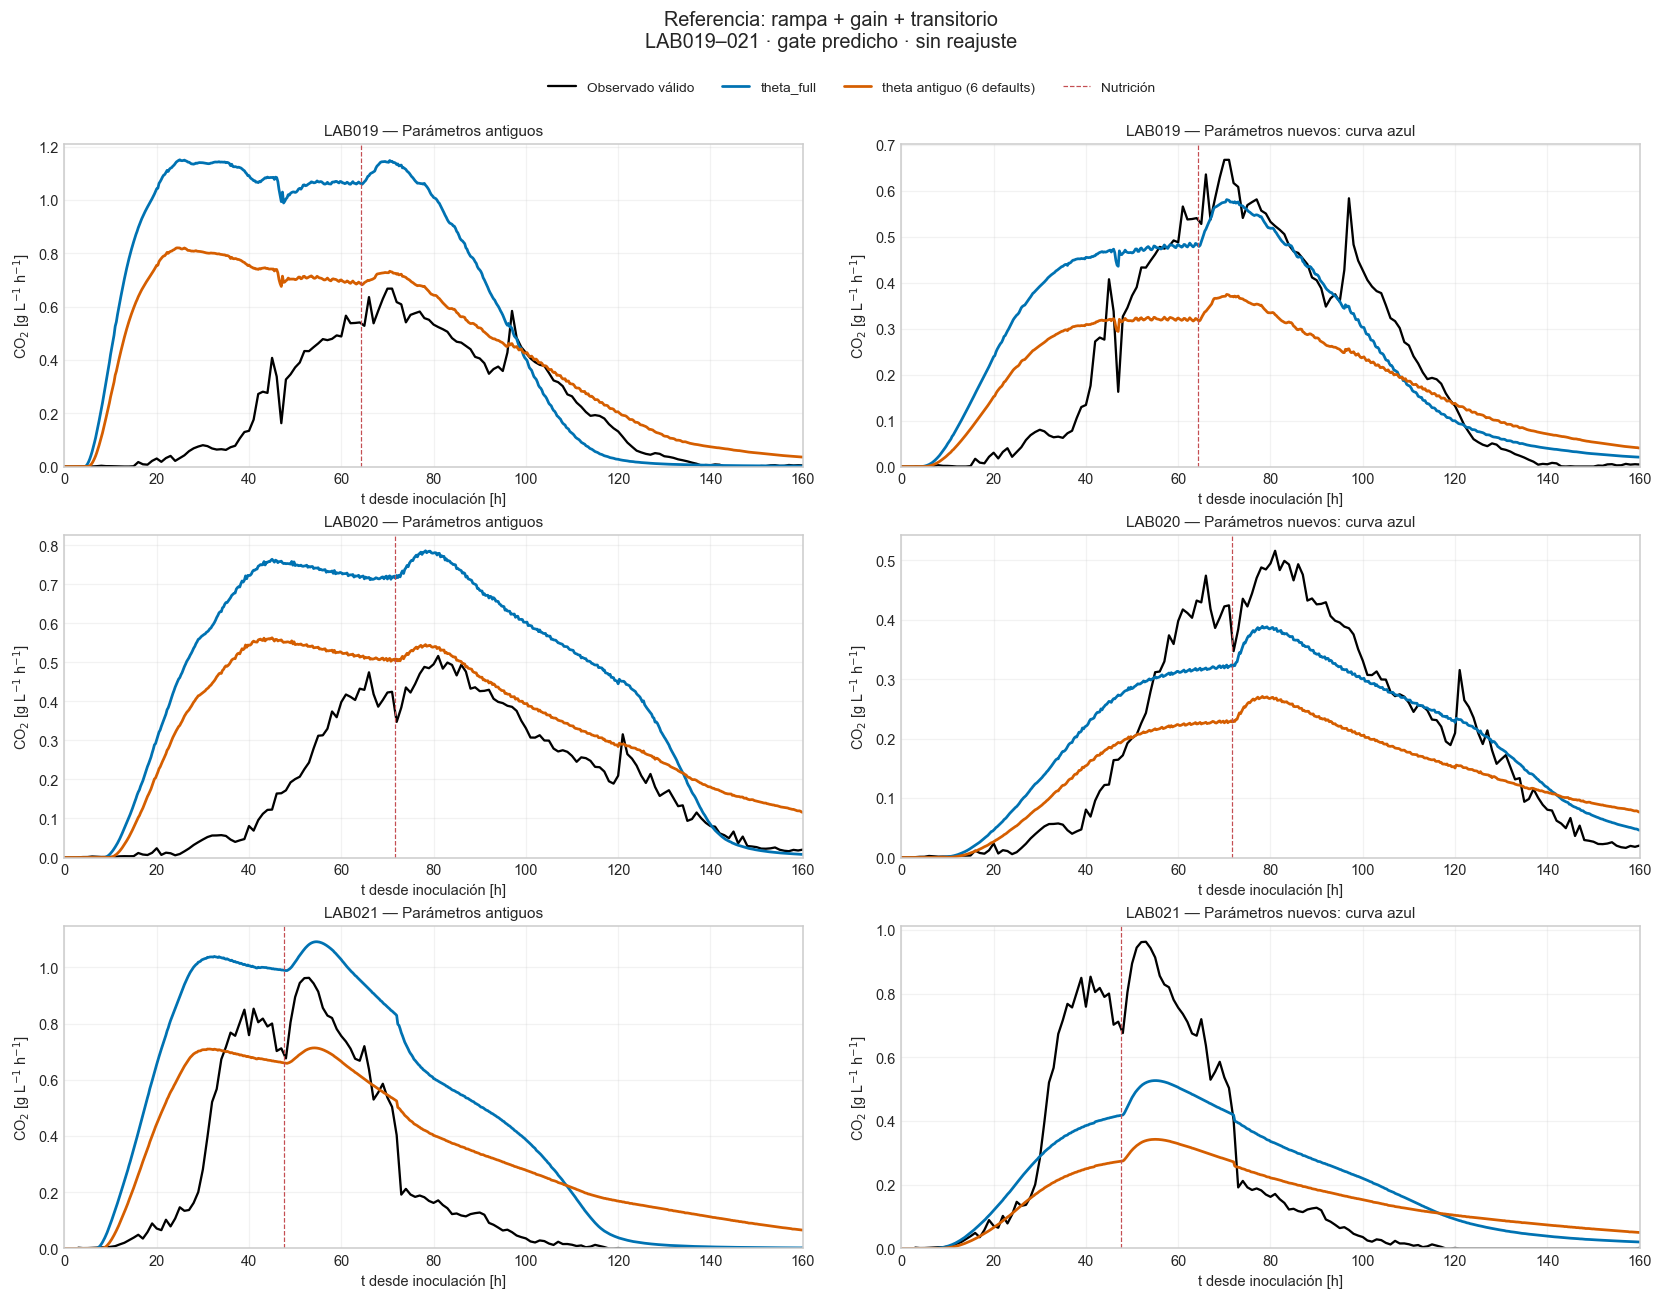

**Métricas descriptivas completas y papel de los datos:**

,lab,param_set,theta,role,RMSE_g_l_h,NRMSE_peak,onset_error_h,peak_predicted_g_l_h,AUC_relative_error
12,LAB019,antiguos,theta_full,Evaluación con parámetros históricos; datos ya...,0.5452,0.8167,-21.0,1.1508,1.6028
16,LAB020,antiguos,theta_full,Evaluación con parámetros históricos; datos ya...,0.3245,0.6285,-19.0,0.7845,1.2996
20,LAB021,antiguos,theta_full,Evaluación con parámetros históricos; datos ya...,0.3243,0.3368,-13.0,1.0908,1.0508
36,LAB019,antiguos,theta_antiguo,Evaluación con parámetros históricos; datos ya...,0.3333,0.4994,-20.0,0.8200,0.9879
40,LAB020,antiguos,theta_antiguo,Evaluación con parámetros históricos; datos ya...,0.1967,0.3809,-18.0,0.5628,0.7086
44,LAB021,antiguos,theta_antiguo,Evaluación con parámetros históricos; datos ya...,0.2047,0.2126,-11.0,0.7135,0.5249
60,LAB019,nuevos,theta_full,Datos de calibración previa de los parámetros ...,0.1370,0.2053,-16.0,0.5793,0.2100
64,LAB020,nuevos,theta_full,Datos de calibración previa de los parámetros ...,0.0716,0.1388,-11.0,0.3876,0.0245
68,LAB021,nuevos,theta_full,Datos de calibración previa de los parámetros ...,0.1902,0.1975,-5.0,0.5271,-0.0576
84,LAB019,nuevos,theta_antiguo,Datos de calibración previa de los parámetros ...,0.1391,0.2084,-14.0,0.3732,-0.1082


RMSE_g_l_h  NRMSE_peak
param_set theta         window                           
antiguos  theta_full    completo       0.3245      0.6285
                        pre_pulso      0.4456      0.8280
                        pulso_24h      0.2835      0.5491
                        cola           0.1798      0.2722
          theta_antiguo completo       0.2047      0.3809
                        pre_pulso      0.2830      0.5481
                        pulso_24h      0.1126      0.1452
                        cola           0.0866      0.1676
nuevos    theta_full    completo       0.1370      0.1975
                        pre_pulso      0.2055      0.2355
                        pulso_24h      0.0930      0.1800
                        cola           0.0649      0.0973
          theta_antiguo completo       0.1391      0.2182
                        pre_pulso      0.1428      0.2139
                        pulso_24h      0.2160      0.3890
                        cola           0.0868      0.1450

In [10]:
comparison.show_comparison(RESULT,BATCHES,OBSERVED,THETA_TABLE,PARAM_SETS,'vigente',RECENT_LABS,'gate_predicho')

## LAB019–021 — rampa + gain + transitorio antiguos, con onset manual

Se cambia únicamente el bracket del gate a **[0, onset manual]**, compartido por ambos theta. Se mantienen todos los parámetros antiguos, incluyendo O2, fracciones del gate, rampa/gain y transitorio **A=0.30, tau_r=4 h, tau_d=12 h**. La biomasa inicial, química, temperatura y nutrición siguen siendo las registradas para LAB019–021.

Los valores editables se inicializan con el onset observado publicado en `results/lab019_021_theta_full_holdout/co2_metrics.csv` (escenario `primary_end_to_end`, dominio `full`): LAB019=28 h, LAB020=32 h y LAB021=24 h. El onset es una referencia del gate, no la hora impuesta de cruce del umbral del sensor. Esta figura es un diagnóstico condicionado; no interviene en las comparaciones principales ni reajusta parámetros.

In [11]:
# EDITAR AQUÍ. Ejecutar esta celda y la figura siguiente para cambiar el onset.
RECENT_ONSET_MANUAL = {'LAB019': 28.0, 'LAB020': 32.0, 'LAB021': 24.0}
recent_onset_reference_path = REFERENCE_RESULTS_DIR / 'co2_metrics.csv'
recent_onset_reference_hash = comparison.file_hash(recent_onset_reference_path)
recent_onset_reference = pd.read_csv(recent_onset_reference_path)
recent_onset_reference = recent_onset_reference[
    recent_onset_reference.scenario.eq('primary_end_to_end') & recent_onset_reference.domain.eq('full')
][['lab','onset_observed_h']].set_index('lab')
assert set(RECENT_ONSET_MANUAL) == set(RECENT_LABS)
display(pd.DataFrame([{'lab': lab, 'onset_manual_h': RECENT_ONSET_MANUAL[lab],
    'onset_observado_publicado_h': float(recent_onset_reference.loc[lab,'onset_observed_h'])}
    for lab in RECENT_LABS]))

recent_manual_curves, recent_manual_gates, recent_manual_metrics = {}, [], []
for lab in RECENT_LABS:
    onset_h = float(RECENT_ONSET_MANUAL[lab])
    assert np.isfinite(onset_h) and 0. < onset_h < TIME_GRIDS[lab][-1], lab
    for theta_name in THETA_SETS:
        curve, gate = comparison.predict(RESULT['caches'][(lab,theta_name)], PARAM_SETS['antiguos'],
            'vigente', BATCHES[lab].pulses['N'], manual_onset=onset_h)
        original = RESULT['curves'][('gate_predicho','vigente','antiguos',theta_name,lab)]
        # Only the gate and downstream pool change; upstream biology and transient stay fixed.
        for field in ('qbio','qresp','f_ferm','O2_mg_l','transient_multiplier','csat_g_l'):
            assert np.array_equal(curve[field].to_numpy(),original[field].to_numpy()), (lab,theta_name,field)
        expected_activation = co2_cross._bounded_smoothstep_activation(TIME_GRIDS[lab],0.,onset_h,
            PARAM_SETS['antiguos']['chem_activation_start_fraction'],
            PARAM_SETS['antiguos']['chem_activation_duration_fraction'])
        assert np.array_equal(curve.activation.to_numpy(),expected_activation)
        attributes = dict(mode='onset_manual',family='vigente',param_set='antiguos',
            theta=theta_name,lab=lab,role=comparison.role_for(lab,'antiguos','onset_manual'))
        recent_manual_curves[('onset_manual','vigente','antiguos',theta_name,lab)] = curve
        recent_manual_gates.append({**attributes,**gate})
        for metric in comparison.metrics_for_curve(OBSERVED[lab],curve,BATCHES[lab].pulses['N'][0][0]):
            recent_manual_metrics.append({**attributes,**metric})
RECENT_MANUAL_RESULT = dict(curves=recent_manual_curves,gates=pd.DataFrame(recent_manual_gates),
    metrics=pd.DataFrame(recent_manual_metrics))
assert len(recent_manual_curves) == 6
assert comparison.file_hash(recent_onset_reference_path) == recent_onset_reference_hash


,lab,onset_manual_h,onset_observado_publicado_h
0,LAB019,28.0,28.0
1,LAB020,32.0,32.0
2,LAB021,24.0,24.0


**Ecuaciones de esta figura — Referencia: rampa + gain + transitorio.** Bracket **[0, onset manual observado]**: diagnóstico condicionado.

$$q_{\mathrm{bio},k}=Y_{CO_2/E}X_k\,a_\beta(T)\,\frac{1}{1+i_E(T)E_k}\left[\beta_{G0}\frac{G_k}{G_k+K_G(T)}+\beta_{F0}\frac{F_k}{F_k+K_F(T)}\frac{1}{1+i_G(T)G_k}\right],\quad k\in\{0,N\}.$$
$$K_G=\frac{\beta_{G0}}{s_G}a_K(T),\quad K_F=\frac{\beta_{F0}}{s_F}a_K(T),\quad r=\operatorname{clip}((t-t_p)/t_{rise},0,1).$$
$$ q_{\mathrm{bio}}=[(1+(g-1)r)q_{\mathrm{bio},0}+r(q_{\mathrm{bio},N}-q_{\mathrm{bio},0})]_+,\quad X_{\mathrm{eff}}=[X_0+r(X_N-X_0)]_+ $$
$$r_{O_2}=q_{O_2,max}X_{eff}\frac{O}{0.25+O},\quad \dot O=-r_{O_2},\quad O(0)=\alpha_O O_{sat}(0),\quad \phi_{ana}=\frac{0.75^2}{0.75^2+O^2},\quad f_{ferm}=0.08+0.92\phi_{ana}.$$
$$q_{resp}=\frac{44.01}{32000}r_{O_2},\quad a=3z^2-2z^3,\quad z=\operatorname{clip}\left(\frac{t-[L+s(U-L)]}{\max(d(U-L),0.25)},0,1\right).$$
$$q_{base}=a\,[f_{ferm}q_{bio}+q_{resp}],\quad q_{prod}=M_Nq_{base},\quad M_N=1+T_N,\quad T_N=A\sum_j\frac{\Delta N_j}{0.14}\frac{(1-e^{-u_j/\tau_r})e^{-u_j/\tau_d}}{\mathcal N_j},\quad u_j=\max(t-t_j,0).$$
$$C_{sat}=s_{CO_2}1.69e^{-0.032(T-20)}e^{0.0016E_N}e^{-0.0012(G_N+F_N)},\quad q_{out}=k C\left(0.05+0.95\frac{C}{C+C_{sat}}\right),\quad \dot C=q_{prod}-q_{out},\quad q_{pred}=g_{matrix}q_{out}.$$

Se integra el pool con Euler y límite de CO2 disponible; C(0)=0. En las familias con transitorio, la normalización antigua es el máximo del kernel en la grilla de este LAB; la nueva es el máximo analítico, en u*=tau_r log(1+tau_d/tau_r). La forma del gate usa sus fracciones s/d antiguas o nuevas. Las tablas siguientes muestran los valores efectivos; los parámetros retirados se marcan como «no interviene».

La actualización implementada, con h=t_i-t_(i-1), es:
$$q_{out,i}=\min\!\left[k C_{i-1}\left(0.05+0.95\frac{C_{i-1}}{C_{i-1}+C_{sat,i}}\right),\frac{C_{i-1}}{h}+q_{prod,i-1}\right],\quad C_i=[C_{i-1}+h(q_{prod,i-1}-q_{out,i})]_+.$$


,parameter,uso,antiguos
0,kCO2_release_h,activo,0.424588
1,CO2sat_scale,activo,0.35139
2,O2_qmax_mg_gdw_h,activo,0.15
3,O2_initial_scale,activo,0.1954
4,pulse_t_rise_h,activo,64.658704
5,pulse_activity_gain,activo,0.25
6,chem_activation_start_fraction,activo,0.735057
7,chem_activation_duration_fraction,activo,1.06391
8,matrix_gain,activo,3.115757
9,A,activo,0.3


**Vector cinético usado por cada color (17 parámetros):**

,parameter,theta_full,theta_antiguo
0,mu0,0.078728,0.078728
1,sN,8.751446,18.000000
2,qN,0.021080,0.021080
3,qXG,0.081491,0.112500
4,qXF,0.070933,0.112500
5,betaG0,0.428878,0.428878
6,sG,0.097455,0.030000
7,betaF0,3.440399,3.440399
8,sF,0.178295,0.030000
9,qEG,1.712807,1.712807


**Condiciones iniciales comunes y eventos de esta figura:**

,lab,X,Xd,N,G,F,E,Gly
0,LAB019,0.8595,0.029997,0.260025,79.19,78.97,12.075372,1.22
1,LAB020,0.4113,0.004607,0.255556,77.94,79.52,11.917524,1.38
2,LAB021,0.3999,0.018435,0.261202,80.19,81.04,11.759676,1.28


,lab,event_h,delta_N_kg_m3,dose_status
0,LAB019,64.333333,0.08,YAN registrado en Excel
1,LAB020,71.666667,0.08,YAN registrado en Excel
2,LAB021,47.500000,0.08,YAN registrado en Excel


,lab,param_set,theta,gate_lower_h,gate_upper_h,gate_start_h,gate_end_h
0,LAB019,antiguos,theta_full,0.0,28.0,20.5816,50.3711
1,LAB019,antiguos,theta_antiguo,0.0,28.0,20.5816,50.3711
2,LAB020,antiguos,theta_full,0.0,32.0,23.5218,57.5669
3,LAB020,antiguos,theta_antiguo,0.0,32.0,23.5218,57.5669
4,LAB021,antiguos,theta_full,0.0,24.0,17.6414,43.1752
5,LAB021,antiguos,theta_antiguo,0.0,24.0,17.6414,43.1752


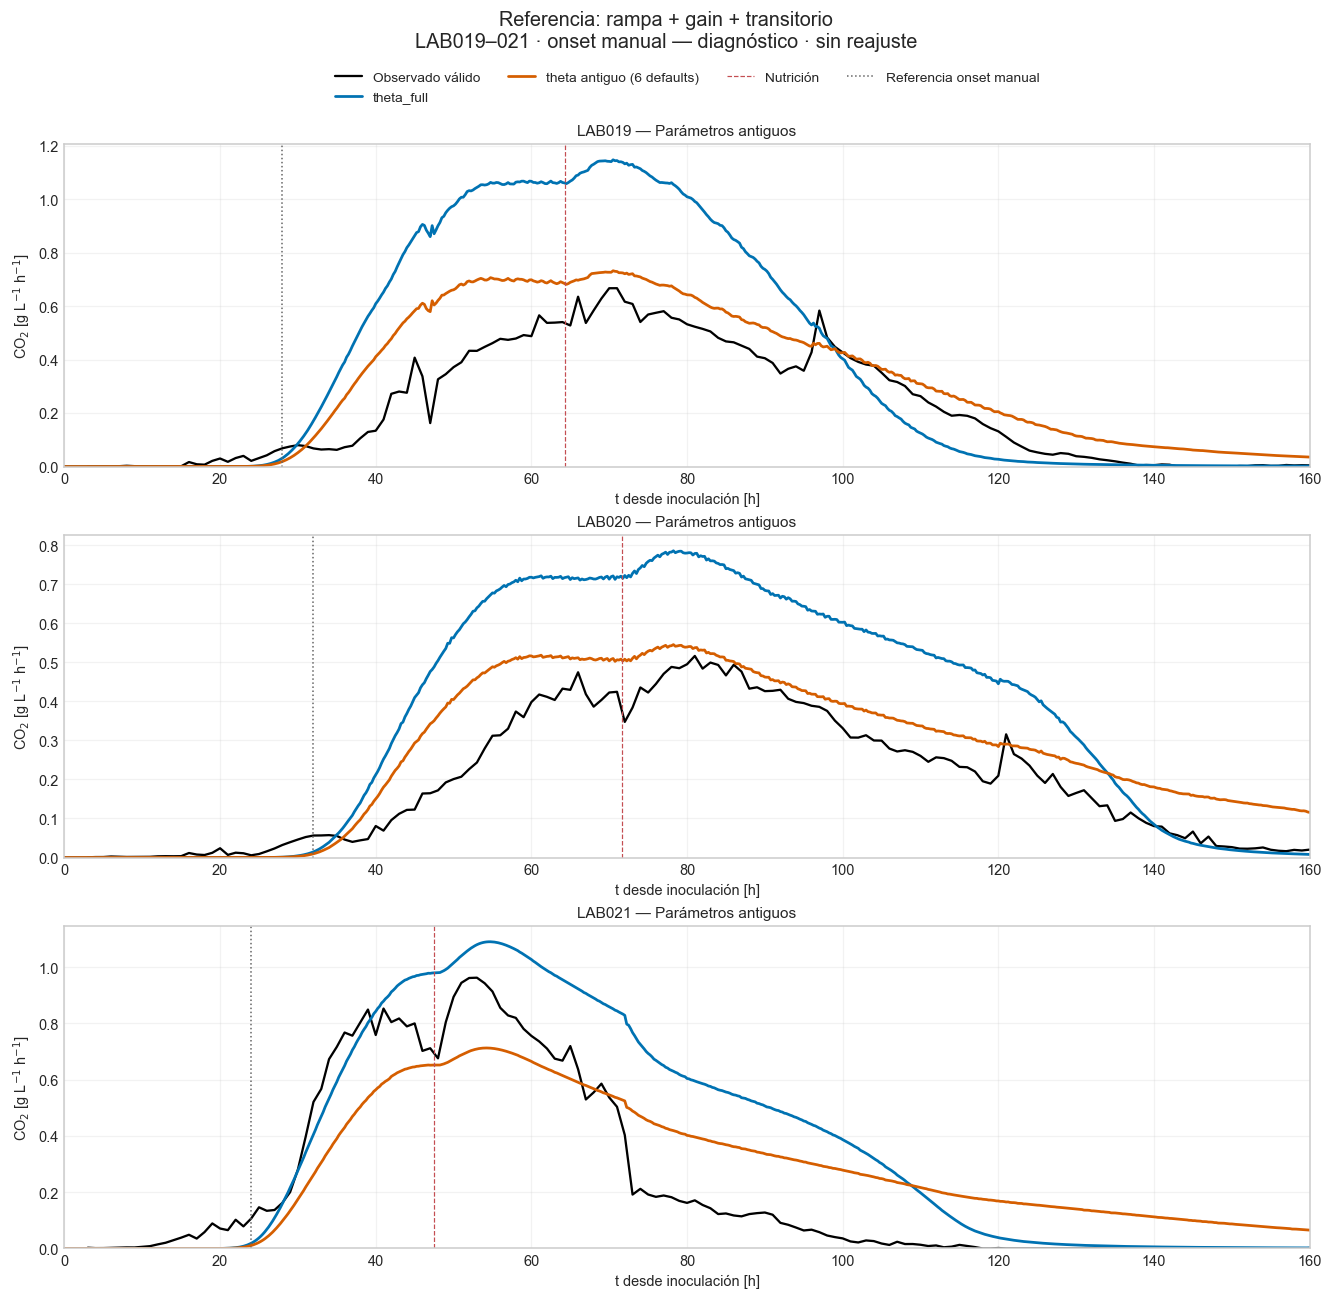

**Métricas descriptivas completas y papel de los datos:**

,lab,param_set,theta,role,RMSE_g_l_h,NRMSE_peak,onset_error_h,peak_predicted_g_l_h,AUC_relative_error
0,LAB019,antiguos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.3088,0.4626,2.0,1.1452,0.7453
4,LAB019,antiguos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.1242,0.1861,3.0,0.7299,0.3817
8,LAB020,antiguos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.2135,0.4135,3.0,0.7845,0.7963
12,LAB020,antiguos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.0906,0.1755,4.0,0.5432,0.3357
16,LAB021,antiguos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.2257,0.2344,3.0,1.0903,0.5911
20,LAB021,antiguos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.1706,0.1772,5.0,0.7128,0.2122


RMSE_g_l_h  NRMSE_peak
param_set theta         window                           
antiguos  theta_full    completo       0.2257      0.4135
                        pre_pulso      0.2144      0.4153
                        pulso_24h      0.2835      0.5491
                        cola           0.1798      0.2722
          theta_antiguo completo       0.1242      0.1772
                        pre_pulso      0.1563      0.1968
                        pulso_24h      0.1126      0.1462
                        cola           0.0866      0.1676

In [12]:
comparison.show_comparison(RECENT_MANUAL_RESULT,BATCHES,OBSERVED,THETA_TABLE,PARAM_SETS,
    'vigente',RECENT_LABS,'onset_manual',param_names=('antiguos',),manual_onsets=RECENT_ONSET_MANUAL)

## Opción 1: directa sin transitorio — LAB019–021, gate predicho

Columnas: parámetros antiguos y nuevos. Colores: theta_full y theta antiguo. Ningún parámetro se reajusta para esta figura.

**Ecuaciones de esta figura — Opción 1: nutrición directa, sin transitorio.** Bracket de G+F/E **simulados**, independiente de CO2 observado.

$$q_{\mathrm{bio},k}=Y_{CO_2/E}X_k\,a_\beta(T)\,\frac{1}{1+i_E(T)E_k}\left[\beta_{G0}\frac{G_k}{G_k+K_G(T)}+\beta_{F0}\frac{F_k}{F_k+K_F(T)}\frac{1}{1+i_G(T)G_k}\right],\quad k\in\{0,N\}.$$
$$K_G=\frac{\beta_{G0}}{s_G}a_K(T),\quad K_F=\frac{\beta_{F0}}{s_F}a_K(T),\quad r=\operatorname{clip}((t-t_p)/t_{rise},0,1).$$
$$ q_{\mathrm{bio}}=q_{\mathrm{bio},N},\quad X_{\mathrm{eff}}=X_N $$
$$r_{O_2}=q_{O_2,max}X_{eff}\frac{O}{0.25+O},\quad \dot O=-r_{O_2},\quad O(0)=\alpha_O O_{sat}(0),\quad \phi_{ana}=\frac{0.75^2}{0.75^2+O^2},\quad f_{ferm}=0.08+0.92\phi_{ana}.$$
$$q_{resp}=\frac{44.01}{32000}r_{O_2},\quad a=3z^2-2z^3,\quad z=\operatorname{clip}\left(\frac{t-[L+s(U-L)]}{\max(d(U-L),0.25)},0,1\right).$$
$$q_{base}=a\,[f_{ferm}q_{bio}+q_{resp}],\quad q_{prod}=M_Nq_{base},\quad M_N=1,\quad T_N=0,\quad A=0.$$
$$C_{sat}=s_{CO_2}1.69e^{-0.032(T-20)}e^{0.0016E_N}e^{-0.0012(G_N+F_N)},\quad q_{out}=k C\left(0.05+0.95\frac{C}{C+C_{sat}}\right),\quad \dot C=q_{prod}-q_{out},\quad q_{pred}=g_{matrix}q_{out}.$$

Se integra el pool con Euler y límite de CO2 disponible; C(0)=0. En las familias con transitorio, la normalización antigua es el máximo del kernel en la grilla de este LAB; la nueva es el máximo analítico, en u*=tau_r log(1+tau_d/tau_r). La forma del gate usa sus fracciones s/d antiguas o nuevas. Las tablas siguientes muestran los valores efectivos; los parámetros retirados se marcan como «no interviene».

La actualización implementada, con h=t_i-t_(i-1), es:
$$q_{out,i}=\min\!\left[k C_{i-1}\left(0.05+0.95\frac{C_{i-1}}{C_{i-1}+C_{sat,i}}\right),\frac{C_{i-1}}{h}+q_{prod,i-1}\right],\quad C_i=[C_{i-1}+h(q_{prod,i-1}-q_{out,i})]_+.$$


,parameter,uso,antiguos,nuevos
0,kCO2_release_h,activo,0.424588,0.096958
1,CO2sat_scale,activo,0.35139,2.5
2,O2_qmax_mg_gdw_h,activo,0.15,0.253137
3,O2_initial_scale,activo,0.1954,0.179606
4,pulse_t_rise_h,no interviene,—,—
5,pulse_activity_gain,no interviene,—,—
6,chem_activation_start_fraction,activo,0.735057,0.741575
7,chem_activation_duration_fraction,activo,1.06391,0.457773
8,matrix_gain,activo,3.115757,1.446718
9,A,no interviene,0 (M_N=1),0 (M_N=1)


**Vector cinético usado por cada color (17 parámetros):**

,parameter,theta_full,theta_antiguo
0,mu0,0.078728,0.078728
1,sN,8.751446,18.000000
2,qN,0.021080,0.021080
3,qXG,0.081491,0.112500
4,qXF,0.070933,0.112500
5,betaG0,0.428878,0.428878
6,sG,0.097455,0.030000
7,betaF0,3.440399,3.440399
8,sF,0.178295,0.030000
9,qEG,1.712807,1.712807


**Condiciones iniciales comunes y eventos de esta figura:**

,lab,X,Xd,N,G,F,E,Gly
0,LAB019,0.8595,0.029997,0.260025,79.19,78.97,12.075372,1.22
1,LAB020,0.4113,0.004607,0.255556,77.94,79.52,11.917524,1.38
2,LAB021,0.3999,0.018435,0.261202,80.19,81.04,11.759676,1.28


,lab,event_h,delta_N_kg_m3,dose_status
0,LAB019,64.333333,0.08,YAN registrado en Excel
1,LAB020,71.666667,0.08,YAN registrado en Excel
2,LAB021,47.500000,0.08,YAN registrado en Excel


,lab,param_set,theta,gate_lower_h,gate_upper_h,gate_start_h,gate_end_h
27,LAB019,antiguos,theta_full,3.75,4.00,3.9338,4.1997
28,LAB020,antiguos,theta_full,8.00,8.25,8.1838,8.4497
29,LAB021,antiguos,theta_full,6.25,6.50,6.4338,6.6997
33,LAB019,antiguos,theta_antiguo,4.50,4.75,4.6838,4.9497
34,LAB020,antiguos,theta_antiguo,9.25,9.50,9.4338,9.6997
35,LAB021,antiguos,theta_antiguo,7.50,7.75,7.6838,7.9497
39,LAB019,nuevos,theta_full,3.75,4.00,3.9354,4.1854
40,LAB020,nuevos,theta_full,8.00,8.25,8.1854,8.4354
41,LAB021,nuevos,theta_full,6.25,6.50,6.4354,6.6854
45,LAB019,nuevos,theta_antiguo,4.50,4.75,4.6854,4.9354


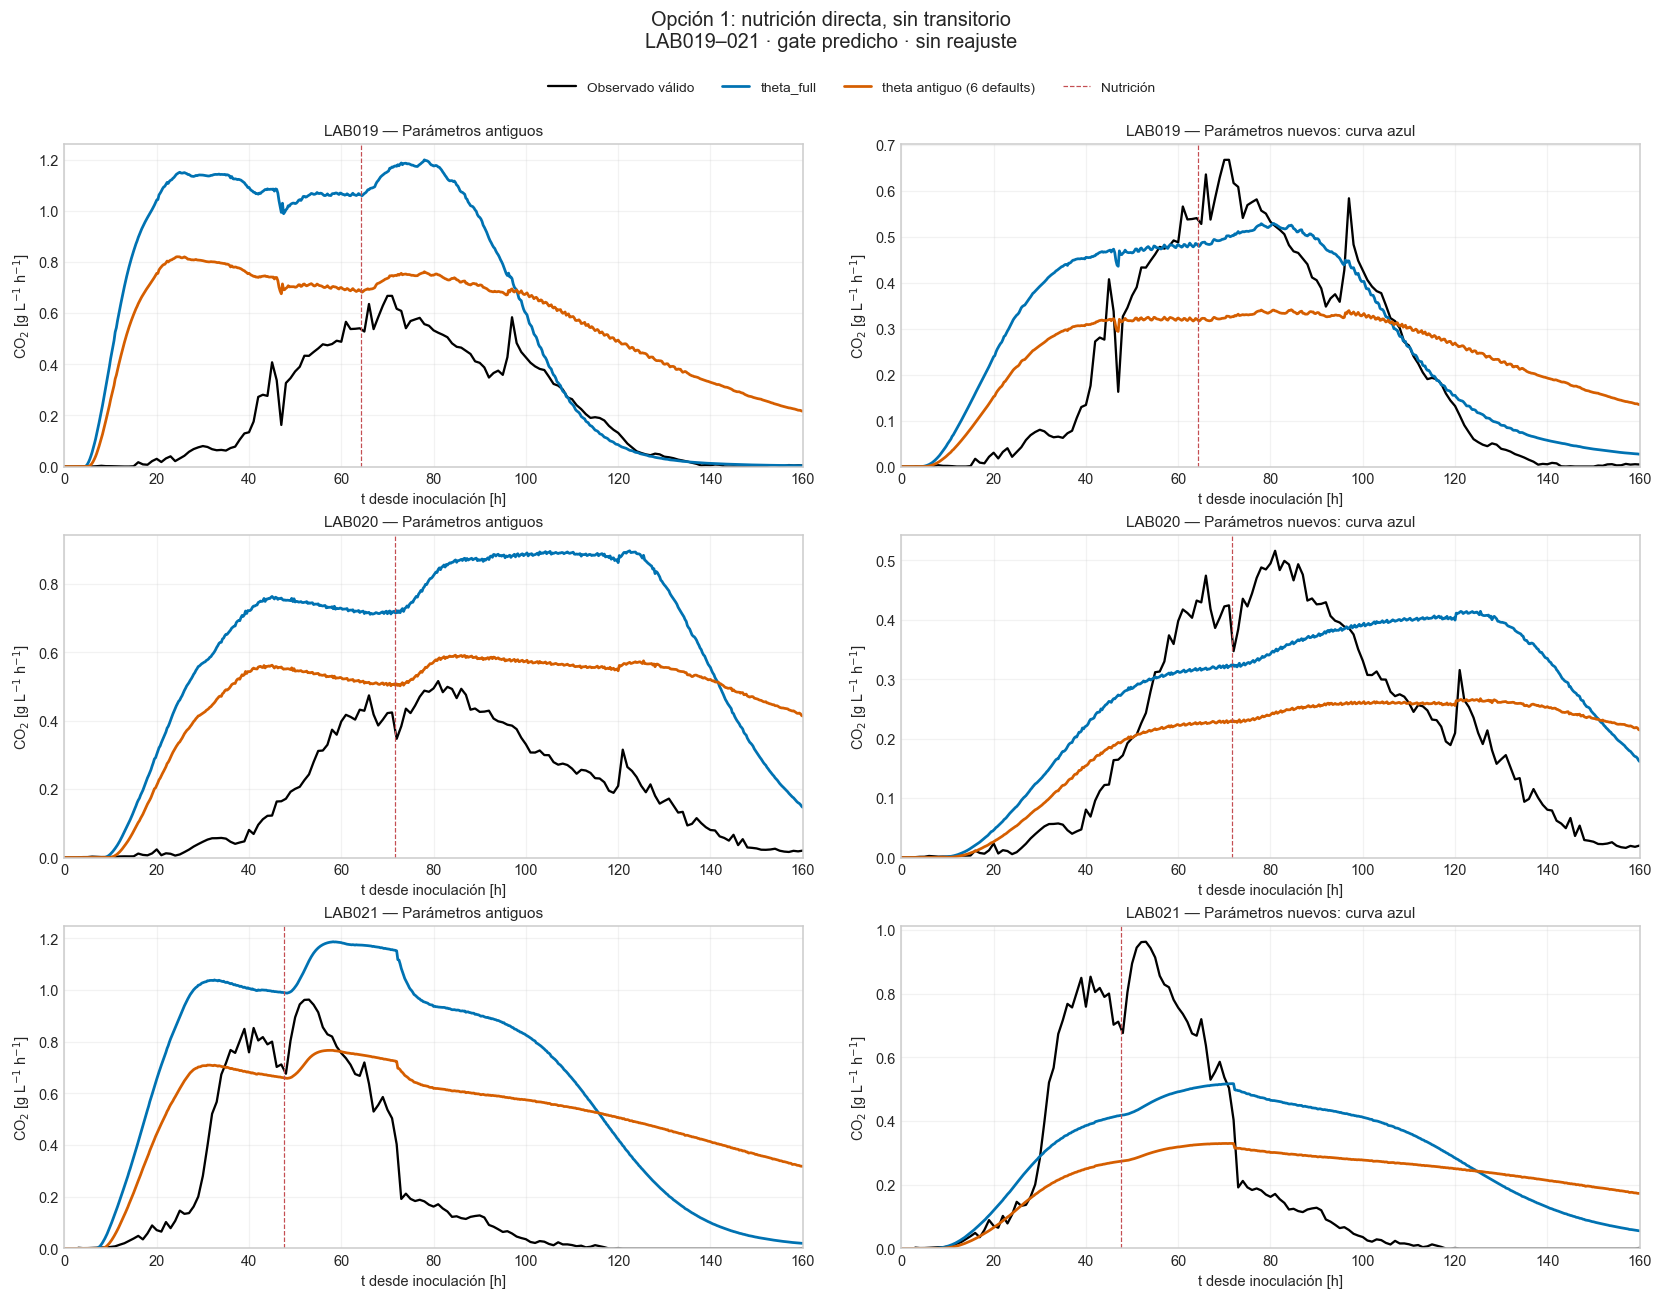

**Métricas descriptivas completas y papel de los datos:**

,lab,param_set,theta,role,RMSE_g_l_h,NRMSE_peak,onset_error_h,peak_predicted_g_l_h,AUC_relative_error
108,LAB019,antiguos,theta_full,Evaluación con parámetros históricos; datos ya...,0.5683,0.8513,-21.0,1.1995,1.8333
112,LAB020,antiguos,theta_full,Evaluación con parámetros históricos; datos ya...,0.4668,0.9041,-19.0,0.8945,2.1283
116,LAB021,antiguos,theta_full,Evaluación con parámetros históricos; datos ya...,0.5083,0.5279,-13.0,1.1860,1.8278
132,LAB019,antiguos,theta_antiguo,Evaluación con parámetros históricos; datos ya...,0.3961,0.5934,-20.0,0.8200,1.5416
136,LAB020,antiguos,theta_antiguo,Evaluación con parámetros históricos; datos ya...,0.3045,0.5897,-18.0,0.5913,1.3229
140,LAB021,antiguos,theta_antiguo,Evaluación con parámetros históricos; datos ya...,0.3802,0.3949,-11.0,0.7664,1.2829
156,LAB019,nuevos,theta_full,Datos de calibración previa de los parámetros ...,0.1369,0.2051,-16.0,0.5285,0.2993
160,LAB020,nuevos,theta_full,Datos de calibración previa de los parámetros ...,0.1400,0.2711,-11.0,0.4129,0.3558
164,LAB021,nuevos,theta_full,Datos de calibración previa de los parámetros ...,0.2647,0.2749,-5.0,0.5171,0.2788
180,LAB019,nuevos,theta_antiguo,Datos de calibración previa de los parámetros ...,0.1592,0.2385,-14.0,0.3407,0.1077


RMSE_g_l_h  NRMSE_peak
param_set theta         window                           
antiguos  theta_full    completo       0.5083      0.8513
                        pre_pulso      0.4456      0.8280
                        pulso_24h      0.4250      0.7497
                        cola           0.5295      0.5779
          theta_antiguo completo       0.3802      0.5897
                        pre_pulso      0.2830      0.5481
                        pulso_24h      0.1499      0.2405
                        cola           0.3669      0.4821
nuevos    theta_full    completo       0.1400      0.2711
                        pre_pulso      0.2055      0.2355
                        pulso_24h      0.1054      0.2042
                        cola           0.1882      0.2768
          theta_antiguo completo       0.1592      0.2568
                        pre_pulso      0.1428      0.2139
                        pulso_24h      0.2309      0.4013
                        cola           0.1425      0.2185

In [13]:
comparison.show_comparison(RESULT,BATCHES,OBSERVED,THETA_TABLE,PARAM_SETS,'directa',RECENT_LABS,'gate_predicho')

## Opción 2: directa con transitorio — LAB019–021, gate predicho

Columnas: parámetros antiguos y nuevos. Colores: theta_full y theta antiguo. Ningún parámetro se reajusta para esta figura.

**Ecuaciones de esta figura — Opción 2: nutrición directa + transitorio.** Bracket de G+F/E **simulados**, independiente de CO2 observado.

$$q_{\mathrm{bio},k}=Y_{CO_2/E}X_k\,a_\beta(T)\,\frac{1}{1+i_E(T)E_k}\left[\beta_{G0}\frac{G_k}{G_k+K_G(T)}+\beta_{F0}\frac{F_k}{F_k+K_F(T)}\frac{1}{1+i_G(T)G_k}\right],\quad k\in\{0,N\}.$$
$$K_G=\frac{\beta_{G0}}{s_G}a_K(T),\quad K_F=\frac{\beta_{F0}}{s_F}a_K(T),\quad r=\operatorname{clip}((t-t_p)/t_{rise},0,1).$$
$$ q_{\mathrm{bio}}=q_{\mathrm{bio},N},\quad X_{\mathrm{eff}}=X_N $$
$$r_{O_2}=q_{O_2,max}X_{eff}\frac{O}{0.25+O},\quad \dot O=-r_{O_2},\quad O(0)=\alpha_O O_{sat}(0),\quad \phi_{ana}=\frac{0.75^2}{0.75^2+O^2},\quad f_{ferm}=0.08+0.92\phi_{ana}.$$
$$q_{resp}=\frac{44.01}{32000}r_{O_2},\quad a=3z^2-2z^3,\quad z=\operatorname{clip}\left(\frac{t-[L+s(U-L)]}{\max(d(U-L),0.25)},0,1\right).$$
$$q_{base}=a\,[f_{ferm}q_{bio}+q_{resp}],\quad q_{prod}=M_Nq_{base},\quad M_N=1+T_N,\quad T_N=A\sum_j\frac{\Delta N_j}{0.14}\frac{(1-e^{-u_j/\tau_r})e^{-u_j/\tau_d}}{\mathcal N_j},\quad u_j=\max(t-t_j,0).$$
$$C_{sat}=s_{CO_2}1.69e^{-0.032(T-20)}e^{0.0016E_N}e^{-0.0012(G_N+F_N)},\quad q_{out}=k C\left(0.05+0.95\frac{C}{C+C_{sat}}\right),\quad \dot C=q_{prod}-q_{out},\quad q_{pred}=g_{matrix}q_{out}.$$

Se integra el pool con Euler y límite de CO2 disponible; C(0)=0. En las familias con transitorio, la normalización antigua es el máximo del kernel en la grilla de este LAB; la nueva es el máximo analítico, en u*=tau_r log(1+tau_d/tau_r). La forma del gate usa sus fracciones s/d antiguas o nuevas. Las tablas siguientes muestran los valores efectivos; los parámetros retirados se marcan como «no interviene».

La actualización implementada, con h=t_i-t_(i-1), es:
$$q_{out,i}=\min\!\left[k C_{i-1}\left(0.05+0.95\frac{C_{i-1}}{C_{i-1}+C_{sat,i}}\right),\frac{C_{i-1}}{h}+q_{prod,i-1}\right],\quad C_i=[C_{i-1}+h(q_{prod,i-1}-q_{out,i})]_+.$$


,parameter,uso,antiguos,nuevos
0,kCO2_release_h,activo,0.424588,0.096958
1,CO2sat_scale,activo,0.35139,2.5
2,O2_qmax_mg_gdw_h,activo,0.15,0.253137
3,O2_initial_scale,activo,0.1954,0.179606
4,pulse_t_rise_h,no interviene,—,—
5,pulse_activity_gain,no interviene,—,—
6,chem_activation_start_fraction,activo,0.735057,0.741575
7,chem_activation_duration_fraction,activo,1.06391,0.457773
8,matrix_gain,activo,3.115757,1.446718
9,A,activo,0.3,1.5


**Vector cinético usado por cada color (17 parámetros):**

,parameter,theta_full,theta_antiguo
0,mu0,0.078728,0.078728
1,sN,8.751446,18.000000
2,qN,0.021080,0.021080
3,qXG,0.081491,0.112500
4,qXF,0.070933,0.112500
5,betaG0,0.428878,0.428878
6,sG,0.097455,0.030000
7,betaF0,3.440399,3.440399
8,sF,0.178295,0.030000
9,qEG,1.712807,1.712807


**Condiciones iniciales comunes y eventos de esta figura:**

,lab,X,Xd,N,G,F,E,Gly
0,LAB019,0.8595,0.029997,0.260025,79.19,78.97,12.075372,1.22
1,LAB020,0.4113,0.004607,0.255556,77.94,79.52,11.917524,1.38
2,LAB021,0.3999,0.018435,0.261202,80.19,81.04,11.759676,1.28


,lab,event_h,delta_N_kg_m3,dose_status
0,LAB019,64.333333,0.08,YAN registrado en Excel
1,LAB020,71.666667,0.08,YAN registrado en Excel
2,LAB021,47.500000,0.08,YAN registrado en Excel


,lab,param_set,theta,gate_lower_h,gate_upper_h,gate_start_h,gate_end_h
51,LAB019,antiguos,theta_full,3.75,4.00,3.9338,4.1997
52,LAB020,antiguos,theta_full,8.00,8.25,8.1838,8.4497
53,LAB021,antiguos,theta_full,6.25,6.50,6.4338,6.6997
57,LAB019,antiguos,theta_antiguo,4.50,4.75,4.6838,4.9497
58,LAB020,antiguos,theta_antiguo,9.25,9.50,9.4338,9.6997
59,LAB021,antiguos,theta_antiguo,7.50,7.75,7.6838,7.9497
63,LAB019,nuevos,theta_full,3.75,4.00,3.9354,4.1854
64,LAB020,nuevos,theta_full,8.00,8.25,8.1854,8.4354
65,LAB021,nuevos,theta_full,6.25,6.50,6.4354,6.6854
69,LAB019,nuevos,theta_antiguo,4.50,4.75,4.6854,4.9354


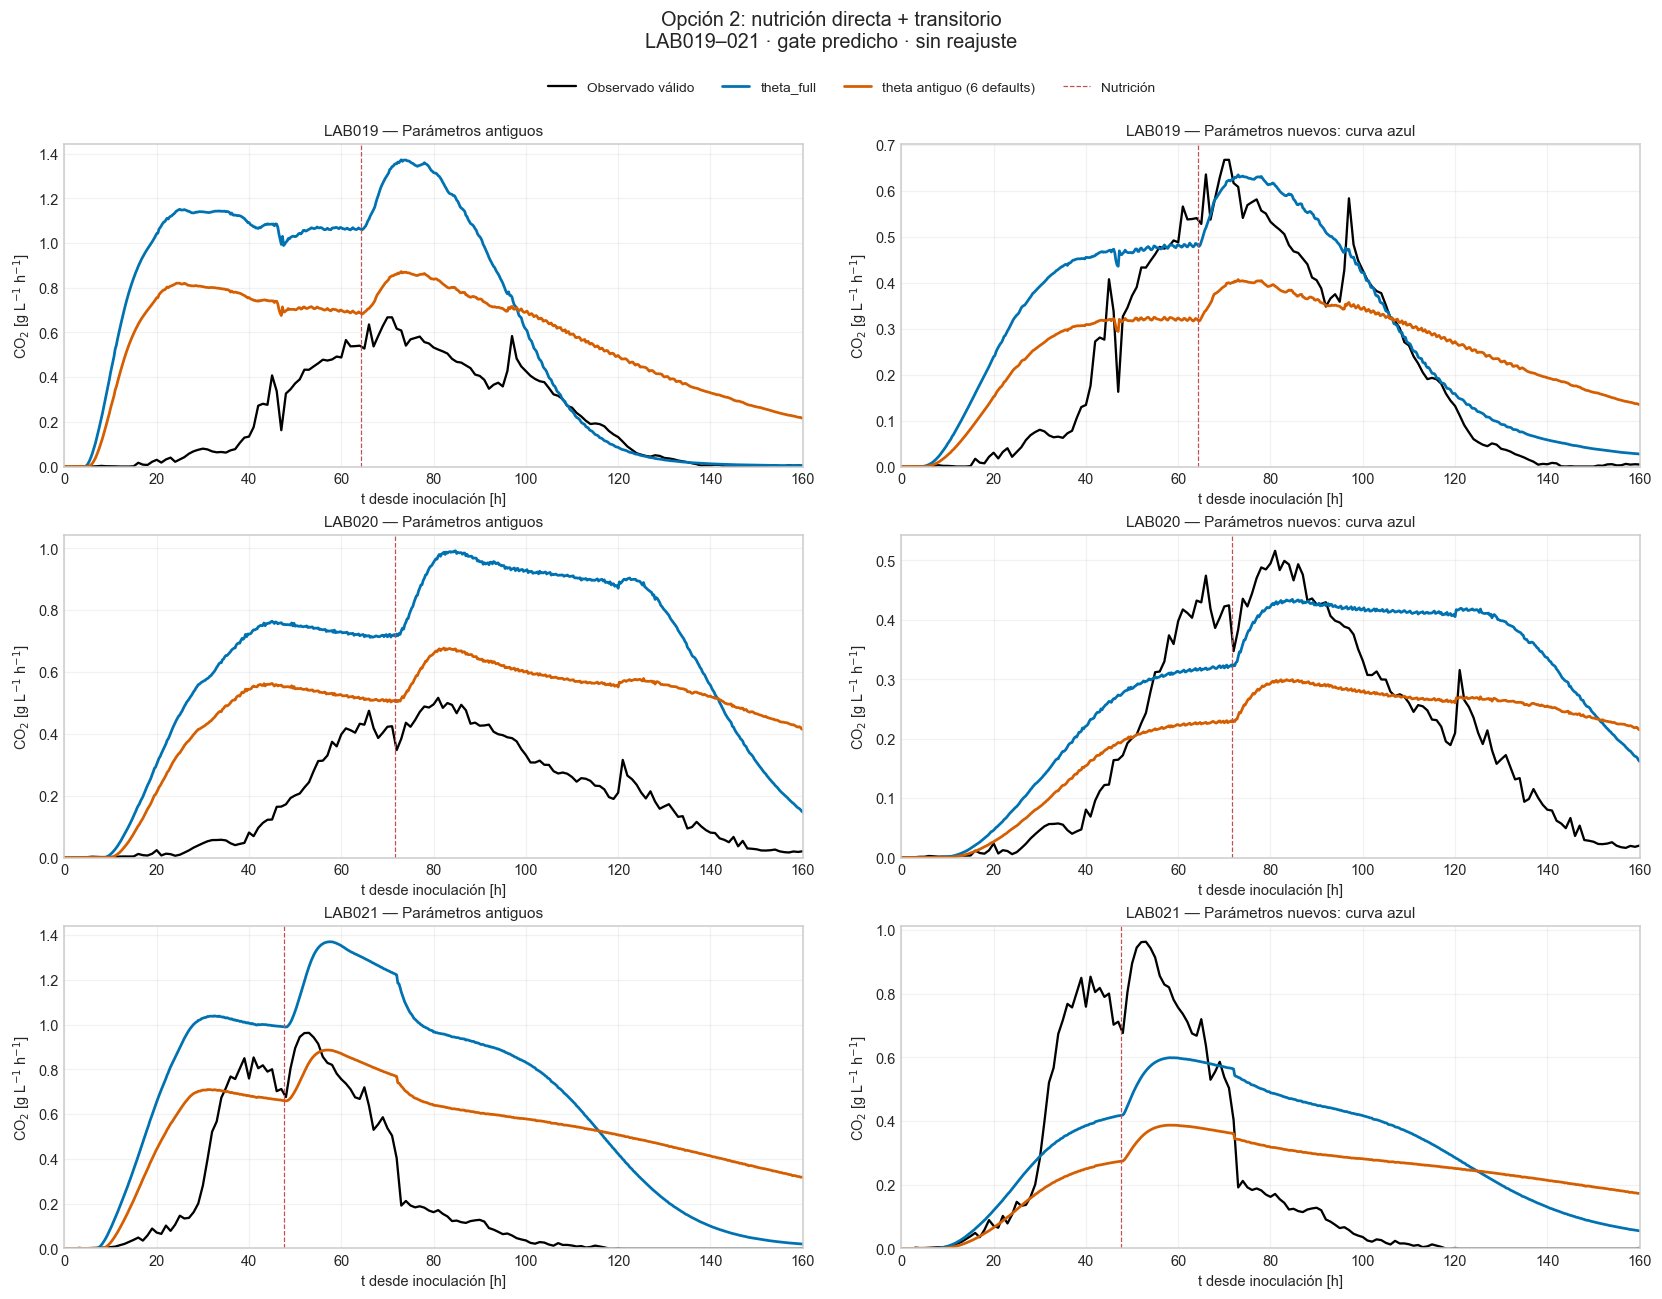

**Métricas descriptivas completas y papel de los datos:**

,lab,param_set,theta,role,RMSE_g_l_h,NRMSE_peak,onset_error_h,peak_predicted_g_l_h,AUC_relative_error
204,LAB019,antiguos,theta_full,Evaluación con parámetros históricos; datos ya...,0.5916,0.8863,-21.0,1.3723,1.9295
208,LAB020,antiguos,theta_full,Evaluación con parámetros históricos; datos ya...,0.4843,0.9380,-19.0,0.9884,2.2163
212,LAB021,antiguos,theta_full,Evaluación con parámetros históricos; datos ya...,0.5319,0.5524,-13.0,1.3688,1.9285
228,LAB019,antiguos,theta_antiguo,Evaluación con parámetros históricos; datos ya...,0.4051,0.6069,-20.0,0.8724,1.6082
232,LAB020,antiguos,theta_antiguo,Evaluación con parámetros históricos; datos ya...,0.3113,0.6030,-18.0,0.6744,1.3822
236,LAB021,antiguos,theta_antiguo,Evaluación con parámetros históricos; datos ya...,0.3849,0.3997,-11.0,0.8861,1.3483
252,LAB019,nuevos,theta_full,Datos de calibración previa de los parámetros ...,0.1377,0.2063,-16.0,0.6348,0.3743
256,LAB020,nuevos,theta_full,Datos de calibración previa de los parámetros ...,0.1378,0.2668,-11.0,0.4337,0.4139
260,LAB021,nuevos,theta_full,Datos de calibración previa de los parámetros ...,0.2572,0.2671,-5.0,0.5987,0.3496
276,LAB019,nuevos,theta_antiguo,Datos de calibración previa de los parámetros ...,0.1483,0.2221,-14.0,0.4068,0.1557


RMSE_g_l_h  NRMSE_peak
param_set theta         window                           
antiguos  theta_full    completo       0.5319      0.8863
                        pre_pulso      0.4456      0.8280
                        pulso_24h      0.5413      0.9198
                        cola           0.5412      0.5901
          theta_antiguo completo       0.3849      0.6030
                        pre_pulso      0.2830      0.5481
                        pulso_24h      0.1808      0.3502
                        cola           0.3722      0.4879
nuevos    theta_full    completo       0.1378      0.2668
                        pre_pulso      0.2055      0.2355
                        pulso_24h      0.0761      0.1140
                        cola           0.1926      0.2847
          theta_antiguo completo       0.1483      0.2393
                        pre_pulso      0.1428      0.2139
                        pulso_24h      0.1786      0.3250
                        cola           0.1416      0.2220

In [14]:
comparison.show_comparison(RESULT,BATCHES,OBSERVED,THETA_TABLE,PARAM_SETS,'directa_transitorio',RECENT_LABS,'gate_predicho')

## Referencia vigente — LAB016–018, gate predicho

Columnas: parámetros antiguos y nuevos. Colores: theta_full y theta antiguo. Ningún parámetro se reajusta para esta figura.

**Ecuaciones de esta figura — Referencia: rampa + gain + transitorio.** Bracket de G+F/E **simulados**, independiente de CO2 observado.

$$q_{\mathrm{bio},k}=Y_{CO_2/E}X_k\,a_\beta(T)\,\frac{1}{1+i_E(T)E_k}\left[\beta_{G0}\frac{G_k}{G_k+K_G(T)}+\beta_{F0}\frac{F_k}{F_k+K_F(T)}\frac{1}{1+i_G(T)G_k}\right],\quad k\in\{0,N\}.$$
$$K_G=\frac{\beta_{G0}}{s_G}a_K(T),\quad K_F=\frac{\beta_{F0}}{s_F}a_K(T),\quad r=\operatorname{clip}((t-t_p)/t_{rise},0,1).$$
$$ q_{\mathrm{bio}}=[(1+(g-1)r)q_{\mathrm{bio},0}+r(q_{\mathrm{bio},N}-q_{\mathrm{bio},0})]_+,\quad X_{\mathrm{eff}}=[X_0+r(X_N-X_0)]_+ $$
$$r_{O_2}=q_{O_2,max}X_{eff}\frac{O}{0.25+O},\quad \dot O=-r_{O_2},\quad O(0)=\alpha_O O_{sat}(0),\quad \phi_{ana}=\frac{0.75^2}{0.75^2+O^2},\quad f_{ferm}=0.08+0.92\phi_{ana}.$$
$$q_{resp}=\frac{44.01}{32000}r_{O_2},\quad a=3z^2-2z^3,\quad z=\operatorname{clip}\left(\frac{t-[L+s(U-L)]}{\max(d(U-L),0.25)},0,1\right).$$
$$q_{base}=a\,[f_{ferm}q_{bio}+q_{resp}],\quad q_{prod}=M_Nq_{base},\quad M_N=1+T_N,\quad T_N=A\sum_j\frac{\Delta N_j}{0.14}\frac{(1-e^{-u_j/\tau_r})e^{-u_j/\tau_d}}{\mathcal N_j},\quad u_j=\max(t-t_j,0).$$
$$C_{sat}=s_{CO_2}1.69e^{-0.032(T-20)}e^{0.0016E_N}e^{-0.0012(G_N+F_N)},\quad q_{out}=k C\left(0.05+0.95\frac{C}{C+C_{sat}}\right),\quad \dot C=q_{prod}-q_{out},\quad q_{pred}=g_{matrix}q_{out}.$$

Se integra el pool con Euler y límite de CO2 disponible; C(0)=0. En las familias con transitorio, la normalización antigua es el máximo del kernel en la grilla de este LAB; la nueva es el máximo analítico, en u*=tau_r log(1+tau_d/tau_r). La forma del gate usa sus fracciones s/d antiguas o nuevas. Las tablas siguientes muestran los valores efectivos; los parámetros retirados se marcan como «no interviene».

La actualización implementada, con h=t_i-t_(i-1), es:
$$q_{out,i}=\min\!\left[k C_{i-1}\left(0.05+0.95\frac{C_{i-1}}{C_{i-1}+C_{sat,i}}\right),\frac{C_{i-1}}{h}+q_{prod,i-1}\right],\quad C_i=[C_{i-1}+h(q_{prod,i-1}-q_{out,i})]_+.$$


,parameter,uso,antiguos,nuevos
0,kCO2_release_h,activo,0.424588,0.096958
1,CO2sat_scale,activo,0.35139,2.5
2,O2_qmax_mg_gdw_h,activo,0.15,0.253137
3,O2_initial_scale,activo,0.1954,0.179606
4,pulse_t_rise_h,activo,64.658704,56.741847
5,pulse_activity_gain,activo,0.25,0.250011
6,chem_activation_start_fraction,activo,0.735057,0.741575
7,chem_activation_duration_fraction,activo,1.06391,0.457773
8,matrix_gain,activo,3.115757,1.446718
9,A,activo,0.3,1.5


**Vector cinético usado por cada color (17 parámetros):**

,parameter,theta_full,theta_antiguo
0,mu0,0.078728,0.078728
1,sN,8.751446,18.000000
2,qN,0.021080,0.021080
3,qXG,0.081491,0.112500
4,qXF,0.070933,0.112500
5,betaG0,0.428878,0.428878
6,sG,0.097455,0.030000
7,betaF0,3.440399,3.440399
8,sF,0.178295,0.030000
9,qEG,1.712807,1.712807


**Condiciones iniciales comunes y eventos de esta figura:**

,lab,X,Xd,N,G,F,E,Gly
0,LAB016,0.45,0.0,0.24433,74.05,77.73,0.0,1.14
1,LAB017,0.45,0.0,0.24433,74.05,77.73,0.0,1.14
2,LAB018,0.45,0.0,0.24433,74.05,77.73,0.0,1.14


,lab,event_h,delta_N_kg_m3,dose_status
0,LAB016,56.935556,0.14,referencia supuesta
1,LAB017,56.933611,0.14,referencia supuesta
2,LAB017,57.133889,0.14,referencia supuesta
3,LAB018,56.931667,0.14,referencia supuesta


,lab,param_set,theta,gate_lower_h,gate_upper_h,gate_start_h,gate_end_h
0,LAB016,antiguos,theta_full,4.25,4.5,4.4338,4.6997
1,LAB017,antiguos,theta_full,4.25,4.5,4.4338,4.6997
2,LAB018,antiguos,theta_full,4.25,4.5,4.4338,4.6997
6,LAB016,antiguos,theta_antiguo,5.25,5.5,5.4338,5.6997
7,LAB017,antiguos,theta_antiguo,5.25,5.5,5.4338,5.6997
8,LAB018,antiguos,theta_antiguo,5.25,5.5,5.4338,5.6997
12,LAB016,nuevos,theta_full,4.25,4.5,4.4354,4.6854
13,LAB017,nuevos,theta_full,4.25,4.5,4.4354,4.6854
14,LAB018,nuevos,theta_full,4.25,4.5,4.4354,4.6854
18,LAB016,nuevos,theta_antiguo,5.25,5.5,5.4354,5.6854


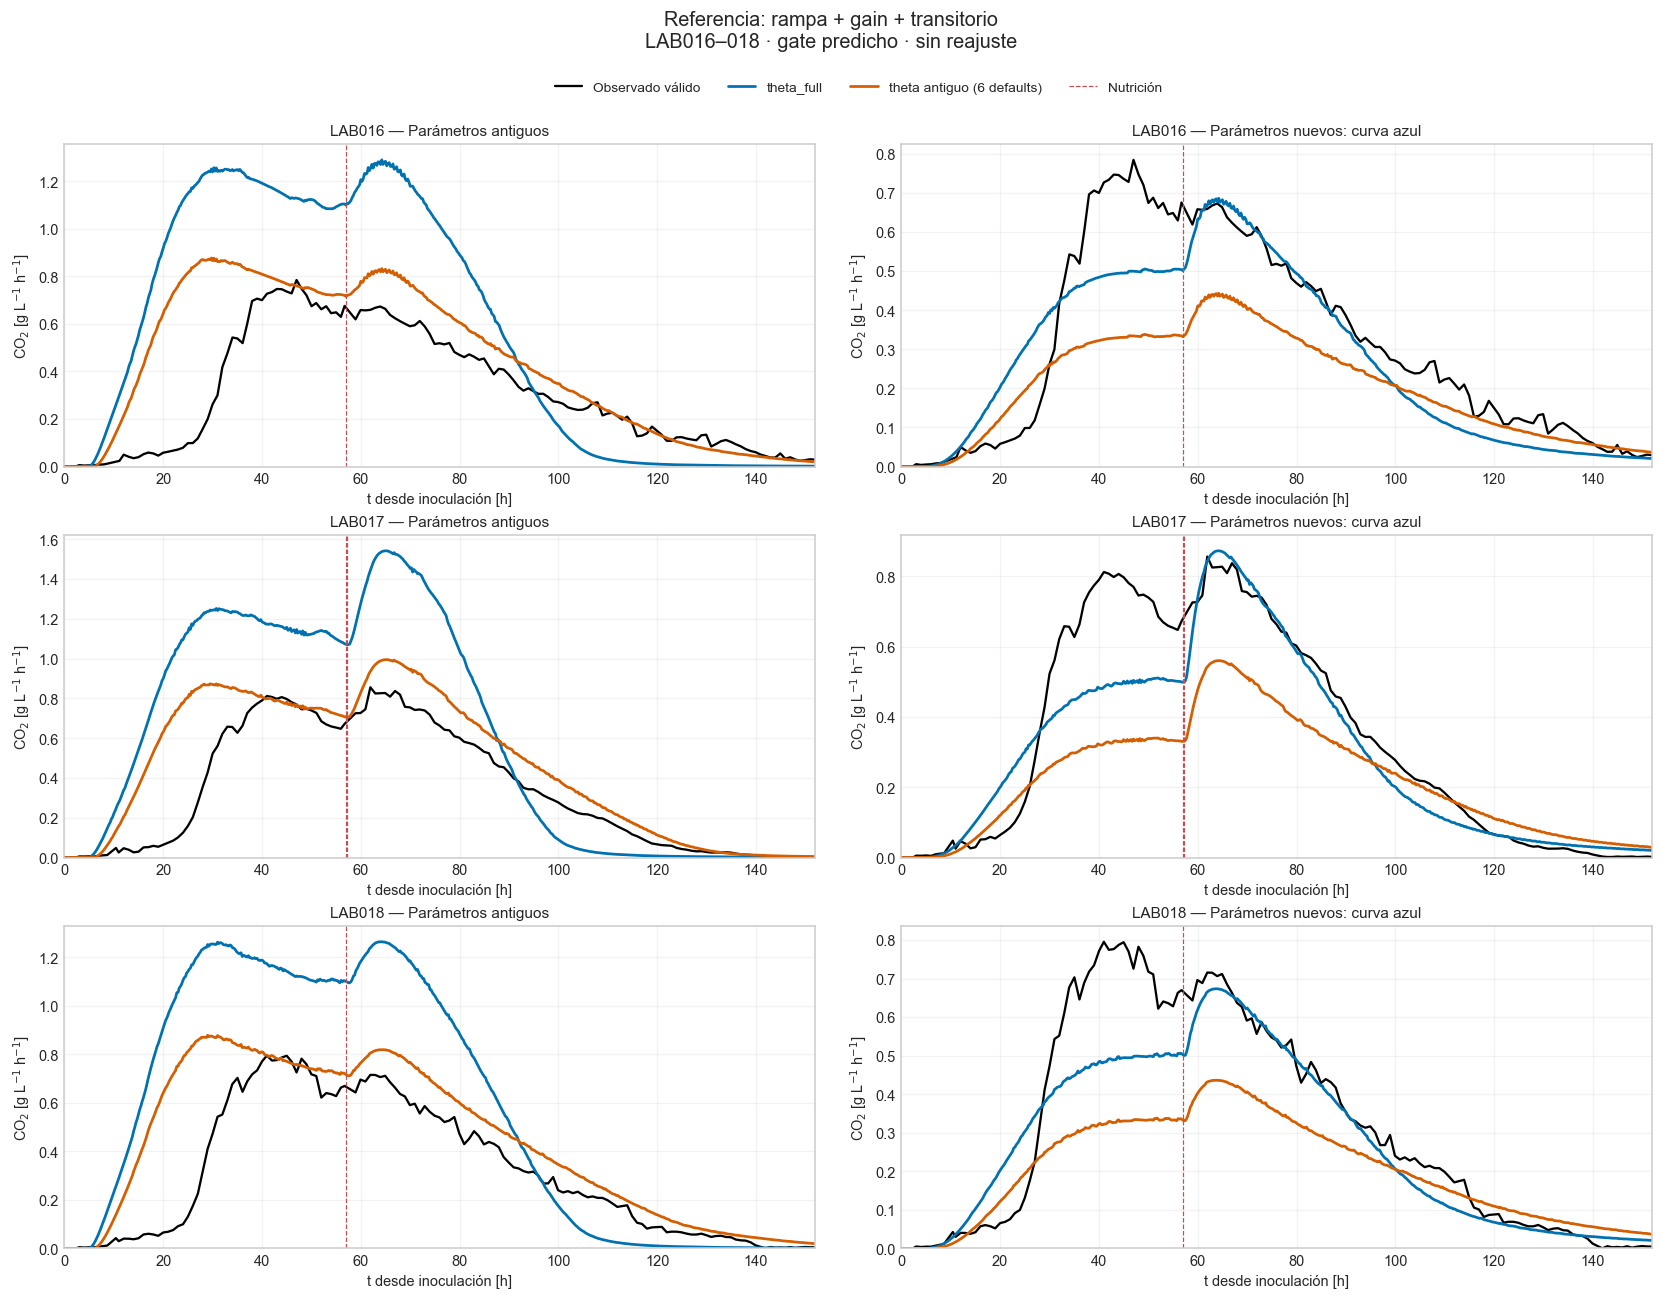

**Métricas descriptivas completas y papel de los datos:**

,lab,param_set,theta,role,RMSE_g_l_h,NRMSE_peak,onset_error_h,peak_predicted_g_l_h,AUC_relative_error
0,LAB016,antiguos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.4508,0.5745,-17.0367,1.2833,0.8493
4,LAB017,antiguos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.4272,0.4991,-15.0245,1.5418,0.7588
8,LAB018,antiguos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.4125,0.5187,-15.0475,1.2638,0.8227
24,LAB016,antiguos,theta_antiguo,Evaluación externa ya explorada; ICs proxy y d...,0.2337,0.2978,-13.8573,0.8711,0.4209
28,LAB017,antiguos,theta_antiguo,Evaluación externa ya explorada; ICs proxy y d...,0.2013,0.2352,-12.5556,0.9947,0.3691
32,LAB018,antiguos,theta_antiguo,Evaluación externa ya explorada; ICs proxy y d...,0.2046,0.2573,-12.5800,0.8784,0.4005
48,LAB016,nuevos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.1070,0.1364,-10.9950,0.6819,-0.1100
52,LAB017,nuevos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.1147,0.1340,-7.9692,0.8718,-0.1195
56,LAB018,nuevos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.1094,0.1376,-8.0036,0.6732,-0.1255
72,LAB016,nuevos,theta_antiguo,Evaluación externa ya explorada; ICs proxy y d...,0.1734,0.2209,-6.9892,0.4405,-0.3430


RMSE_g_l_h  NRMSE_peak
param_set theta         window                           
antiguos  theta_full    completo       0.4272      0.5187
                        pre_pulso      0.5698      0.7165
                        pulso_24h      0.5481      0.6984
                        cola           0.1215      0.1528
          theta_antiguo completo       0.2046      0.2573
                        pre_pulso      0.3156      0.3968
                        pulso_24h      0.1506      0.1828
                        cola           0.0643      0.0808
nuevos    theta_full    completo       0.1094      0.1364
                        pre_pulso      0.1720      0.2096
                        pulso_24h      0.0331      0.0387
                        cola           0.0435      0.0508
          theta_antiguo completo       0.1931      0.2399
                        pre_pulso      0.2712      0.3306
                        pulso_24h      0.2231      0.2805
                        cola           0.0699      0.0835

In [15]:
comparison.show_comparison(RESULT,BATCHES,OBSERVED,THETA_TABLE,PARAM_SETS,'vigente',EXTERNAL_LABS,'gate_predicho')

## Opción 1: directa sin transitorio — LAB016–018, gate predicho

Columnas: parámetros antiguos y nuevos. Colores: theta_full y theta antiguo. Ningún parámetro se reajusta para esta figura.

**Ecuaciones de esta figura — Opción 1: nutrición directa, sin transitorio.** Bracket de G+F/E **simulados**, independiente de CO2 observado.

$$q_{\mathrm{bio},k}=Y_{CO_2/E}X_k\,a_\beta(T)\,\frac{1}{1+i_E(T)E_k}\left[\beta_{G0}\frac{G_k}{G_k+K_G(T)}+\beta_{F0}\frac{F_k}{F_k+K_F(T)}\frac{1}{1+i_G(T)G_k}\right],\quad k\in\{0,N\}.$$
$$K_G=\frac{\beta_{G0}}{s_G}a_K(T),\quad K_F=\frac{\beta_{F0}}{s_F}a_K(T),\quad r=\operatorname{clip}((t-t_p)/t_{rise},0,1).$$
$$ q_{\mathrm{bio}}=q_{\mathrm{bio},N},\quad X_{\mathrm{eff}}=X_N $$
$$r_{O_2}=q_{O_2,max}X_{eff}\frac{O}{0.25+O},\quad \dot O=-r_{O_2},\quad O(0)=\alpha_O O_{sat}(0),\quad \phi_{ana}=\frac{0.75^2}{0.75^2+O^2},\quad f_{ferm}=0.08+0.92\phi_{ana}.$$
$$q_{resp}=\frac{44.01}{32000}r_{O_2},\quad a=3z^2-2z^3,\quad z=\operatorname{clip}\left(\frac{t-[L+s(U-L)]}{\max(d(U-L),0.25)},0,1\right).$$
$$q_{base}=a\,[f_{ferm}q_{bio}+q_{resp}],\quad q_{prod}=M_Nq_{base},\quad M_N=1,\quad T_N=0,\quad A=0.$$
$$C_{sat}=s_{CO_2}1.69e^{-0.032(T-20)}e^{0.0016E_N}e^{-0.0012(G_N+F_N)},\quad q_{out}=k C\left(0.05+0.95\frac{C}{C+C_{sat}}\right),\quad \dot C=q_{prod}-q_{out},\quad q_{pred}=g_{matrix}q_{out}.$$

Se integra el pool con Euler y límite de CO2 disponible; C(0)=0. En las familias con transitorio, la normalización antigua es el máximo del kernel en la grilla de este LAB; la nueva es el máximo analítico, en u*=tau_r log(1+tau_d/tau_r). La forma del gate usa sus fracciones s/d antiguas o nuevas. Las tablas siguientes muestran los valores efectivos; los parámetros retirados se marcan como «no interviene».

La actualización implementada, con h=t_i-t_(i-1), es:
$$q_{out,i}=\min\!\left[k C_{i-1}\left(0.05+0.95\frac{C_{i-1}}{C_{i-1}+C_{sat,i}}\right),\frac{C_{i-1}}{h}+q_{prod,i-1}\right],\quad C_i=[C_{i-1}+h(q_{prod,i-1}-q_{out,i})]_+.$$


,parameter,uso,antiguos,nuevos
0,kCO2_release_h,activo,0.424588,0.096958
1,CO2sat_scale,activo,0.35139,2.5
2,O2_qmax_mg_gdw_h,activo,0.15,0.253137
3,O2_initial_scale,activo,0.1954,0.179606
4,pulse_t_rise_h,no interviene,—,—
5,pulse_activity_gain,no interviene,—,—
6,chem_activation_start_fraction,activo,0.735057,0.741575
7,chem_activation_duration_fraction,activo,1.06391,0.457773
8,matrix_gain,activo,3.115757,1.446718
9,A,no interviene,0 (M_N=1),0 (M_N=1)


**Vector cinético usado por cada color (17 parámetros):**

,parameter,theta_full,theta_antiguo
0,mu0,0.078728,0.078728
1,sN,8.751446,18.000000
2,qN,0.021080,0.021080
3,qXG,0.081491,0.112500
4,qXF,0.070933,0.112500
5,betaG0,0.428878,0.428878
6,sG,0.097455,0.030000
7,betaF0,3.440399,3.440399
8,sF,0.178295,0.030000
9,qEG,1.712807,1.712807


**Condiciones iniciales comunes y eventos de esta figura:**

,lab,X,Xd,N,G,F,E,Gly
0,LAB016,0.45,0.0,0.24433,74.05,77.73,0.0,1.14
1,LAB017,0.45,0.0,0.24433,74.05,77.73,0.0,1.14
2,LAB018,0.45,0.0,0.24433,74.05,77.73,0.0,1.14


,lab,event_h,delta_N_kg_m3,dose_status
0,LAB016,56.935556,0.14,referencia supuesta
1,LAB017,56.933611,0.14,referencia supuesta
2,LAB017,57.133889,0.14,referencia supuesta
3,LAB018,56.931667,0.14,referencia supuesta


,lab,param_set,theta,gate_lower_h,gate_upper_h,gate_start_h,gate_end_h
24,LAB016,antiguos,theta_full,4.25,4.5,4.4338,4.6997
25,LAB017,antiguos,theta_full,4.25,4.5,4.4338,4.6997
26,LAB018,antiguos,theta_full,4.25,4.5,4.4338,4.6997
30,LAB016,antiguos,theta_antiguo,5.25,5.5,5.4338,5.6997
31,LAB017,antiguos,theta_antiguo,5.25,5.5,5.4338,5.6997
32,LAB018,antiguos,theta_antiguo,5.25,5.5,5.4338,5.6997
36,LAB016,nuevos,theta_full,4.25,4.5,4.4354,4.6854
37,LAB017,nuevos,theta_full,4.25,4.5,4.4354,4.6854
38,LAB018,nuevos,theta_full,4.25,4.5,4.4354,4.6854
42,LAB016,nuevos,theta_antiguo,5.25,5.5,5.4354,5.6854


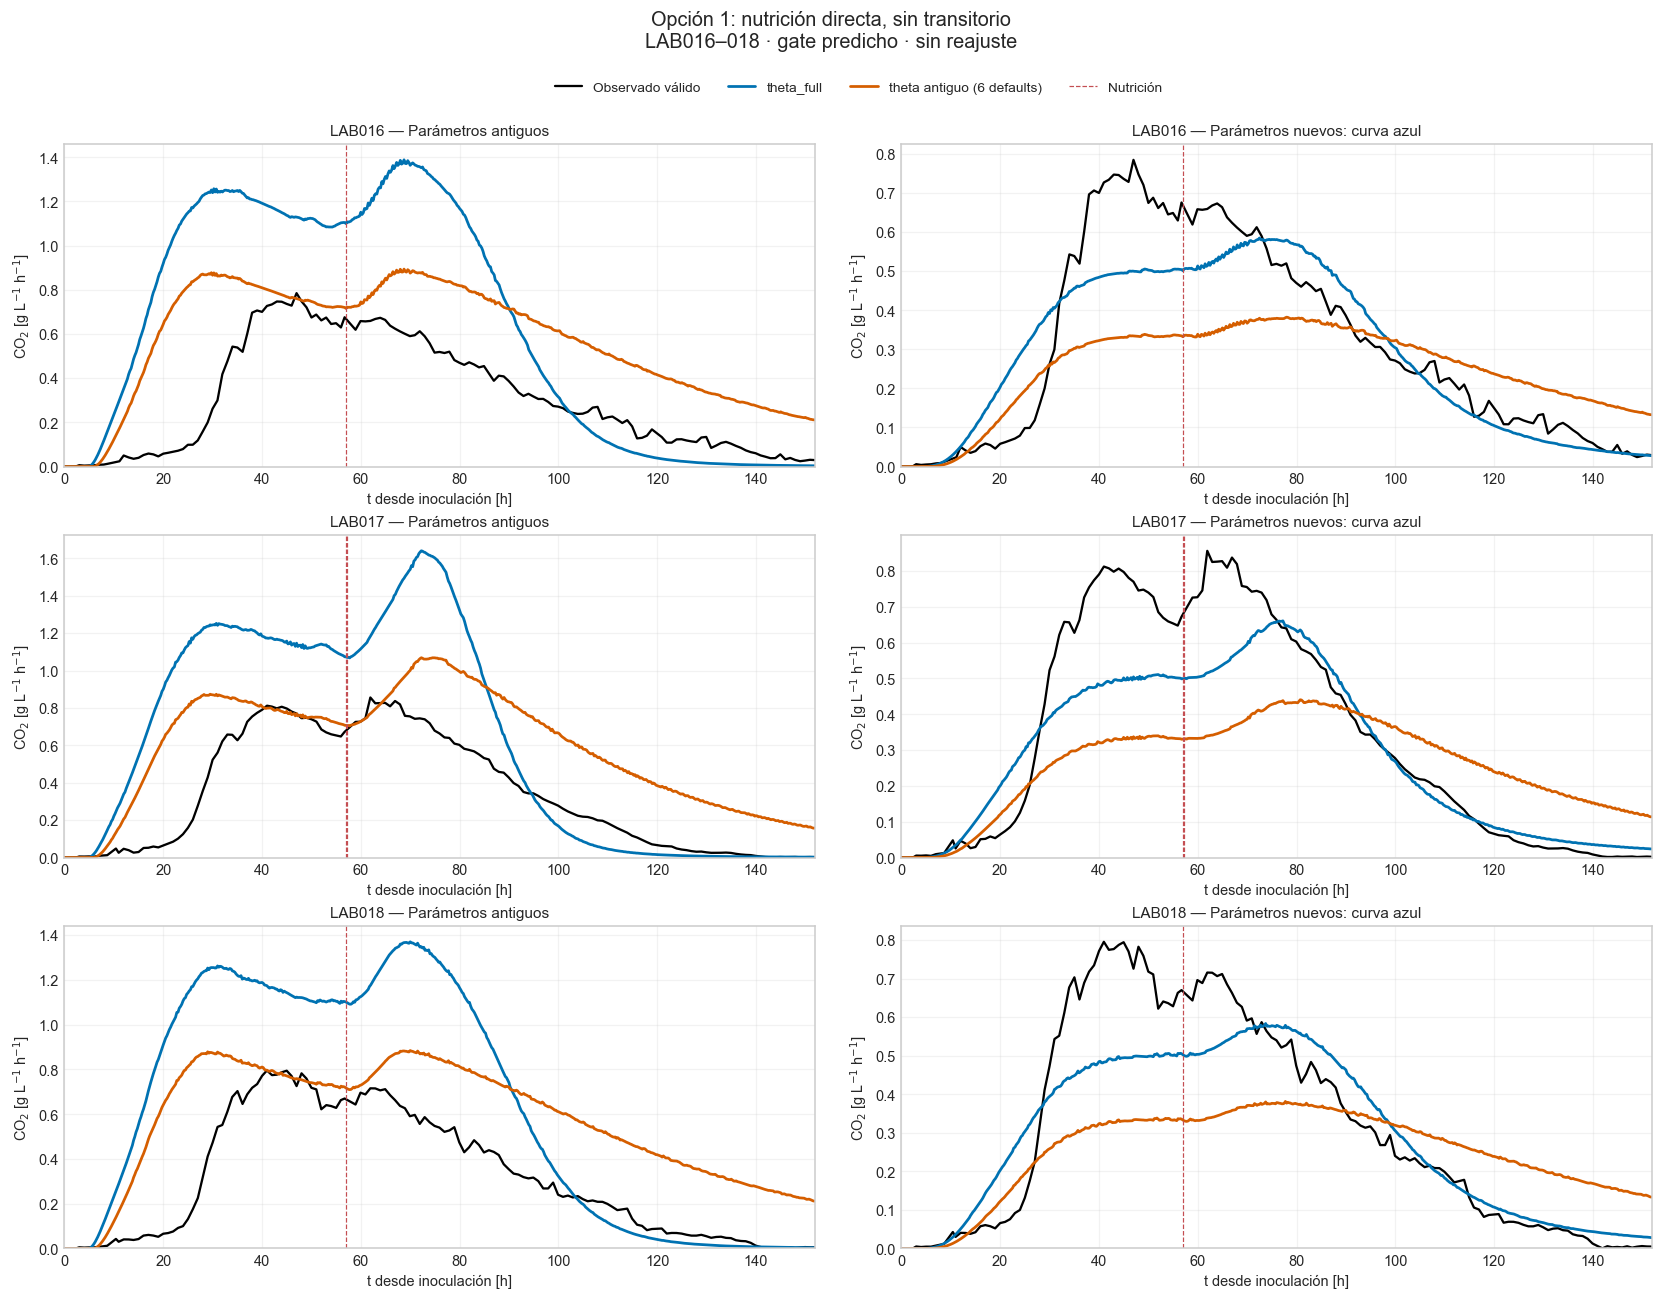

**Métricas descriptivas completas y papel de los datos:**

,lab,param_set,theta,role,RMSE_g_l_h,NRMSE_peak,onset_error_h,peak_predicted_g_l_h,AUC_relative_error
96,LAB016,antiguos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.4907,0.6252,-17.0367,1.3815,1.0464
100,LAB017,antiguos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.4505,0.5263,-15.0245,1.6323,0.8470
104,LAB018,antiguos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.4571,0.5747,-15.0475,1.3683,1.0216
120,LAB016,antiguos,theta_antiguo,Evaluación externa ya explorada; ICs proxy y d...,0.3121,0.3977,-13.8573,0.8897,0.8523
124,LAB017,antiguos,theta_antiguo,Evaluación externa ya explorada; ICs proxy y d...,0.3051,0.3564,-12.5556,1.0679,0.7398
128,LAB018,antiguos,theta_antiguo,Evaluación externa ya explorada; ICs proxy y d...,0.3035,0.3816,-12.5800,0.8825,0.8268
144,LAB016,nuevos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.1090,0.1389,-10.9950,0.5808,-0.0513
148,LAB017,nuevos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.1348,0.1575,-7.9692,0.6592,-0.1427
152,LAB018,nuevos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.1196,0.1504,-8.0036,0.5781,-0.0646
168,LAB016,nuevos,theta_antiguo,Evaluación externa ya explorada; ICs proxy y d...,0.1836,0.2339,-6.9892,0.3818,-0.1887


RMSE_g_l_h  NRMSE_peak
param_set theta         window                           
antiguos  theta_full    completo       0.4571      0.5747
                        pre_pulso      0.5698      0.7165
                        pulso_24h      0.6900      0.8330
                        cola           0.2018      0.2538
          theta_antiguo completo       0.3051      0.3816
                        pre_pulso      0.3156      0.3968
                        pulso_24h      0.2626      0.3150
                        cola           0.3110      0.3724
nuevos    theta_full    completo       0.1196      0.1504
                        pre_pulso      0.1720      0.2096
                        pulso_24h      0.1168      0.1469
                        cola           0.0481      0.0604
          theta_antiguo completo       0.2119      0.2665
                        pre_pulso      0.2712      0.3306
                        pulso_24h      0.2638      0.3317
                        cola           0.1178      0.1481

In [16]:
comparison.show_comparison(RESULT,BATCHES,OBSERVED,THETA_TABLE,PARAM_SETS,'directa',EXTERNAL_LABS,'gate_predicho')

## Opción 2: directa con transitorio — LAB016–018, gate predicho

Columnas: parámetros antiguos y nuevos. Colores: theta_full y theta antiguo. Ningún parámetro se reajusta para esta figura.

**Ecuaciones de esta figura — Opción 2: nutrición directa + transitorio.** Bracket de G+F/E **simulados**, independiente de CO2 observado.

$$q_{\mathrm{bio},k}=Y_{CO_2/E}X_k\,a_\beta(T)\,\frac{1}{1+i_E(T)E_k}\left[\beta_{G0}\frac{G_k}{G_k+K_G(T)}+\beta_{F0}\frac{F_k}{F_k+K_F(T)}\frac{1}{1+i_G(T)G_k}\right],\quad k\in\{0,N\}.$$
$$K_G=\frac{\beta_{G0}}{s_G}a_K(T),\quad K_F=\frac{\beta_{F0}}{s_F}a_K(T),\quad r=\operatorname{clip}((t-t_p)/t_{rise},0,1).$$
$$ q_{\mathrm{bio}}=q_{\mathrm{bio},N},\quad X_{\mathrm{eff}}=X_N $$
$$r_{O_2}=q_{O_2,max}X_{eff}\frac{O}{0.25+O},\quad \dot O=-r_{O_2},\quad O(0)=\alpha_O O_{sat}(0),\quad \phi_{ana}=\frac{0.75^2}{0.75^2+O^2},\quad f_{ferm}=0.08+0.92\phi_{ana}.$$
$$q_{resp}=\frac{44.01}{32000}r_{O_2},\quad a=3z^2-2z^3,\quad z=\operatorname{clip}\left(\frac{t-[L+s(U-L)]}{\max(d(U-L),0.25)},0,1\right).$$
$$q_{base}=a\,[f_{ferm}q_{bio}+q_{resp}],\quad q_{prod}=M_Nq_{base},\quad M_N=1+T_N,\quad T_N=A\sum_j\frac{\Delta N_j}{0.14}\frac{(1-e^{-u_j/\tau_r})e^{-u_j/\tau_d}}{\mathcal N_j},\quad u_j=\max(t-t_j,0).$$
$$C_{sat}=s_{CO_2}1.69e^{-0.032(T-20)}e^{0.0016E_N}e^{-0.0012(G_N+F_N)},\quad q_{out}=k C\left(0.05+0.95\frac{C}{C+C_{sat}}\right),\quad \dot C=q_{prod}-q_{out},\quad q_{pred}=g_{matrix}q_{out}.$$

Se integra el pool con Euler y límite de CO2 disponible; C(0)=0. En las familias con transitorio, la normalización antigua es el máximo del kernel en la grilla de este LAB; la nueva es el máximo analítico, en u*=tau_r log(1+tau_d/tau_r). La forma del gate usa sus fracciones s/d antiguas o nuevas. Las tablas siguientes muestran los valores efectivos; los parámetros retirados se marcan como «no interviene».

La actualización implementada, con h=t_i-t_(i-1), es:
$$q_{out,i}=\min\!\left[k C_{i-1}\left(0.05+0.95\frac{C_{i-1}}{C_{i-1}+C_{sat,i}}\right),\frac{C_{i-1}}{h}+q_{prod,i-1}\right],\quad C_i=[C_{i-1}+h(q_{prod,i-1}-q_{out,i})]_+.$$


,parameter,uso,antiguos,nuevos
0,kCO2_release_h,activo,0.424588,0.096958
1,CO2sat_scale,activo,0.35139,2.5
2,O2_qmax_mg_gdw_h,activo,0.15,0.253137
3,O2_initial_scale,activo,0.1954,0.179606
4,pulse_t_rise_h,no interviene,—,—
5,pulse_activity_gain,no interviene,—,—
6,chem_activation_start_fraction,activo,0.735057,0.741575
7,chem_activation_duration_fraction,activo,1.06391,0.457773
8,matrix_gain,activo,3.115757,1.446718
9,A,activo,0.3,1.5


**Vector cinético usado por cada color (17 parámetros):**

,parameter,theta_full,theta_antiguo
0,mu0,0.078728,0.078728
1,sN,8.751446,18.000000
2,qN,0.021080,0.021080
3,qXG,0.081491,0.112500
4,qXF,0.070933,0.112500
5,betaG0,0.428878,0.428878
6,sG,0.097455,0.030000
7,betaF0,3.440399,3.440399
8,sF,0.178295,0.030000
9,qEG,1.712807,1.712807


**Condiciones iniciales comunes y eventos de esta figura:**

,lab,X,Xd,N,G,F,E,Gly
0,LAB016,0.45,0.0,0.24433,74.05,77.73,0.0,1.14
1,LAB017,0.45,0.0,0.24433,74.05,77.73,0.0,1.14
2,LAB018,0.45,0.0,0.24433,74.05,77.73,0.0,1.14


,lab,event_h,delta_N_kg_m3,dose_status
0,LAB016,56.935556,0.14,referencia supuesta
1,LAB017,56.933611,0.14,referencia supuesta
2,LAB017,57.133889,0.14,referencia supuesta
3,LAB018,56.931667,0.14,referencia supuesta


,lab,param_set,theta,gate_lower_h,gate_upper_h,gate_start_h,gate_end_h
48,LAB016,antiguos,theta_full,4.25,4.5,4.4338,4.6997
49,LAB017,antiguos,theta_full,4.25,4.5,4.4338,4.6997
50,LAB018,antiguos,theta_full,4.25,4.5,4.4338,4.6997
54,LAB016,antiguos,theta_antiguo,5.25,5.5,5.4338,5.6997
55,LAB017,antiguos,theta_antiguo,5.25,5.5,5.4338,5.6997
56,LAB018,antiguos,theta_antiguo,5.25,5.5,5.4338,5.6997
60,LAB016,nuevos,theta_full,4.25,4.5,4.4354,4.6854
61,LAB017,nuevos,theta_full,4.25,4.5,4.4354,4.6854
62,LAB018,nuevos,theta_full,4.25,4.5,4.4354,4.6854
66,LAB016,nuevos,theta_antiguo,5.25,5.5,5.4354,5.6854


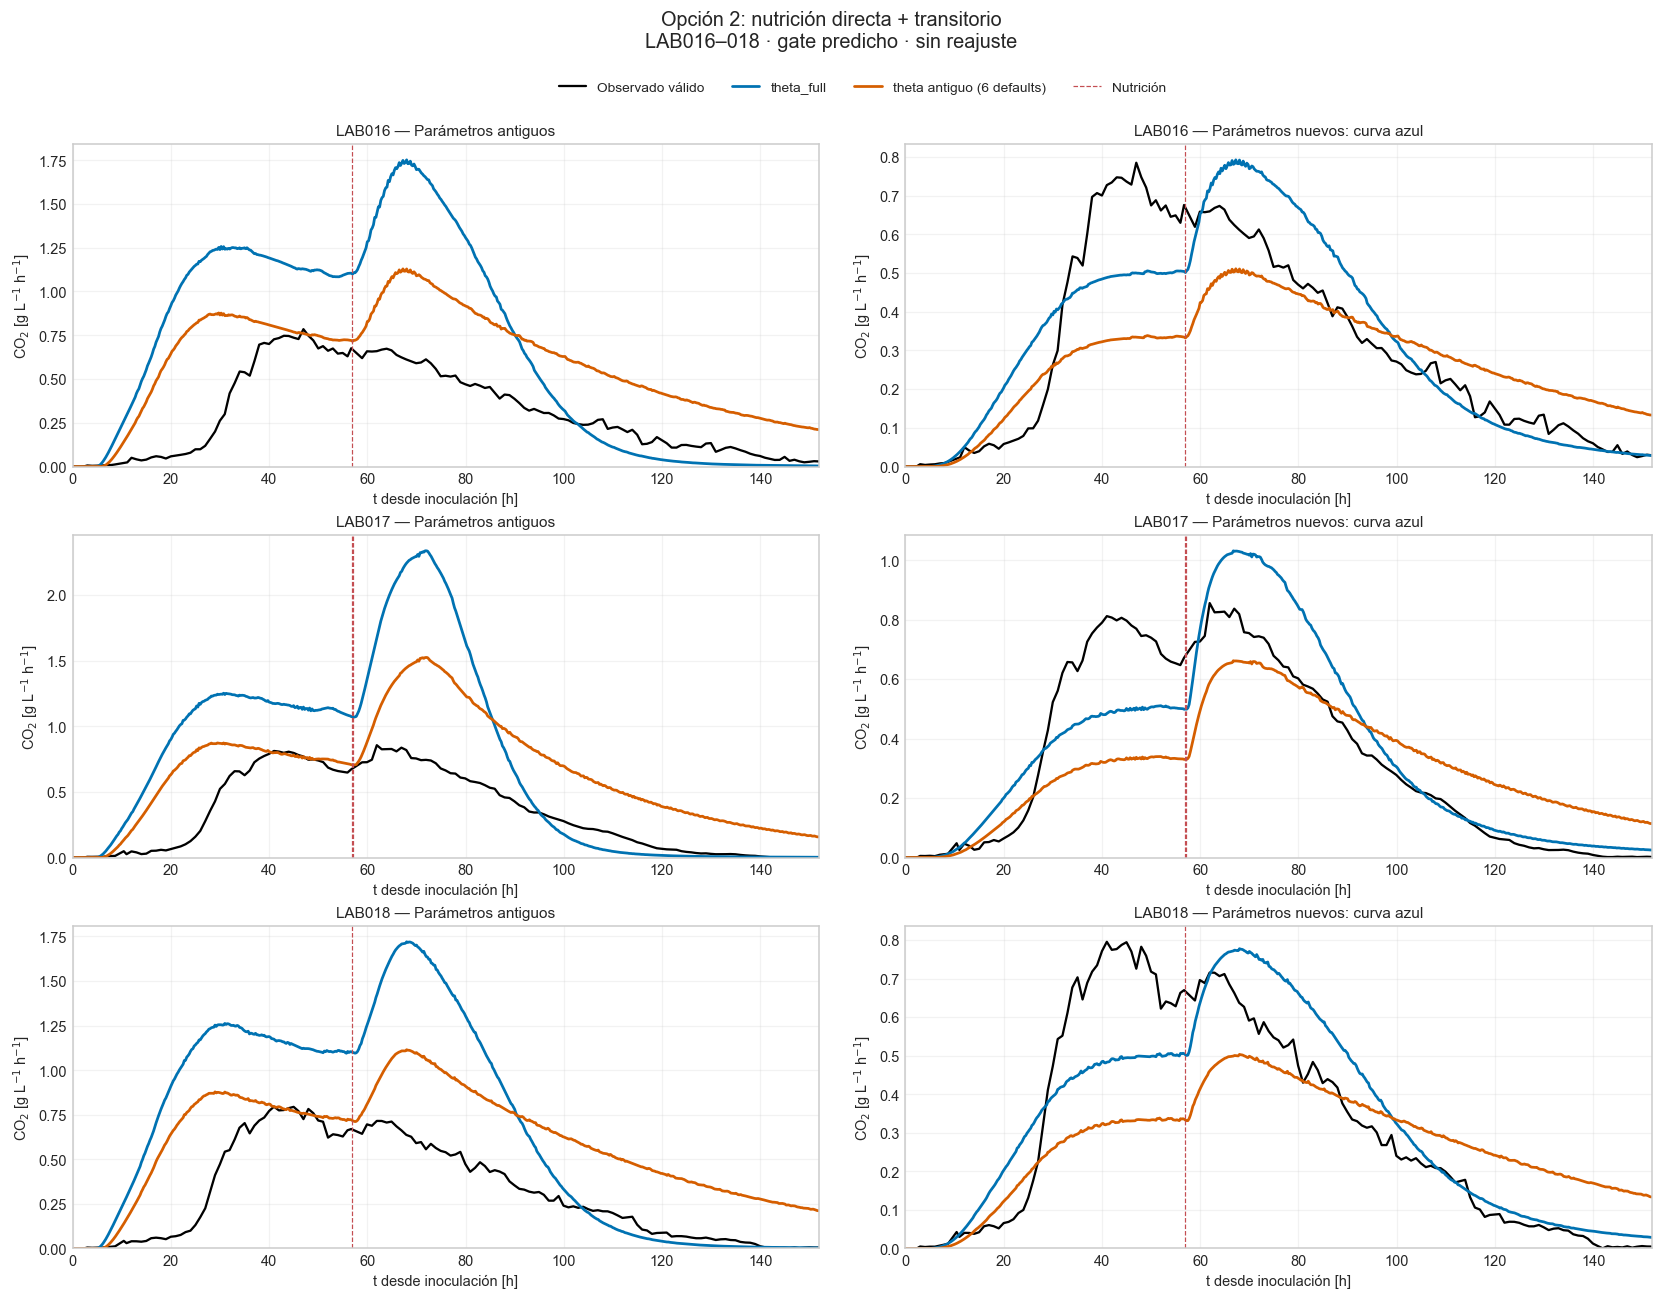

**Métricas descriptivas completas y papel de los datos:**

,lab,param_set,theta,role,RMSE_g_l_h,NRMSE_peak,onset_error_h,peak_predicted_g_l_h,AUC_relative_error
192,LAB016,antiguos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.5582,0.7112,-17.0367,1.7483,1.1926
196,LAB017,antiguos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.6180,0.7220,-15.0245,2.3372,1.1319
200,LAB018,antiguos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.5256,0.6609,-15.0475,1.7178,1.1648
216,LAB016,antiguos,theta_antiguo,Evaluación externa ya explorada; ICs proxy y d...,0.3448,0.4394,-13.8573,1.1257,0.9547
220,LAB017,antiguos,theta_antiguo,Evaluación externa ya explorada; ICs proxy y d...,0.3887,0.4542,-12.5556,1.5244,0.9480
224,LAB018,antiguos,theta_antiguo,Evaluación externa ya explorada; ICs proxy y d...,0.3348,0.4210,-12.5800,1.1128,0.9272
240,LAB016,nuevos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.1242,0.1583,-10.9950,0.7892,0.0582
244,LAB017,nuevos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.1489,0.1740,-7.9692,1.0305,0.0605
248,LAB018,nuevos,theta_full,Evaluación externa ya explorada; ICs proxy y d...,0.1282,0.1612,-8.0036,0.7761,0.0414
264,LAB016,nuevos,theta_antiguo,Evaluación externa ya explorada; ICs proxy y d...,0.1665,0.2122,-6.9892,0.5084,-0.1175


RMSE_g_l_h  NRMSE_peak
param_set theta         window                           
antiguos  theta_full    completo       0.5582      0.7112
                        pre_pulso      0.5698      0.7165
                        pulso_24h      0.9474      1.2072
                        cola           0.2290      0.2880
          theta_antiguo completo       0.3448      0.4394
                        pre_pulso      0.3156      0.3968
                        pulso_24h      0.4244      0.5409
                        cola           0.3254      0.4091
nuevos    theta_full    completo       0.1282      0.1612
                        pre_pulso      0.1720      0.2096
                        pulso_24h      0.1556      0.1983
                        cola           0.0708      0.0873
          theta_antiguo completo       0.1958      0.2391
                        pre_pulso      0.2712      0.3306
                        pulso_24h      0.1491      0.1742
                        cola           0.1191      0.1497

In [17]:
comparison.show_comparison(RESULT,BATCHES,OBSERVED,THETA_TABLE,PARAM_SETS,'directa_transitorio',EXTERNAL_LABS,'gate_predicho')

## Diagnóstico condicionado — comparación con la figura histórica restaurada

Aquí se usa el onset observado de LAB016–018. Se conserva el mismo soporte, ICs, pulsos y juegos de parámetros. Estas tres figuras no forman parte de una evaluación predictiva del arranque.

**Ecuaciones de esta figura — Referencia: rampa + gain + transitorio.** Bracket **[0, onset manual observado]**: diagnóstico condicionado.

$$q_{\mathrm{bio},k}=Y_{CO_2/E}X_k\,a_\beta(T)\,\frac{1}{1+i_E(T)E_k}\left[\beta_{G0}\frac{G_k}{G_k+K_G(T)}+\beta_{F0}\frac{F_k}{F_k+K_F(T)}\frac{1}{1+i_G(T)G_k}\right],\quad k\in\{0,N\}.$$
$$K_G=\frac{\beta_{G0}}{s_G}a_K(T),\quad K_F=\frac{\beta_{F0}}{s_F}a_K(T),\quad r=\operatorname{clip}((t-t_p)/t_{rise},0,1).$$
$$ q_{\mathrm{bio}}=[(1+(g-1)r)q_{\mathrm{bio},0}+r(q_{\mathrm{bio},N}-q_{\mathrm{bio},0})]_+,\quad X_{\mathrm{eff}}=[X_0+r(X_N-X_0)]_+ $$
$$r_{O_2}=q_{O_2,max}X_{eff}\frac{O}{0.25+O},\quad \dot O=-r_{O_2},\quad O(0)=\alpha_O O_{sat}(0),\quad \phi_{ana}=\frac{0.75^2}{0.75^2+O^2},\quad f_{ferm}=0.08+0.92\phi_{ana}.$$
$$q_{resp}=\frac{44.01}{32000}r_{O_2},\quad a=3z^2-2z^3,\quad z=\operatorname{clip}\left(\frac{t-[L+s(U-L)]}{\max(d(U-L),0.25)},0,1\right).$$
$$q_{base}=a\,[f_{ferm}q_{bio}+q_{resp}],\quad q_{prod}=M_Nq_{base},\quad M_N=1+T_N,\quad T_N=A\sum_j\frac{\Delta N_j}{0.14}\frac{(1-e^{-u_j/\tau_r})e^{-u_j/\tau_d}}{\mathcal N_j},\quad u_j=\max(t-t_j,0).$$
$$C_{sat}=s_{CO_2}1.69e^{-0.032(T-20)}e^{0.0016E_N}e^{-0.0012(G_N+F_N)},\quad q_{out}=k C\left(0.05+0.95\frac{C}{C+C_{sat}}\right),\quad \dot C=q_{prod}-q_{out},\quad q_{pred}=g_{matrix}q_{out}.$$

Se integra el pool con Euler y límite de CO2 disponible; C(0)=0. En las familias con transitorio, la normalización antigua es el máximo del kernel en la grilla de este LAB; la nueva es el máximo analítico, en u*=tau_r log(1+tau_d/tau_r). La forma del gate usa sus fracciones s/d antiguas o nuevas. Las tablas siguientes muestran los valores efectivos; los parámetros retirados se marcan como «no interviene».

La actualización implementada, con h=t_i-t_(i-1), es:
$$q_{out,i}=\min\!\left[k C_{i-1}\left(0.05+0.95\frac{C_{i-1}}{C_{i-1}+C_{sat,i}}\right),\frac{C_{i-1}}{h}+q_{prod,i-1}\right],\quad C_i=[C_{i-1}+h(q_{prod,i-1}-q_{out,i})]_+.$$


,parameter,uso,antiguos,nuevos
0,kCO2_release_h,activo,0.424588,0.096958
1,CO2sat_scale,activo,0.35139,2.5
2,O2_qmax_mg_gdw_h,activo,0.15,0.253137
3,O2_initial_scale,activo,0.1954,0.179606
4,pulse_t_rise_h,activo,64.658704,56.741847
5,pulse_activity_gain,activo,0.25,0.250011
6,chem_activation_start_fraction,activo,0.735057,0.741575
7,chem_activation_duration_fraction,activo,1.06391,0.457773
8,matrix_gain,activo,3.115757,1.446718
9,A,activo,0.3,1.5


**Vector cinético usado por cada color (17 parámetros):**

,parameter,theta_full,theta_antiguo
0,mu0,0.078728,0.078728
1,sN,8.751446,18.000000
2,qN,0.021080,0.021080
3,qXG,0.081491,0.112500
4,qXF,0.070933,0.112500
5,betaG0,0.428878,0.428878
6,sG,0.097455,0.030000
7,betaF0,3.440399,3.440399
8,sF,0.178295,0.030000
9,qEG,1.712807,1.712807


**Condiciones iniciales comunes y eventos de esta figura:**

,lab,X,Xd,N,G,F,E,Gly
0,LAB016,0.45,0.0,0.24433,74.05,77.73,0.0,1.14
1,LAB017,0.45,0.0,0.24433,74.05,77.73,0.0,1.14
2,LAB018,0.45,0.0,0.24433,74.05,77.73,0.0,1.14


,lab,event_h,delta_N_kg_m3,dose_status
0,LAB016,56.935556,0.14,referencia supuesta
1,LAB017,56.933611,0.14,referencia supuesta
2,LAB017,57.133889,0.14,referencia supuesta
3,LAB018,56.931667,0.14,referencia supuesta


,lab,param_set,theta,gate_lower_h,gate_upper_h,gate_start_h,gate_end_h
72,LAB016,antiguos,theta_full,0.0,24.2491,17.8245,43.6233
73,LAB017,antiguos,theta_full,0.0,22.2981,16.3904,40.1135
74,LAB018,antiguos,theta_full,0.0,22.6475,16.6472,40.7421
75,LAB016,antiguos,theta_antiguo,0.0,24.2491,17.8245,43.6233
76,LAB017,antiguos,theta_antiguo,0.0,22.2981,16.3904,40.1135
77,LAB018,antiguos,theta_antiguo,0.0,22.6475,16.6472,40.7421
78,LAB016,nuevos,theta_full,0.0,24.2491,17.9825,29.0831
79,LAB017,nuevos,theta_full,0.0,22.2981,16.5357,26.7432
80,LAB018,nuevos,theta_full,0.0,22.6475,16.7948,27.1622
81,LAB016,nuevos,theta_antiguo,0.0,24.2491,17.9825,29.0831


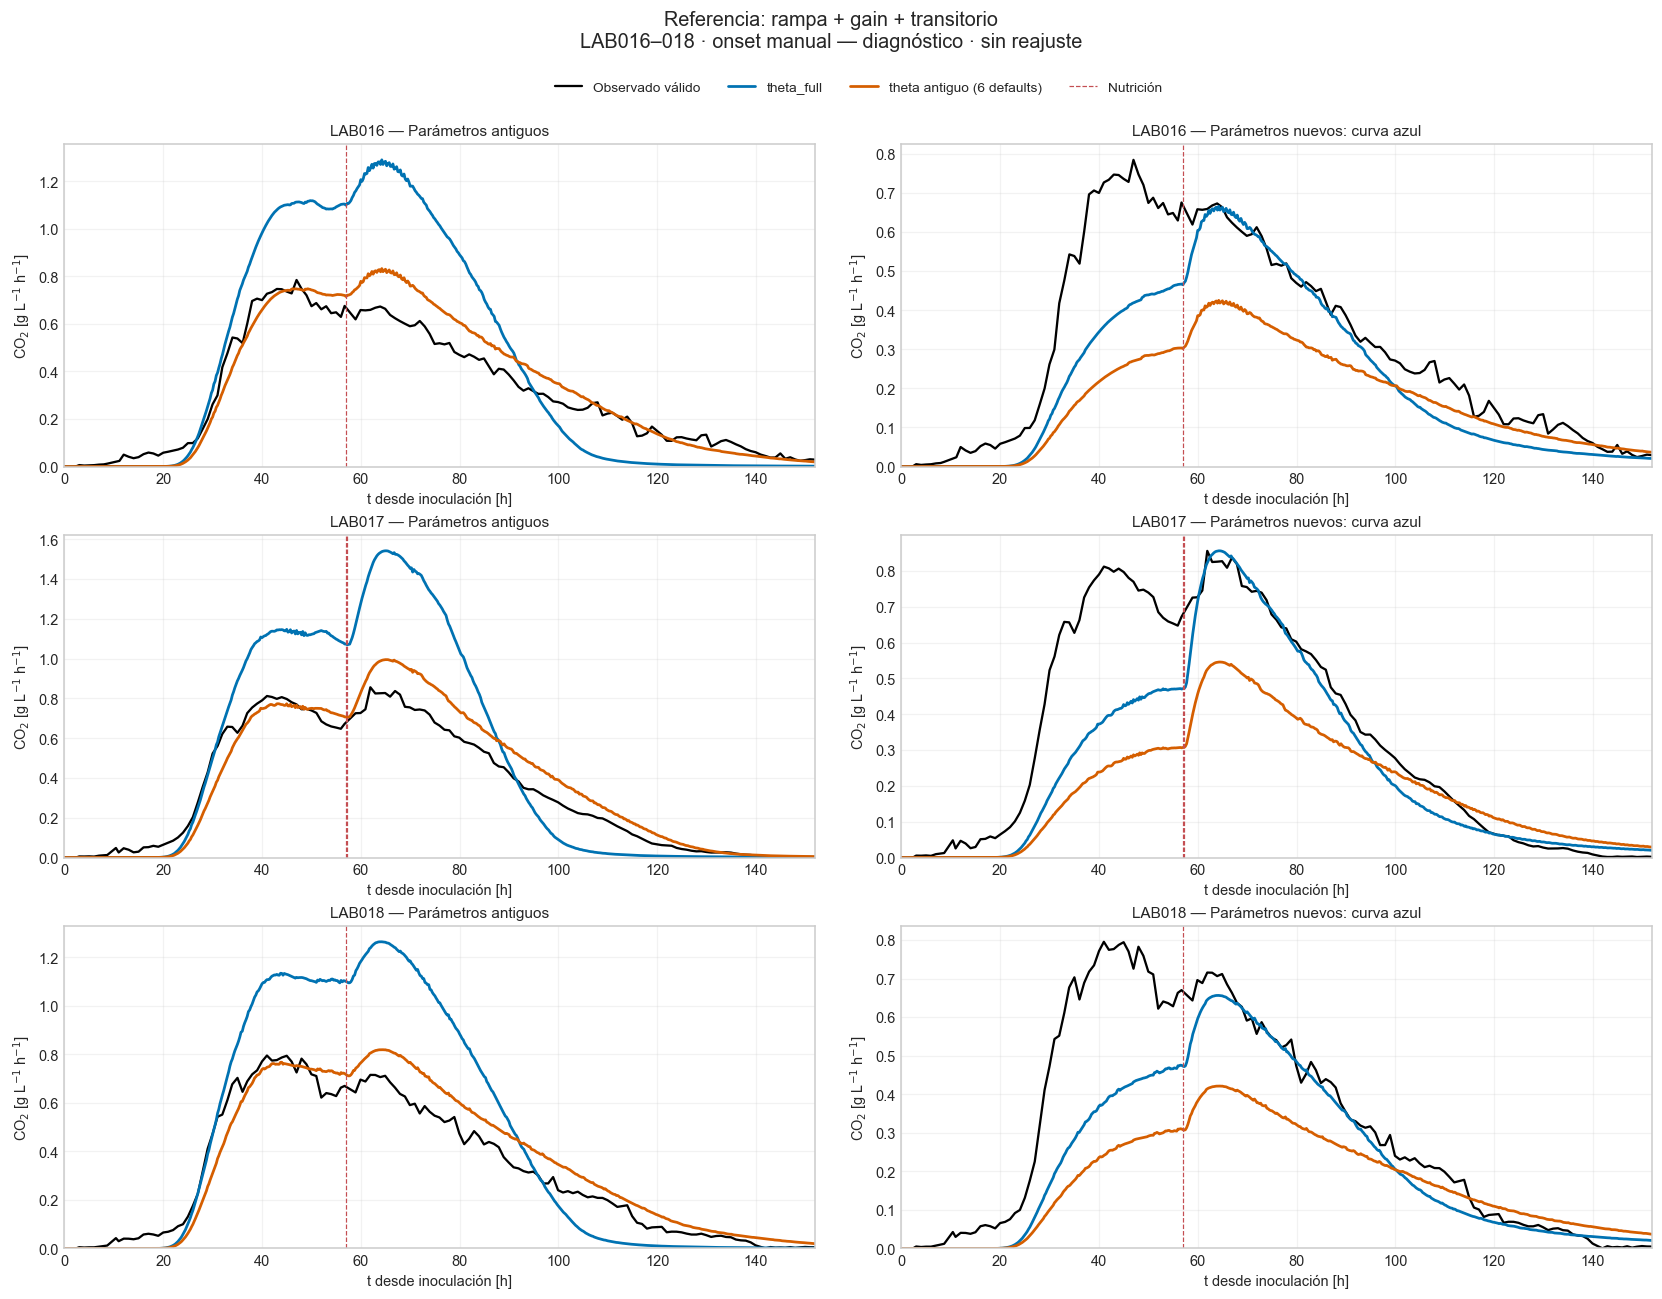

**Métricas descriptivas completas y papel de los datos:**

,lab,param_set,theta,role,RMSE_g_l_h,NRMSE_peak,onset_error_h,peak_predicted_g_l_h,AUC_relative_error
288,LAB016,antiguos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.2761,0.3519,2.0011,1.2833,0.3603
292,LAB017,antiguos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.2973,0.3474,2.0163,1.5418,0.3783
296,LAB018,antiguos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.2636,0.3315,1.9964,1.2638,0.3928
300,LAB016,antiguos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.0776,0.0989,3.0027,0.8289,0.0786
304,LAB017,antiguos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.0917,0.1071,3.0169,0.9947,0.1030
308,LAB018,antiguos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.0801,0.1008,2.9925,0.8190,0.0994
312,LAB016,nuevos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.1356,0.1727,4.0090,0.6625,-0.2751
316,LAB017,nuevos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.1566,0.1829,5.0277,0.8551,-0.2472
320,LAB018,nuevos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.1507,0.1895,4.9950,0.6561,-0.2696
324,LAB016,nuevos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.2069,0.2637,5.9858,0.4234,-0.4570


RMSE_g_l_h  NRMSE_peak
param_set theta         window                           
antiguos  theta_full    completo       0.2761      0.3474
                        pre_pulso      0.2383      0.2973
                        pulso_24h      0.5481      0.6984
                        cola           0.1215      0.1528
          theta_antiguo completo       0.0801      0.1008
                        pre_pulso      0.0725      0.0849
                        pulso_24h      0.1506      0.1828
                        cola           0.0643      0.0808
nuevos    theta_full    completo       0.1507      0.1829
                        pre_pulso      0.2403      0.2919
                        pulso_24h      0.0311      0.0363
                        cola           0.0441      0.0515
          theta_antiguo completo       0.2274      0.2787
                        pre_pulso      0.3310      0.3994
                        pulso_24h      0.2345      0.2949
                        cola           0.0711      0.0845

In [18]:
comparison.show_comparison(RESULT,BATCHES,OBSERVED,THETA_TABLE,PARAM_SETS,'vigente',EXTERNAL_LABS,'onset_manual')

**Ecuaciones de esta figura — Opción 1: nutrición directa, sin transitorio.** Bracket **[0, onset manual observado]**: diagnóstico condicionado.

$$q_{\mathrm{bio},k}=Y_{CO_2/E}X_k\,a_\beta(T)\,\frac{1}{1+i_E(T)E_k}\left[\beta_{G0}\frac{G_k}{G_k+K_G(T)}+\beta_{F0}\frac{F_k}{F_k+K_F(T)}\frac{1}{1+i_G(T)G_k}\right],\quad k\in\{0,N\}.$$
$$K_G=\frac{\beta_{G0}}{s_G}a_K(T),\quad K_F=\frac{\beta_{F0}}{s_F}a_K(T),\quad r=\operatorname{clip}((t-t_p)/t_{rise},0,1).$$
$$ q_{\mathrm{bio}}=q_{\mathrm{bio},N},\quad X_{\mathrm{eff}}=X_N $$
$$r_{O_2}=q_{O_2,max}X_{eff}\frac{O}{0.25+O},\quad \dot O=-r_{O_2},\quad O(0)=\alpha_O O_{sat}(0),\quad \phi_{ana}=\frac{0.75^2}{0.75^2+O^2},\quad f_{ferm}=0.08+0.92\phi_{ana}.$$
$$q_{resp}=\frac{44.01}{32000}r_{O_2},\quad a=3z^2-2z^3,\quad z=\operatorname{clip}\left(\frac{t-[L+s(U-L)]}{\max(d(U-L),0.25)},0,1\right).$$
$$q_{base}=a\,[f_{ferm}q_{bio}+q_{resp}],\quad q_{prod}=M_Nq_{base},\quad M_N=1,\quad T_N=0,\quad A=0.$$
$$C_{sat}=s_{CO_2}1.69e^{-0.032(T-20)}e^{0.0016E_N}e^{-0.0012(G_N+F_N)},\quad q_{out}=k C\left(0.05+0.95\frac{C}{C+C_{sat}}\right),\quad \dot C=q_{prod}-q_{out},\quad q_{pred}=g_{matrix}q_{out}.$$

Se integra el pool con Euler y límite de CO2 disponible; C(0)=0. En las familias con transitorio, la normalización antigua es el máximo del kernel en la grilla de este LAB; la nueva es el máximo analítico, en u*=tau_r log(1+tau_d/tau_r). La forma del gate usa sus fracciones s/d antiguas o nuevas. Las tablas siguientes muestran los valores efectivos; los parámetros retirados se marcan como «no interviene».

La actualización implementada, con h=t_i-t_(i-1), es:
$$q_{out,i}=\min\!\left[k C_{i-1}\left(0.05+0.95\frac{C_{i-1}}{C_{i-1}+C_{sat,i}}\right),\frac{C_{i-1}}{h}+q_{prod,i-1}\right],\quad C_i=[C_{i-1}+h(q_{prod,i-1}-q_{out,i})]_+.$$


,parameter,uso,antiguos,nuevos
0,kCO2_release_h,activo,0.424588,0.096958
1,CO2sat_scale,activo,0.35139,2.5
2,O2_qmax_mg_gdw_h,activo,0.15,0.253137
3,O2_initial_scale,activo,0.1954,0.179606
4,pulse_t_rise_h,no interviene,—,—
5,pulse_activity_gain,no interviene,—,—
6,chem_activation_start_fraction,activo,0.735057,0.741575
7,chem_activation_duration_fraction,activo,1.06391,0.457773
8,matrix_gain,activo,3.115757,1.446718
9,A,no interviene,0 (M_N=1),0 (M_N=1)


**Vector cinético usado por cada color (17 parámetros):**

,parameter,theta_full,theta_antiguo
0,mu0,0.078728,0.078728
1,sN,8.751446,18.000000
2,qN,0.021080,0.021080
3,qXG,0.081491,0.112500
4,qXF,0.070933,0.112500
5,betaG0,0.428878,0.428878
6,sG,0.097455,0.030000
7,betaF0,3.440399,3.440399
8,sF,0.178295,0.030000
9,qEG,1.712807,1.712807


**Condiciones iniciales comunes y eventos de esta figura:**

,lab,X,Xd,N,G,F,E,Gly
0,LAB016,0.45,0.0,0.24433,74.05,77.73,0.0,1.14
1,LAB017,0.45,0.0,0.24433,74.05,77.73,0.0,1.14
2,LAB018,0.45,0.0,0.24433,74.05,77.73,0.0,1.14


,lab,event_h,delta_N_kg_m3,dose_status
0,LAB016,56.935556,0.14,referencia supuesta
1,LAB017,56.933611,0.14,referencia supuesta
2,LAB017,57.133889,0.14,referencia supuesta
3,LAB018,56.931667,0.14,referencia supuesta


,lab,param_set,theta,gate_lower_h,gate_upper_h,gate_start_h,gate_end_h
84,LAB016,antiguos,theta_full,0.0,24.2491,17.8245,43.6233
85,LAB017,antiguos,theta_full,0.0,22.2981,16.3904,40.1135
86,LAB018,antiguos,theta_full,0.0,22.6475,16.6472,40.7421
87,LAB016,antiguos,theta_antiguo,0.0,24.2491,17.8245,43.6233
88,LAB017,antiguos,theta_antiguo,0.0,22.2981,16.3904,40.1135
89,LAB018,antiguos,theta_antiguo,0.0,22.6475,16.6472,40.7421
90,LAB016,nuevos,theta_full,0.0,24.2491,17.9825,29.0831
91,LAB017,nuevos,theta_full,0.0,22.2981,16.5357,26.7432
92,LAB018,nuevos,theta_full,0.0,22.6475,16.7948,27.1622
93,LAB016,nuevos,theta_antiguo,0.0,24.2491,17.9825,29.0831


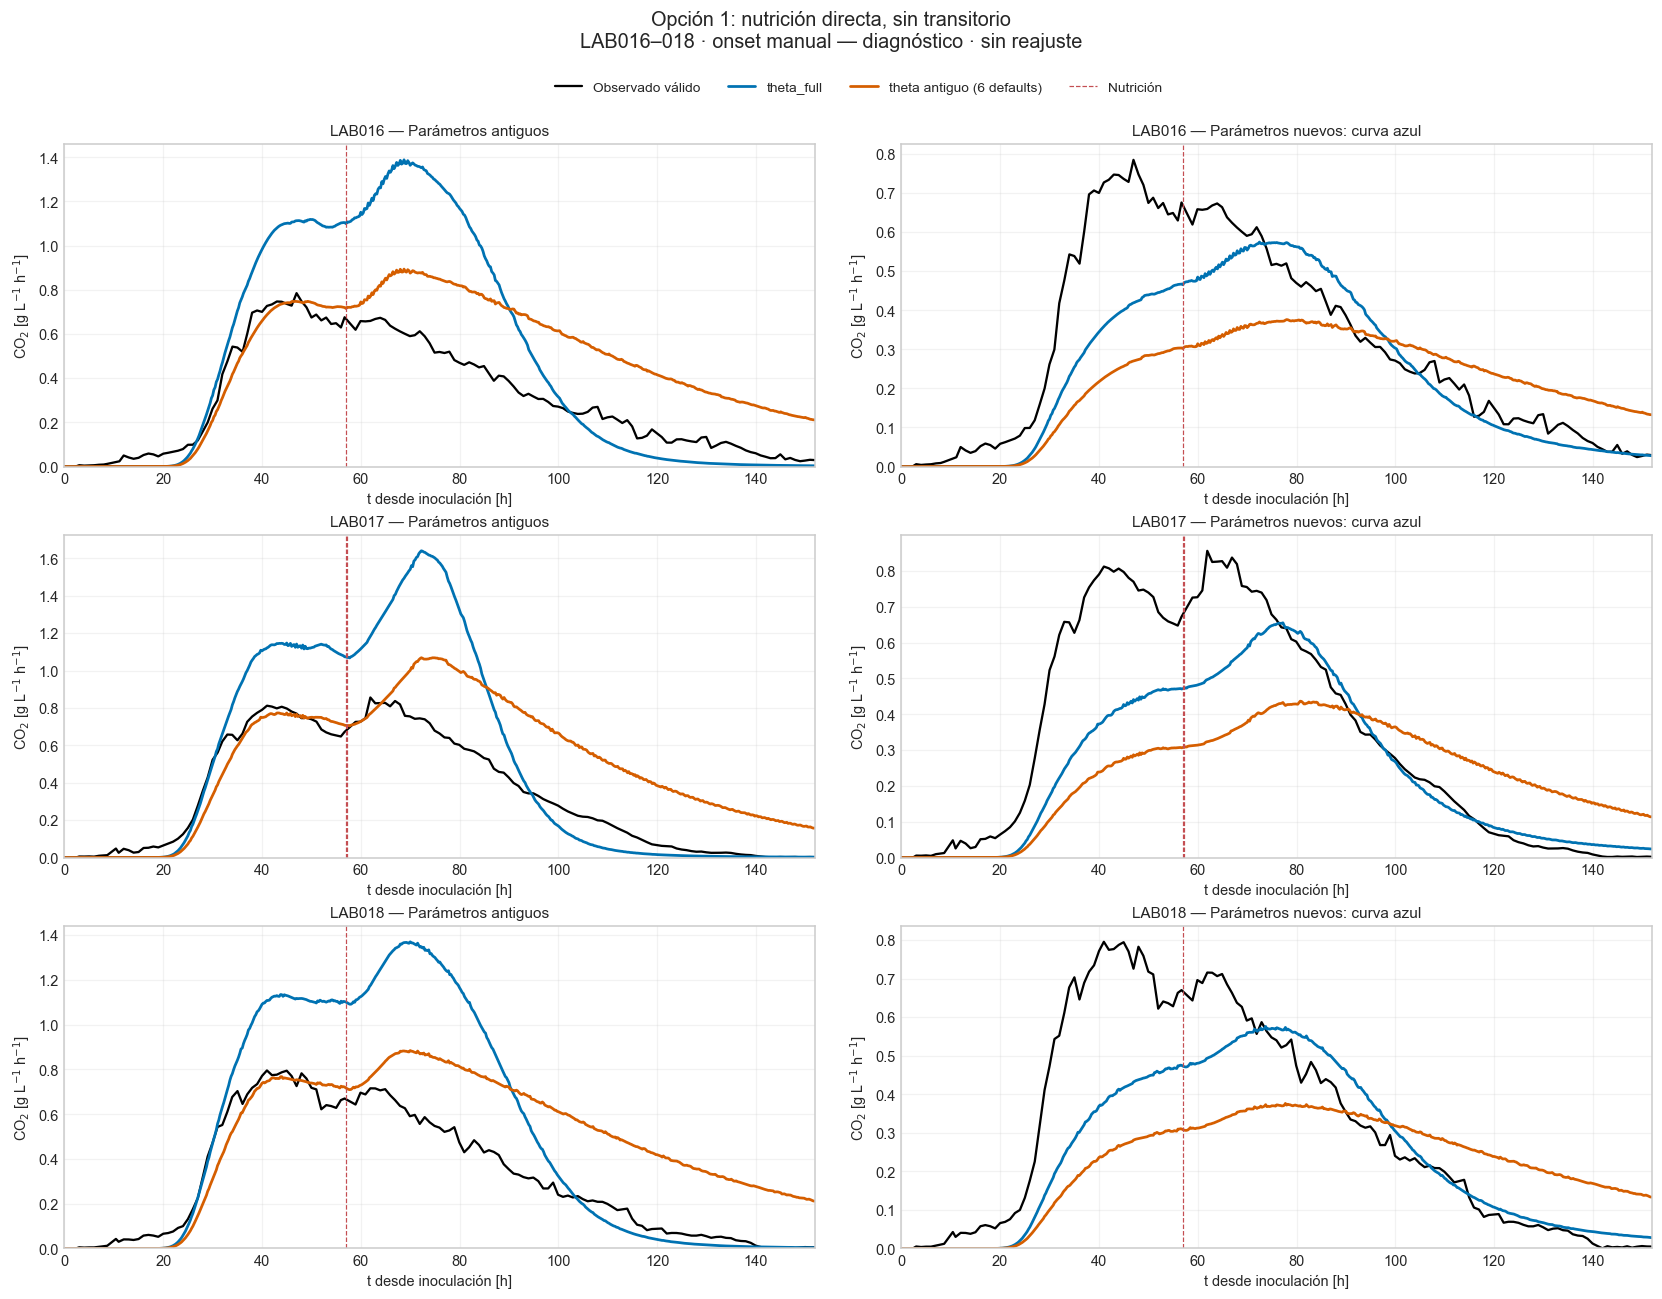

**Métricas descriptivas completas y papel de los datos:**

,lab,param_set,theta,role,RMSE_g_l_h,NRMSE_peak,onset_error_h,peak_predicted_g_l_h,AUC_relative_error
336,LAB016,antiguos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.3373,0.4298,2.0011,1.3815,0.5574
340,LAB017,antiguos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.3299,0.3854,2.0163,1.6323,0.4665
344,LAB018,antiguos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.3290,0.4137,1.9964,1.3683,0.5917
348,LAB016,antiguos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.2210,0.2816,3.0027,0.8897,0.5100
352,LAB017,antiguos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.2468,0.2884,3.0169,1.0679,0.4737
356,LAB018,antiguos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.2380,0.2993,2.9925,0.8825,0.5258
360,LAB016,nuevos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.1383,0.1762,4.0090,0.5730,-0.2165
364,LAB017,nuevos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.1739,0.2032,5.0277,0.6536,-0.2703
368,LAB018,nuevos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.1590,0.1999,4.9950,0.5713,-0.2087
372,LAB016,nuevos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.2158,0.2750,5.9858,0.3756,-0.3027


RMSE_g_l_h  NRMSE_peak
param_set theta         window                           
antiguos  theta_full    completo       0.3299      0.4137
                        pre_pulso      0.2383      0.2973
                        pulso_24h      0.6900      0.8330
                        cola           0.2018      0.2538
          theta_antiguo completo       0.2380      0.2884
                        pre_pulso      0.0725      0.0849
                        pulso_24h      0.2626      0.3150
                        cola           0.3110      0.3724
nuevos    theta_full    completo       0.1590      0.1999
                        pre_pulso      0.2403      0.2919
                        pulso_24h      0.1278      0.1607
                        cola           0.0471      0.0592
          theta_antiguo completo       0.2437      0.3065
                        pre_pulso      0.3310      0.3994
                        pulso_24h      0.2754      0.3462
                        cola           0.1178      0.1481

In [19]:
comparison.show_comparison(RESULT,BATCHES,OBSERVED,THETA_TABLE,PARAM_SETS,'directa',EXTERNAL_LABS,'onset_manual')

**Ecuaciones de esta figura — Opción 2: nutrición directa + transitorio.** Bracket **[0, onset manual observado]**: diagnóstico condicionado.

$$q_{\mathrm{bio},k}=Y_{CO_2/E}X_k\,a_\beta(T)\,\frac{1}{1+i_E(T)E_k}\left[\beta_{G0}\frac{G_k}{G_k+K_G(T)}+\beta_{F0}\frac{F_k}{F_k+K_F(T)}\frac{1}{1+i_G(T)G_k}\right],\quad k\in\{0,N\}.$$
$$K_G=\frac{\beta_{G0}}{s_G}a_K(T),\quad K_F=\frac{\beta_{F0}}{s_F}a_K(T),\quad r=\operatorname{clip}((t-t_p)/t_{rise},0,1).$$
$$ q_{\mathrm{bio}}=q_{\mathrm{bio},N},\quad X_{\mathrm{eff}}=X_N $$
$$r_{O_2}=q_{O_2,max}X_{eff}\frac{O}{0.25+O},\quad \dot O=-r_{O_2},\quad O(0)=\alpha_O O_{sat}(0),\quad \phi_{ana}=\frac{0.75^2}{0.75^2+O^2},\quad f_{ferm}=0.08+0.92\phi_{ana}.$$
$$q_{resp}=\frac{44.01}{32000}r_{O_2},\quad a=3z^2-2z^3,\quad z=\operatorname{clip}\left(\frac{t-[L+s(U-L)]}{\max(d(U-L),0.25)},0,1\right).$$
$$q_{base}=a\,[f_{ferm}q_{bio}+q_{resp}],\quad q_{prod}=M_Nq_{base},\quad M_N=1+T_N,\quad T_N=A\sum_j\frac{\Delta N_j}{0.14}\frac{(1-e^{-u_j/\tau_r})e^{-u_j/\tau_d}}{\mathcal N_j},\quad u_j=\max(t-t_j,0).$$
$$C_{sat}=s_{CO_2}1.69e^{-0.032(T-20)}e^{0.0016E_N}e^{-0.0012(G_N+F_N)},\quad q_{out}=k C\left(0.05+0.95\frac{C}{C+C_{sat}}\right),\quad \dot C=q_{prod}-q_{out},\quad q_{pred}=g_{matrix}q_{out}.$$

Se integra el pool con Euler y límite de CO2 disponible; C(0)=0. En las familias con transitorio, la normalización antigua es el máximo del kernel en la grilla de este LAB; la nueva es el máximo analítico, en u*=tau_r log(1+tau_d/tau_r). La forma del gate usa sus fracciones s/d antiguas o nuevas. Las tablas siguientes muestran los valores efectivos; los parámetros retirados se marcan como «no interviene».

La actualización implementada, con h=t_i-t_(i-1), es:
$$q_{out,i}=\min\!\left[k C_{i-1}\left(0.05+0.95\frac{C_{i-1}}{C_{i-1}+C_{sat,i}}\right),\frac{C_{i-1}}{h}+q_{prod,i-1}\right],\quad C_i=[C_{i-1}+h(q_{prod,i-1}-q_{out,i})]_+.$$


,parameter,uso,antiguos,nuevos
0,kCO2_release_h,activo,0.424588,0.096958
1,CO2sat_scale,activo,0.35139,2.5
2,O2_qmax_mg_gdw_h,activo,0.15,0.253137
3,O2_initial_scale,activo,0.1954,0.179606
4,pulse_t_rise_h,no interviene,—,—
5,pulse_activity_gain,no interviene,—,—
6,chem_activation_start_fraction,activo,0.735057,0.741575
7,chem_activation_duration_fraction,activo,1.06391,0.457773
8,matrix_gain,activo,3.115757,1.446718
9,A,activo,0.3,1.5


**Vector cinético usado por cada color (17 parámetros):**

,parameter,theta_full,theta_antiguo
0,mu0,0.078728,0.078728
1,sN,8.751446,18.000000
2,qN,0.021080,0.021080
3,qXG,0.081491,0.112500
4,qXF,0.070933,0.112500
5,betaG0,0.428878,0.428878
6,sG,0.097455,0.030000
7,betaF0,3.440399,3.440399
8,sF,0.178295,0.030000
9,qEG,1.712807,1.712807


**Condiciones iniciales comunes y eventos de esta figura:**

,lab,X,Xd,N,G,F,E,Gly
0,LAB016,0.45,0.0,0.24433,74.05,77.73,0.0,1.14
1,LAB017,0.45,0.0,0.24433,74.05,77.73,0.0,1.14
2,LAB018,0.45,0.0,0.24433,74.05,77.73,0.0,1.14


,lab,event_h,delta_N_kg_m3,dose_status
0,LAB016,56.935556,0.14,referencia supuesta
1,LAB017,56.933611,0.14,referencia supuesta
2,LAB017,57.133889,0.14,referencia supuesta
3,LAB018,56.931667,0.14,referencia supuesta


,lab,param_set,theta,gate_lower_h,gate_upper_h,gate_start_h,gate_end_h
96,LAB016,antiguos,theta_full,0.0,24.2491,17.8245,43.6233
97,LAB017,antiguos,theta_full,0.0,22.2981,16.3904,40.1135
98,LAB018,antiguos,theta_full,0.0,22.6475,16.6472,40.7421
99,LAB016,antiguos,theta_antiguo,0.0,24.2491,17.8245,43.6233
100,LAB017,antiguos,theta_antiguo,0.0,22.2981,16.3904,40.1135
101,LAB018,antiguos,theta_antiguo,0.0,22.6475,16.6472,40.7421
102,LAB016,nuevos,theta_full,0.0,24.2491,17.9825,29.0831
103,LAB017,nuevos,theta_full,0.0,22.2981,16.5357,26.7432
104,LAB018,nuevos,theta_full,0.0,22.6475,16.7948,27.1622
105,LAB016,nuevos,theta_antiguo,0.0,24.2491,17.9825,29.0831


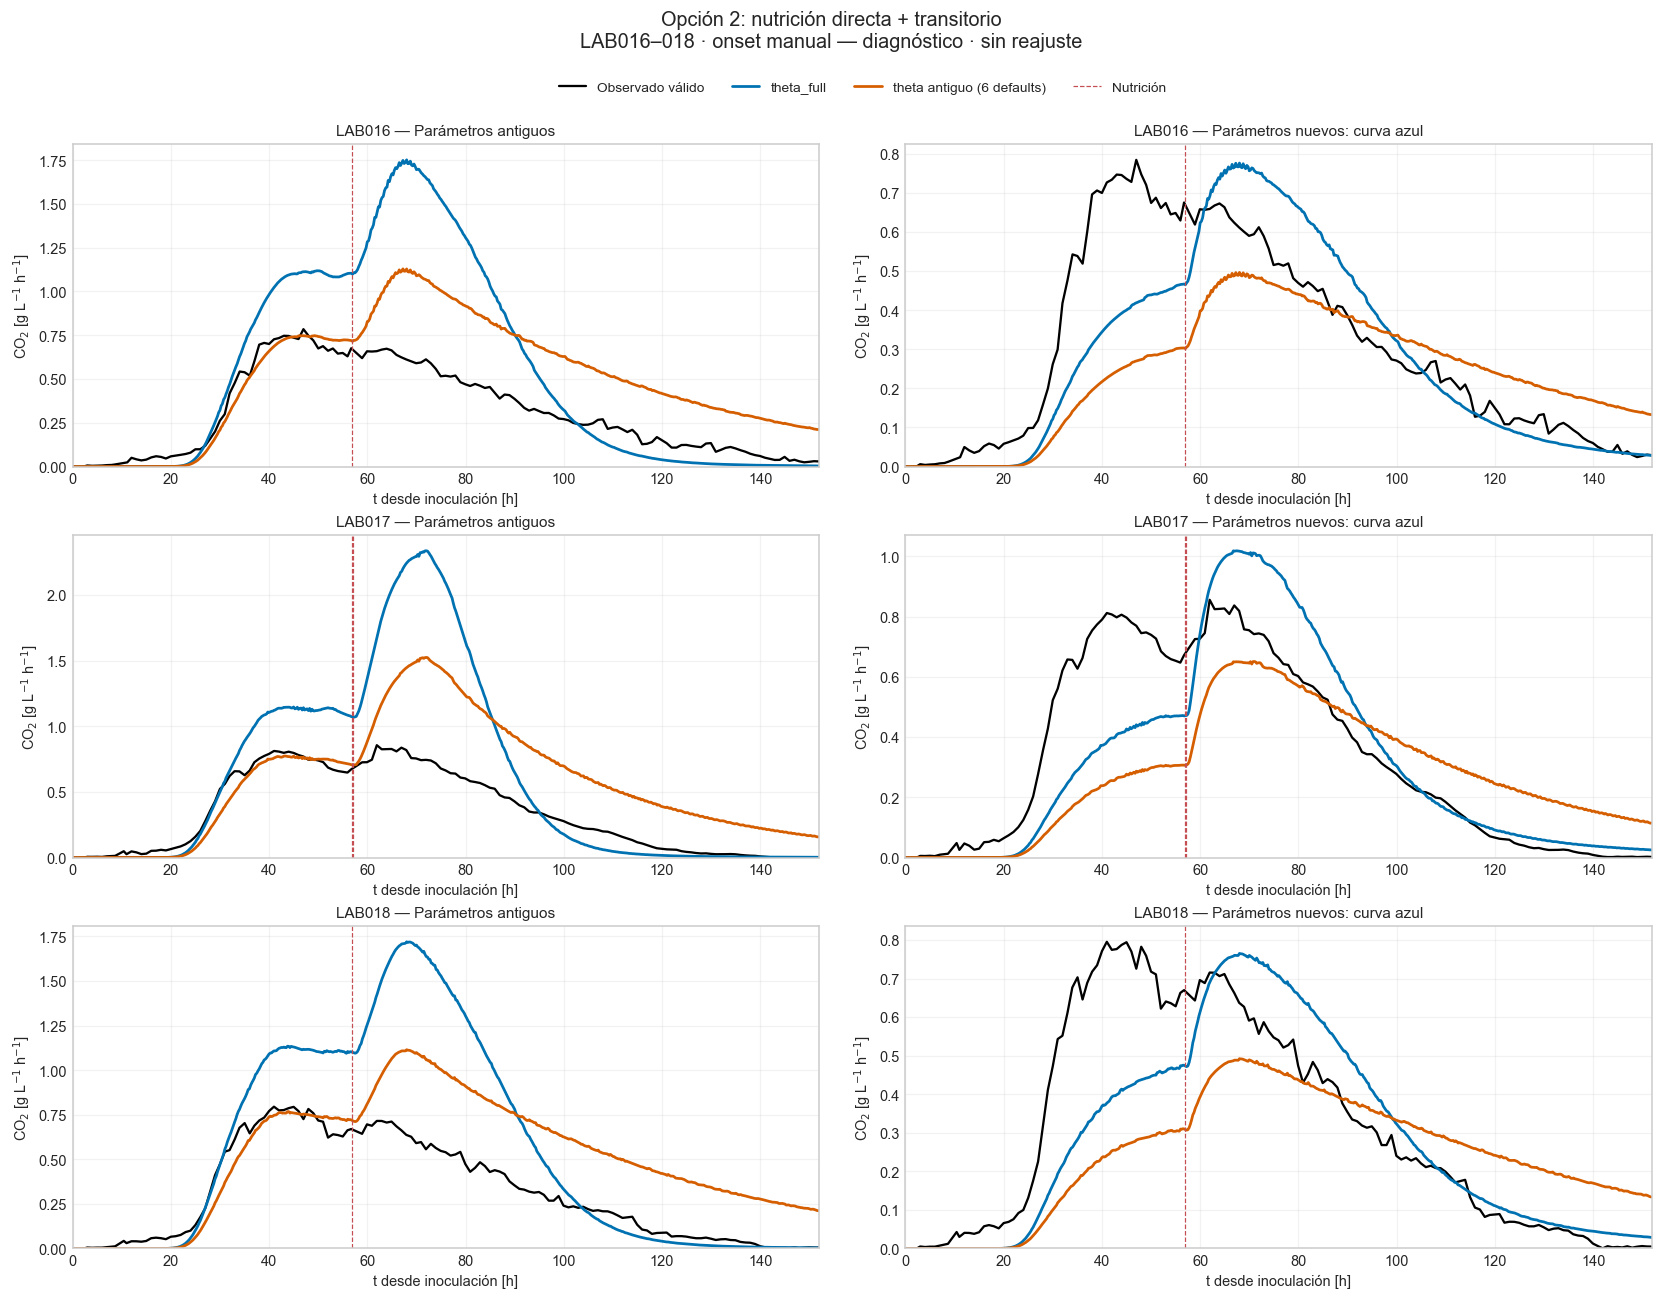

**Métricas descriptivas completas y papel de los datos:**

,lab,param_set,theta,role,RMSE_g_l_h,NRMSE_peak,onset_error_h,peak_predicted_g_l_h,AUC_relative_error
384,LAB016,antiguos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.4296,0.5474,2.0011,1.7483,0.7036
388,LAB017,antiguos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.5364,0.6268,2.0163,2.3372,0.7514
392,LAB018,antiguos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.4190,0.5268,1.9964,1.7178,0.7349
396,LAB016,antiguos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.2652,0.3379,3.0027,1.1257,0.6125
400,LAB017,antiguos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.3449,0.4030,3.0169,1.5244,0.6819
404,LAB018,antiguos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.2768,0.3481,2.9925,1.1128,0.6262
408,LAB016,nuevos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.1477,0.1882,4.0090,0.7740,-0.1070
412,LAB017,nuevos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.1815,0.2121,5.0277,1.0176,-0.0672
416,LAB018,nuevos,theta_full,Diagnóstico condicionado; no holdout predictivo,0.1635,0.2056,4.9950,0.7637,-0.1028
420,LAB016,nuevos,theta_antiguo,Diagnóstico condicionado; no holdout predictivo,0.2004,0.2554,5.9858,0.4948,-0.2315


RMSE_g_l_h  NRMSE_peak
param_set theta         window                           
antiguos  theta_full    completo       0.4296      0.5474
                        pre_pulso      0.2383      0.2973
                        pulso_24h      0.9473      1.2072
                        cola           0.2290      0.2880
          theta_antiguo completo       0.2768      0.3481
                        pre_pulso      0.0725      0.0849
                        pulso_24h      0.4244      0.5408
                        cola           0.3254      0.4091
nuevos    theta_full    completo       0.1635      0.2056
                        pre_pulso      0.2403      0.2919
                        pulso_24h      0.1465      0.1867
                        cola           0.0698      0.0859
          theta_antiguo completo       0.2291      0.2770
                        pre_pulso      0.3310      0.3994
                        pulso_24h      0.1606      0.1887
                        cola           0.1189      0.1495

In [20]:
comparison.show_comparison(RESULT,BATCHES,OBSERVED,THETA_TABLE,PARAM_SETS,'directa_transitorio',EXTERNAL_LABS,'onset_manual')

## Chequeo de la cinética con química medida — LAB019–021

La capa de CO2 no altera la simulación cinética. Se comparan G+F, E y N de ambos theta con la química disponible, incluida m12. No se ajustan estados ni se infiere química de Brix/densidad.

**Ecuaciones y parámetros de esta figura de estados cinéticos.** La capa de CO2 no modifica estos estados; son comunes a las tres familias para un mismo theta.

$$\dot X=(\mu-k_d)X,\quad \dot X_d=k_dX,\quad \dot N=-q_N f_N X,\quad f_N=a_\mu(T)\frac{N}{N+K_N(T)}.$$
$$\dot G=-X[q_{XG}f_N+q_{EG}\varphi_G+m(T)\chi\,G/(G+F)],\quad \dot F=-X[q_{XF}f_N+q_{EF}\varphi_F+m(T)\chi\,F/(G+F)].$$
$$\dot E=X(\beta_{G0}\varphi_G+\beta_{F0}\varphi_F),\quad \dot{Gly}=X(\gamma_{G0}\varphi_G+\gamma_{F0}\varphi_F),\quad \chi=(G+F)/(G+F+1).$$
$$\mu=\mu_0 f_N,\quad \varphi_G=a_\beta\frac{G}{G+K_G}\frac{1}{1+i_E(T)E},\quad \varphi_F=a_\beta\frac{F}{F+K_F}\frac{1}{1+i_G(T)G}\frac{1}{1+i_E(T)E}.$$
$$T_d(E)=-0.0001E^3+0.0049E^2-0.1279E+315.89,\quad k_d=\begin{cases}K_{d0}\exp\!\left[\frac{C_{de}E+E_{td}(T_K-305.65)}{305.65RT_K}\right],&T_K\ge T_d(E),\\0,&T_K<T_d(E).\end{cases}$$

Los factores de fermentación son los definidos en las figuras de CO2; N recibe saltos exactos en los eventos publicados. No se ajusta theta con estos datos. Las ICs y dosis son las mismas que en las figuras LAB019–021.


,parameter,theta_full,theta_antiguo
0,mu0,0.078728,0.078728
1,sN,8.751446,18.000000
2,qN,0.021080,0.021080
3,qXG,0.081491,0.112500
4,qXF,0.070933,0.112500
5,betaG0,0.428878,0.428878
6,sG,0.097455,0.030000
7,betaF0,3.440399,3.440399
8,sF,0.178295,0.030000
9,qEG,1.712807,1.712807


,lab,X,Xd,N,G,F,E,Gly
0,LAB019,0.8595,0.029997,0.260025,79.19,78.97,12.075372,1.22
1,LAB020,0.4113,0.004607,0.255556,77.94,79.52,11.917524,1.38
2,LAB021,0.3999,0.018435,0.261202,80.19,81.04,11.759676,1.28


,lab,event_h,delta_N_kg_m3
0,LAB019,64.333333,0.08
1,LAB020,71.666667,0.08
2,LAB021,47.500000,0.08


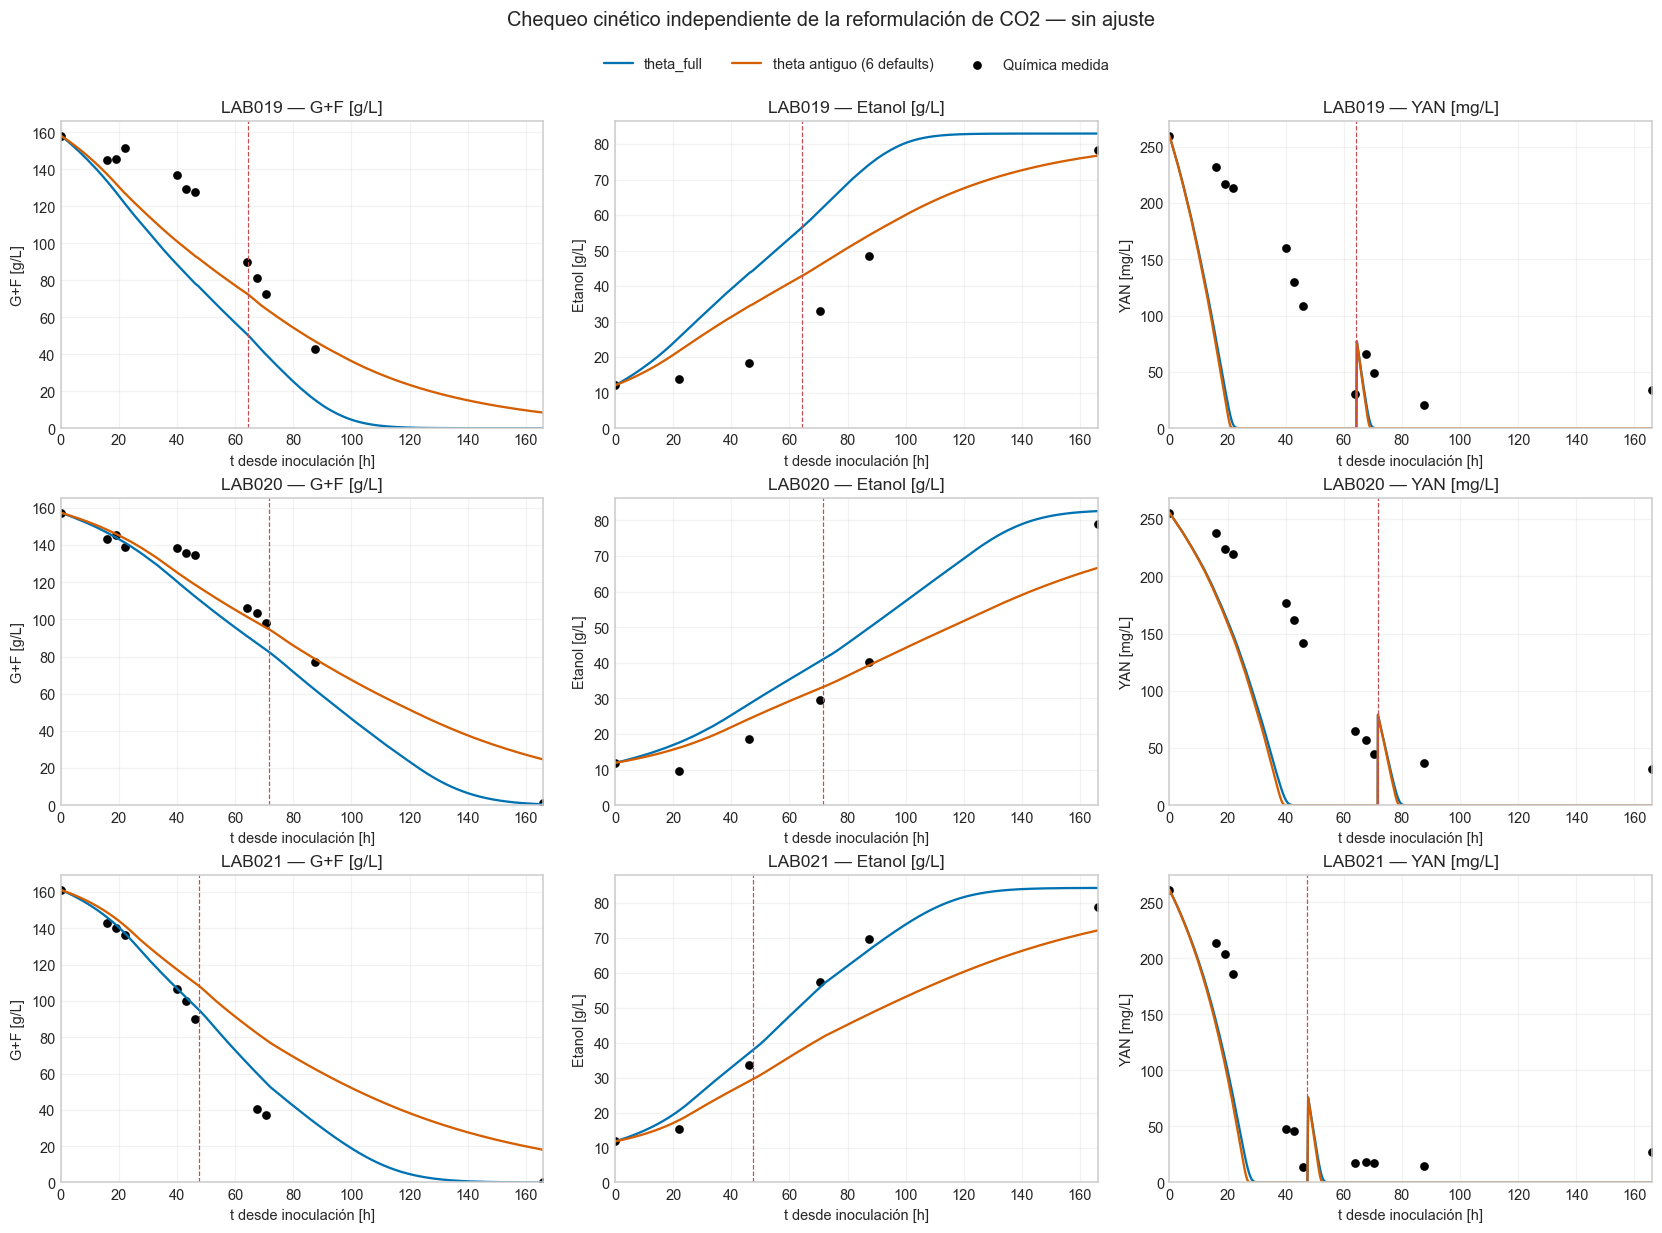

In [21]:
comparison.show_chemistry(RESULT,BATCHES,chem,THETA_TABLE)

## Lectura de los resultados e integridad

Las métricas son descriptivas y no convierten datos de calibración previa en holdout. Un deterioro al retirar rampa/gain puede indicar que los parámetros del pool compensaban esa estructura: esta prueba congelada no sustituye un eventual reajuste comparable de ambas opciones. Se conserva el transitorio en opción 2; no se fuerza su desaparición ni se estima uno nuevo.

In [22]:
main = RESULT['metrics'].query('mode == "gate_predicho" and window == "completo"').copy()
main['group'] = np.where(main.lab.isin(EXTERNAL_LABS),'LAB016–018','LAB019–021')
display(main.groupby(['group','family','param_set','theta'],sort=False)[['RMSE_g_l_h','NRMSE_peak','AUC_relative_error']].median().round(4))
assert protected_before == {str(path):comparison.file_hash(path) for path in PROTECTED_PATHS}
assert set(BATCHES) == set(EXTERNAL_LABS + RECENT_LABS)
assert len(RESULT['curves']) == 108
assert set(THETA_SETS['theta_full']) == set(base.FULL17)
print('Artefactos anteriores y datos protegidos intactos. No se escribieron CSV ni imágenes en results.')
print('Sin reajuste; 72 curvas principales y 36 curvas diagnósticas con onset manual.')
assert len(RECENT_MANUAL_RESULT['curves']) == 6
assert comparison.file_hash(recent_onset_reference_path) == recent_onset_reference_hash
print('Figura adicional: 6 curvas LAB019–021 con onset manual, parámetros antiguos y ambos theta.')


,,,,RMSE_g_l_h,NRMSE_peak,AUC_relative_error
group,family,param_set,theta,,,
LAB016–018,vigente,antiguos,theta_full,0.4272,0.5187,0.8227
LAB019–021,vigente,antiguos,theta_full,0.3245,0.6285,1.2996
LAB016–018,vigente,antiguos,theta_antiguo,0.2046,0.2573,0.4005
LAB019–021,vigente,antiguos,theta_antiguo,0.2047,0.3809,0.7086
LAB016–018,vigente,nuevos,theta_full,0.1094,0.1364,-0.1195
LAB019–021,vigente,nuevos,theta_full,0.1370,0.1975,0.0245
LAB016–018,vigente,nuevos,theta_antiguo,0.1931,0.2399,-0.3438
LAB019–021,vigente,nuevos,theta_antiguo,0.1391,0.2182,-0.2624
LAB016–018,directa,antiguos,theta_full,0.4571,0.5747,1.0216


Artefactos anteriores y datos protegidos intactos. No se escribieron CSV ni imágenes en results.
Sin reajuste; 72 curvas principales y 36 curvas diagnósticas con onset manual.
Figura adicional: 6 curvas LAB019–021 con onset manual, parámetros antiguos y ambos theta.
